In [1]:
# ==============================================================================
# CELL 1: TILTROTOR DESIGNER & AEROMECHANICS ENGINE (DYNAMIC STALL LINKED)
# ==============================================================================

import glob
import os
import urllib.request
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple
from IPython.display import HTML, display
import ipywidgets as widgets
import matplotlib.pyplot as plt
import mpl_toolkits.mplot3d.art3d as art3d
import numpy as np
import pandas as pd
from scipy.interpolate import RectBivariateSpline
from scipy.optimize import brentq, curve_fit

FUSE_LEN, FUSE_W, FUSE_H, N_ROTORS = 15.20, 2.15, 2.05, 2
d_eq = np.sqrt((4.0 / np.pi) * FUSE_W * FUSE_H)
fineness = max(FUSE_LEN / d_eq, 3.0)
S_WET_FUSE = np.pi * d_eq * FUSE_LEN * (1.0 - 2.0 / fineness) ** (2 / 3) * (1.0 + 1.0 / (fineness**2))


def isa_atmosphere(altitude_m: float, delta_t: float = 0.0) -> Tuple[float, float, float, float]:
    alt = np.clip(altitude_m, 0.0, 11000.0)
    T_std = 288.15 - 0.0065 * alt
    T = T_std + delta_t
    P = 101325.0 * ((T_std / 288.15) ** 5.2561)
    rho = P / (287.058 * T)
    a = np.sqrt(1.4 * 287.058 * T)
    mu = 1.789e-5 * ((T / 288.15) ** 1.5) * ((288.15 + 110.4) / (T + 110.4))
    return rho, a, T, mu


benchmarks = pd.DataFrame(
    {
        "Aircraft": ["Bell XV-3", "Curtiss-Wright X-19", "CL-84 Dynavert", "Bell XV-15", "Leonardo AW609", "Bell V-280 Valor", "LTV XC-142", "Bell Boeing V-22"],
        "MTOW_kg": [2177.0, 6196.0, 5715.0, 6000.0, 8165.0, 14000.0, 20185.0, 23982.0],
        "Empty_kg": [1648.0, 4527.0, 3818.0, 4570.0, 4765.0, 8200.0, 10250.0, 15032.0],
        "Disc_Loading": [32.5, 145.0, 102.0, 73.2, 88.4, 95.0, 135.0, 102.5],
        "Solidity": [0.053, 0.115, 0.102, 0.089, 0.096, 0.100, 0.110, 0.105],
        "Installed_PW": [0.154, 0.410, 0.440, 0.385, 0.354, 0.533, 0.450, 0.380],
        "Service_Ceiling_m": [3600.0, 5330.0, 4880.0, 8840.0, 7620.0, 8500.0, 7600.0, 7620.0],
    }
)
benchmarks["We_W0"] = benchmarks["Empty_kg"] / benchmarks["MTOW_kg"]


def power_law(x, a, b):
    return a * (x**b)


def linear_law(x, a, b):
    return a * x + b


popt_we, _ = curve_fit(power_law, benchmarks["MTOW_kg"].values, benchmarks["We_W0"].values, p0=[1.5, -0.09])
popt_pw, _ = curve_fit(power_law, benchmarks["Disc_Loading"].values, benchmarks["Installed_PW"].values, p0=[0.05, 0.5])
popt_sol, _ = curve_fit(linear_law, benchmarks["Disc_Loading"].values, benchmarks["Solidity"].values, p0=[0.001, 0.02])
popt_ceil, _ = curve_fit(linear_law, benchmarks["Service_Ceiling_m"].values, benchmarks["Installed_PW"].values, p0=[5e-5, 0.1])

_COORDS_CACHE: Dict[str, Tuple[np.ndarray, np.ndarray]] = {}


def to_airfoiltools_slug(name: str) -> str:
    clean = name.lower().strip().replace(" ", "").replace("-", "").replace("_", "").replace("(", "").replace(")", "")
    known_mappings = {
        "clarky": "clarky-il",
        "clarkyh": "clarkyh-il",
        "goe398": "goe398-il",
        "goe535": "goe535-il",
        "usa35b": "usa35b-il",
        "boeingvertolvr12": "vr12-il",
        "nasasc20010": "sc20010-il",
        "nasasc20012": "sc20012-il",
        "nasasc20410": "sc20410-il",
        "nasasc20412": "sc20412-il",
        "naca64a010": "naca64a010-il",
        "naca64a012": "n64012a-il",
        "oneraoa209": "oa209-il",
        "oneraoa212": "oa212-il",
        "sikorskysc1095": "sc1095-il",
    }
    if clean in known_mappings:
        return known_mappings[clean]
    if clean.startswith("naca"):
        return f"n{clean.replace('naca', '')}-il"
    return f"{clean}-il" if not (clean.endswith("il") or clean.endswith("sa")) else clean


def ensure_airfoil_data(airfoil_name: str, airfoil_dir: str = "airfoils"):
    os.makedirs(airfoil_dir, exist_ok=True)
    slug = to_airfoiltools_slug(airfoil_name)
    target_dir = os.path.join(airfoil_dir, slug)
    os.makedirs(target_dir, exist_ok=True)
    dat_path = os.path.join(target_dir, f"{slug}.dat")
    if not os.path.exists(dat_path):
        try:
            url_dat = f"http://airfoiltools.com/airfoil/seligdatfile?airfoil={slug}"
            req = urllib.request.Request(url_dat, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=3) as resp:
                content = resp.read().decode("utf-8")
                if len(content) > 100 and "<html>" not in content.lower():
                    with open(dat_path, "w") as f:
                        f.write(content)
        except Exception:
            pass
    for re_v in [50000, 100000, 200000, 500000, 1000000]:
        for nc_str, nc_tag in [("", ""), ("-n5", "-n5")]:
            csv_path = os.path.join(target_dir, f"xf-{slug}-{re_v}{nc_tag}.csv")
            if not os.path.exists(csv_path):
                try:
                    url_csv = f"http://airfoiltools.com/polar/csv?polar=xf-{slug}-{re_v}{nc_str}"
                    req = urllib.request.Request(url_csv, headers={"User-Agent": "Mozilla/5.0"})
                    with urllib.request.urlopen(req, timeout=3) as resp:
                        content = resp.read().decode("utf-8")
                        if "alpha" in content.lower() and "cl" in content.lower():
                            with open(csv_path, "w") as f:
                                f.write(content)
                except Exception:
                    pass


def load_airfoil_coords(airfoil_name: str) -> Tuple[np.ndarray, np.ndarray]:
    if airfoil_name in _COORDS_CACHE:
        return _COORDS_CACHE[airfoil_name]
    ensure_airfoil_data(airfoil_name)
    slug = to_airfoiltools_slug(airfoil_name)
    for d in ["airfoils", "."]:
        for fpath in glob.glob(os.path.join(d, "**", "*.dat"), recursive=True):
            if slug.replace("-il", "") in os.path.basename(fpath).lower():
                raw_x, raw_y = [], []
                with open(fpath, "r") as f:
                    for line in f.readlines()[1:]:
                        p = line.strip().split()
                        if len(p) == 2:
                            try:
                                raw_x.append(float(p[0]))
                                raw_y.append(float(p[1]))
                            except ValueError:
                                continue
                if len(raw_x) > 10:
                    coords = (np.array(raw_x), np.array(raw_y))
                    _COORDS_CACHE[airfoil_name] = coords
                    return coords
    beta = np.linspace(0, np.pi, 30)
    x = 0.5 * (1.0 - np.cos(beta))
    yt = 5.0 * 0.12 * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * (x**2) + 0.2843 * (x**3) - 0.1015 * (x**4))
    coords = (np.concatenate([x[::-1], x[1:]]), np.concatenate([yt[::-1], -yt[1:]]))
    _COORDS_CACHE[airfoil_name] = coords
    return coords


class AirfoilModel:
    def __init__(self, airfoil_name: str = "NACA 0012", ncrit: int = 9):
        self.airfoil_name = airfoil_name
        self.ncrit = ncrit
        self.has_polars = False
        self.re_list = []
        self.raw_data = {}
        self.alpha_stall_deg = 14.0  # Dynamic fallback
        self.cl_max = 1.2
        ensure_airfoil_data(airfoil_name)
        self._build_polar_interpolators()

    def _build_polar_interpolators(self):
        slug = to_airfoiltools_slug(self.airfoil_name).replace("-il", "")
        for fpath in glob.glob(os.path.join("airfoils", "**", "*.csv"), recursive=True):
            if slug in os.path.basename(fpath).lower():
                try:
                    df = pd.read_csv(fpath, skiprows=10)
                    df.columns = [c.strip().lower() for c in df.columns]
                    if "alpha" in df.columns and "cl" in df.columns and "cd" in df.columns:
                        re_val = float(os.path.basename(fpath).split("-")[-1].replace(".csv", "").replace("n5", ""))
                        self.raw_data[re_val] = df[["alpha", "cl", "cd"]].rename(columns={"cl": "CL", "cd": "CD"})
                except Exception:
                    pass
        if self.raw_data:
            self.re_list = sorted(self.raw_data.keys())
            
            # Dynamically identify stall angle & CL_max from the reference Re=500k polar
            ref_re = min(self.re_list, key=lambda x: abs(x - 500000))
            ref_df = self.raw_data[ref_re]
            idx_cl_max = ref_df["CL"].astype(float).idxmax()
            self.alpha_stall_deg = float(ref_df.loc[idx_cl_max, "alpha"])
            self.cl_max = float(ref_df.loc[idx_cl_max, "CL"])

            alpha_common = np.linspace(np.radians(-15.0), np.radians(20.0), 71)
            cl_grid = np.zeros((len(alpha_common), len(self.re_list)))
            cd_grid = np.zeros((len(alpha_common), len(self.re_list)))
            for j, re_v in enumerate(self.re_list):
                df = self.raw_data[re_v]
                a_rad = np.radians(df["alpha"].values.astype(float))
                cl_grid[:, j] = np.interp(alpha_common, a_rad, df["CL"].values.astype(float))
                cd_grid[:, j] = np.interp(alpha_common, a_rad, df["CD"].values.astype(float))
            self.spline_cl = RectBivariateSpline(alpha_common, np.log10(self.re_list), cl_grid, kx=2, ky=min(len(self.re_list) - 1, 2))
            self.spline_cd = RectBivariateSpline(alpha_common, np.log10(self.re_list), cd_grid, kx=2, ky=min(len(self.re_list) - 1, 2))
            self.has_polars = True

    def evaluate(self, alpha_rad: np.ndarray, re_arr: np.ndarray, mach_arr: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        alpha_deg = np.degrees(alpha_rad)
        valid_mask = (alpha_deg >= -15.0) & (alpha_deg <= 20.0)
        if self.has_polars:
            log_re = np.log10(np.clip(re_arr, 1e4, 1e7))
            cl = self.spline_cl.ev(alpha_rad, log_re)
            cd = self.spline_cd.ev(alpha_rad, log_re)
            cl_stall = (self.cl_max * 0.95) * np.sin(2.0 * alpha_rad)
            cd_stall = 0.015 + 1.25 * (np.sin(alpha_rad) ** 2)
            cl = np.where(valid_mask, cl, cl_stall)
            cd = np.where(valid_mask, cd, cd_stall)
        else:
            cl = 5.75 * np.sin(alpha_rad)
            cd = 0.011 + 1.25 * (np.sin(alpha_rad) ** 2)
        mach_clipped = np.clip(mach_arr, 0.0, 0.88)
        beta = np.sqrt(np.maximum(0.20, 1.0 - mach_clipped**2))
        return cl / beta, cd / beta, valid_mask


@dataclass
class BEMTResult:
    thrust_N: float
    torque_Nm: float
    power_kW: float
    CT: float
    CP: float
    FM: float
    eta_prop: float
    r_stations: np.ndarray
    chords: np.ndarray
    thetas_deg: np.ndarray
    phi_deg: np.ndarray
    alpha_deg: np.ndarray
    lambda_i: np.ndarray
    dCT_dr: np.ndarray
    dCP_dr: np.ndarray
    lambda_tot: np.ndarray = None
    cl: np.ndarray = None
    cd: np.ndarray = None
    re_r: np.ndarray = None
    dt_dr: np.ndarray = None
    dp_dr: np.ndarray = None
    dq_dr: np.ndarray = None
    mach_helical: float = 0.0
    valid_fraction: float = 1.0


def run_bemt_solver(
    radius: float,
    root_cutout: float,
    num_blades: int,
    c_root: float,
    taper: float,
    pitch_75_deg: float,
    twist_deg: float,
    rpm: float,
    v_axial_ms: float,
    airfoil: AirfoilModel,
    rho: float = 1.225,
    a_sound: float = 340.3,
    mu: float = 1.789e-5,
    num_elements: int = 30,
) -> BEMTResult:
    r_edges = np.linspace(root_cutout, radius, num_elements + 1)
    r_stations = 0.5 * (r_edges[:-1] + r_edges[1:])
    dr = np.diff(r_edges)
    r_norm = r_stations / radius
    chords = c_root + (c_root * taper - c_root) * ((r_stations - root_cutout) / max(1e-4, radius - root_cutout))
    thetas = np.radians(pitch_75_deg + twist_deg * (r_norm - 0.75))
    omega = rpm * 2.0 * np.pi / 60.0
    v_tip = omega * radius
    lambda_c = v_axial_ms / max(v_tip, 1e-4)
    sigma_r = (num_blades * chords) / (np.pi * radius)
    mach_r = np.sqrt((omega * r_stations)**2 + v_axial_ms**2) / a_sound
    lambda_tot = np.full_like(r_stations, max(lambda_c, 1e-4) + 0.02)
    relax = 0.25

    for _ in range(70):
        f = (num_blades / 2.0) * (1.0 - r_norm) / np.maximum(np.abs(lambda_tot), 1e-4)
        f_loss = np.maximum((2.0 / np.pi) * np.arccos(np.exp(-np.clip(f, 0.0, 30.0))), 1e-3)
        u_t = omega * r_stations
        u_p = lambda_tot * v_tip
        phi = np.arctan2(u_p, np.maximum(u_t, 1e-4))
        alpha = thetas - phi
        u_res_sq = u_t**2 + u_p**2
        re_r = (rho * np.sqrt(u_res_sq) * chords) / max(mu, 1e-6)
        cl, cd, valid_mask = airfoil.evaluate(alpha, re_r, mach_r)
        C_y = cl * np.cos(phi) - cd * np.sin(phi)
        K = ((sigma_r / (8.0 * f_loss * np.maximum(r_norm, 0.05)))* (u_res_sq / max(v_tip**2, 1e-4))* C_y)
        discriminant = (lambda_c / 2.0) ** 2 + K
        lambda_i_new = np.where(discriminant >= 0.0, -lambda_c / 2.0 + np.sqrt(np.maximum(0.0, discriminant)), -lambda_c / 2.0)
        lambda_tot_new = np.clip(lambda_c + lambda_i_new, 1e-4, 3.5)
        err = np.max(np.abs(lambda_tot_new - lambda_tot))
        if err < 1e-5:
            lambda_tot = lambda_tot_new
            break
        lambda_tot = (1.0 - relax) * lambda_tot + relax * lambda_tot_new

    dt_dr = num_blades * 0.5 * rho * u_res_sq * chords * (cl * np.cos(phi) - cd * np.sin(phi))
    dfx_dr = num_blades * 0.5 * rho * u_res_sq * chords * (cd * np.cos(phi) + cl * np.sin(phi))
    thrust = np.sum(dt_dr * dr)
    torque = np.sum(r_stations * dfx_dr * dr)
    power = omega * torque
    disk_area = np.pi * (radius**2)
    n_rps = rpm / 60.0
    d_prop = 2.0 * radius
    ct = thrust / max(rho * (n_rps**2) * (d_prop**4), 1e-6)
    cp = power / max(rho * (n_rps**3) * (d_prop**5), 1e-6)
    if thrust > 10.0 and power > 10.0 and v_axial_ms == 0.0:
        p_ideal_w = (max(thrust, 0.0) ** 1.5) / np.sqrt(2.0 * rho * disk_area)
        fm = p_ideal_w / max(power, 1e-3)
    else:
        fm = 0.0
    if v_axial_ms > 1.0 and thrust > 10.0 and power > 50.0:
        eta = float(np.clip((thrust * v_axial_ms) / power, 0.0, 1.00))
    else:
        eta = float("nan")
    return BEMTResult(
        thrust_N=thrust,
        torque_Nm=torque,
        power_kW=power * 1e-3,
        CT=ct,
        CP=cp,
        FM=fm,
        eta_prop=eta,
        r_stations=r_stations,
        chords=chords,
        thetas_deg=np.degrees(thetas),
        phi_deg=np.degrees(phi),
        alpha_deg=np.degrees(alpha),
        lambda_i=(lambda_tot - lambda_c),
        lambda_tot=lambda_tot,
        cl=cl,
        cd=cd,
        re_r=re_r,
        dt_dr=dt_dr,
        dp_dr=(omega * r_stations * dfx_dr),
        dq_dr=(r_stations * dfx_dr),
        dCT_dr=dt_dr / (rho * (omega**2) * (radius**4) * np.pi * dr / radius),
        dCP_dr=((omega * r_stations * dfx_dr) / (rho * (omega**3) * (radius**5) * np.pi * dr / radius)),
        mach_helical=mach_r,
        valid_fraction=float(np.mean(valid_mask)),
    )


def trim_rotor_collective(
    target_thrust_n: float,
    radius: float,
    root_cutout: float,
    num_blades: int,
    c_root: float,
    taper: float,
    twist_deg: float,
    rpm: float,
    v_axial_ms: float,
    airfoil: AirfoilModel,
    rho: float,
    a_sound: float,
    mu: float,
    pitch_bounds: Tuple[float, float] = (-10.0, 70.0),
) -> Tuple[float, Optional[BEMTResult], bool]:
    def residual(th_guess):
        res = run_bemt_solver(radius, root_cutout, num_blades, c_root, taper, th_guess, twist_deg, rpm, v_axial_ms, airfoil, rho, a_sound, mu, num_elements=30)
        if np.isnan(res.thrust_N):
            return 1e9
        return res.thrust_N - target_thrust_n

    f_a, f_b = residual(pitch_bounds[0]), residual(pitch_bounds[1])
    th_opt, is_exact = float("nan"), False
    if f_a * f_b <= 0:
        try:
            th_opt = brentq(residual, pitch_bounds[0], pitch_bounds[1], xtol=0.03, maxiter=35)
            is_exact = True
        except Exception:
            th_opt = float("nan")
    if np.isnan(th_opt):
        th_coarse = np.linspace(pitch_bounds[0], pitch_bounds[1], 45)
        errs = [abs(residual(p)) for p in th_coarse]
        th_opt = float(th_coarse[np.argmin(errs)])
        is_exact = False
    trimmed_bemt = run_bemt_solver(radius, root_cutout, num_blades, c_root, taper, th_opt, twist_deg, rpm, v_axial_ms, airfoil, rho, a_sound, mu, num_elements=30)
    err_rel = abs(trimmed_bemt.thrust_N - target_thrust_n) / max(target_thrust_n, 1.0)
    if err_rel <= 0.05 and not np.isnan(trimmed_bemt.thrust_N):
        is_exact = True
    return th_opt, trimmed_bemt, is_exact


style_w = {"description_width": "160px"}
layout_w = widgets.Layout(width="340px", margin="1px 0px")
full_airfoil_catalog = [
    "Boeing-Vertol VR-12",
    "NASA SC(2)-0010",
    "NASA SC(2)-0012",
    "NASA SC(2)-0410",
    "NASA SC(2)-0412",
    "NACA 0009",
    "NACA 0012",
    "NACA 23012",
    "NACA 23015",
    "NACA 64-A010",
    "NACA 64-A012",
    "ONERA OA209",
    "ONERA OA212",
    "Sikorsky SC1095",
    "NACA 0015",
    "NACA 0018",
    "NACA 2412",
    "NACA 4412",
    "NACA 4415",
    "Clark Y",
    "Clark YH",
    "USA 35B",
]
w_airfoil = widgets.Dropdown(options=full_airfoil_catalog, value="Boeing-Vertol VR-12", description="Rotor Airfoil:", style=style_w, layout=layout_w)
w_re_explore = widgets.FloatLogSlider(value=500000, base=10, min=4.7, max=6.0, step=0.05, description="Explore Re:", style=style_w, layout=layout_w, continuous_update=False)
w_radius = widgets.FloatSlider(value=4.60, min=2.5, max=6.5, step=0.01, description="Rotor Radius R [m]:", style=style_w, layout=layout_w, continuous_update=False)
w_root_pct = widgets.FloatSlider(value=10.0, min=5.0, max=30.0, step=0.5, description="Root Cutout [% R]:", style=style_w, layout=layout_w, continuous_update=False)
w_nblades = widgets.IntSlider(value=3, min=2, max=6, step=1, description="Number of Blades Nb:", style=style_w, layout=layout_w, continuous_update=False)
w_chord = widgets.FloatSlider(value=0.50, min=0.15, max=0.85, step=0.01, description="Root Chord c_0 [m]:", style=style_w, layout=layout_w, continuous_update=False)
w_taper = widgets.FloatSlider(value=0.75, min=0.30, max=1.00, step=0.05, description="Blade Taper (c_tip/c_root):", style=style_w, layout=layout_w, continuous_update=False)
w_twist = widgets.FloatSlider(value=-30.0, min=-45.0, max=0.0, step=0.5, description="Blade Twist [°]:", style=style_w, layout=layout_w, continuous_update=False)
w_rpm_hov = widgets.FloatSlider(value=535.0, min=200.0, max=800.0, step=5.0, description="Hover RPM:", style=style_w, layout=layout_w, continuous_update=False)
w_rpm_cr = widgets.FloatSlider(value=200.0, min=100.0, max=600.0, step=5.0, description="Cruise RPM:", style=style_w, layout=layout_w, continuous_update=False)
w_s_wing = widgets.FloatSlider(value=43.0, min=12.0, max=50.0, step=0.5, description="Wing Area [m²]:", style=style_w, layout=layout_w, continuous_update=False)
w_ar = widgets.FloatSlider(value=9.3, min=4.0, max=14.0, step=0.1, description="Wing Aspect Ratio:", style=style_w, layout=layout_w, continuous_update=False)
w_taper_w = widgets.FloatSlider(value=0.65,min=0.30,max=1.00,step=0.05,description="Wing Taper (c_tip/c_root):",style=style_w,layout=layout_w,continuous_update=False)
# Tail Volume & Aspect Ratio Sliders
w_vh = widgets.FloatSlider(value=0.85,min=0.50,max=1.30,step=0.05,description="Horiz Tail Vh:",style=style_w,layout=layout_w, continuous_update=False)
w_vv = widgets.FloatSlider(value=0.075,min=0.03,max=0.12,step=0.005,description="Vert Tail Vv:",style=style_w,layout=layout_w,continuous_update=False)
w_ar_ht = widgets.FloatSlider(value=4.2,min=2.5,max=6.5,step=0.1,description="Horiz Tail AR:",style=style_w,layout=layout_w,continuous_update=False)
w_ar_vt = widgets.FloatSlider(value=1.6,min=1.0,max=3.0,step=0.1,description="Vert Tail AR:",style=style_w,layout=layout_w,continuous_update=False)


w_payload = widgets.FloatSlider(value=1500.0, min=500.0, max=4000.0, step=50.0, description="Payload Mass [kg]:", style=style_w, layout=layout_w, continuous_update=False)
w_v_max = widgets.FloatSlider(value=450.0, min=350.0, max=450.0, step=10.0, description="Max Speed Vmax [km/h]:", style=style_w, layout=layout_w, continuous_update=False)
w_v_cruise = widgets.FloatSlider(value=400.0, min=150.0, max=450.0, step=10.0, description="Cruise Speed Vcr [km/h]:", style=style_w, layout=layout_w, continuous_update=False)
w_h_cruise = widgets.FloatSlider(value=3000.0, min=0.0, max=7000.0, step=100.0, description="Cruise Altitude [m]:", style=style_w, layout=layout_w, continuous_update=False)
w_range = widgets.FloatSlider(value=1000.0, min=500.0, max=2000.0, step=50.0, description="Mission Range [km]:", style=style_w, layout=layout_w, continuous_update=False)
w_ceiling = widgets.FloatSlider(value=7000.0, min=4000.0, max=9000.0, step=250.0, description="Service Ceiling [m]:", style=style_w, layout=layout_w, continuous_update=False)
w_delta_t = widgets.FloatSlider(value=0.0, min=-20.0, max=50.0, step=1.0, description="ISA Temp Offset [°C]:", style=style_w, layout=layout_w, continuous_update=False)
w_p_inst = widgets.FloatSlider(value=4300.0, min=2000.0, max=9000.0, step=100.0, description="Installed Power [kW]:", style=style_w, layout=layout_w, continuous_update=False)
w_sfc = widgets.FloatSlider(value=0.285, min=0.18, max=0.45, step=0.005, description="Engine SFC [kg/kW/hr]:", style=style_w, layout=layout_w, continuous_update=False)
w_bemt_mode = widgets.ToggleButtons(options=["Hover", "Cruise", "Both"], value="Both", description="Plot Mode:", style={"description_width": "80px", "button_width": "80px"}, layout=widgets.Layout(margin="2px 0px 6px 0px"))



out_cad, out_airfoil_tab, out_blade_3d = (widgets.Output(), widgets.Output(), widgets.Output())
out_stats, out_hover_maps, out_cruise_maps, out_comparisons = (widgets.Output(), widgets.Output(), widgets.Output(), widgets.Output())

tabs_designer = widgets.Tab(children=[out_cad, out_airfoil_tab, out_blade_3d, out_stats, out_hover_maps, out_cruise_maps, out_comparisons], layout=widgets.Layout(flex="1 1 auto", min_width="800px", margin="0 0 0 16px"))
tabs_designer.set_title(0, "General Arrangement & Card")
tabs_designer.set_title(1, "Airfoil Polars & Geometry")
tabs_designer.set_title(2, "3D Lofted Blade & BEMT Analysis")
tabs_designer.set_title(3, "Statistical Regressions")
tabs_designer.set_title(4, "6.1 Hover Performance Maps")
tabs_designer.set_title(5, "6.2 Forward-Flight Propeller Maps")
tabs_designer.set_title(6, "6.3 Comparable Rotor Benchmarks")

_airfoil_cache = {}
plt.ioff()


def update_designer_dashboard(*args):
    plt.ioff()
    if w_v_cruise.value > w_v_max.value:
        w_v_cruise.value = w_v_max.value

    selected_af = w_airfoil.value
    if selected_af not in _airfoil_cache:
        _airfoil_cache[selected_af] = AirfoilModel(airfoil_name=selected_af, ncrit=9)
    af_model = _airfoil_cache[selected_af]

    R, root_cutout_pct = float(w_radius.value), float(w_root_pct.value)
    r_root = (root_cutout_pct / 100.0) * R
    Nb, c_0, taper, twist = (int(w_nblades.value), float(w_chord.value), float(w_taper.value), float(w_twist.value))
    rpm_hov, rpm_cr = float(w_rpm_hov.value), float(w_rpm_cr.value)
    S_w, AR = (float(w_s_wing.value), float(w_ar.value))
    taper_w = float(w_taper_w.value)
    
    payload_mass = float(w_payload.value)

    v_cr_kmh = float(w_v_cruise.value)
    v_cr_ms = v_cr_kmh / 3.6
    v_max_kmh = float(w_v_max.value)
    v_max_ms = v_max_kmh / 3.6
    h_cr_m = float(w_h_cruise.value)

    range_m = float(w_range.value) * 1000.0
    Ceiling_m, delta_t_celsius, P_inst_kW = (float(w_ceiling.value), float(w_delta_t.value), float(w_p_inst.value))
    sfc_si, g = (float(w_sfc.value)) / 3.6e6, 9.80665

    rho_sl, a_sl, _, mu_sl = isa_atmosphere(0.0, delta_t_celsius)
    rho_cr, a_cr, _, mu_cr = isa_atmosphere(h_cr_m, delta_t_celsius)
    rho_ceil, a_ceil, _, mu_ceil = isa_atmosphere(Ceiling_m, delta_t_celsius)

    b_wing = np.sqrt(S_w * AR)
    c_root_w = (2.0 * S_w) / (b_wing * (1.0 + taper_w))
    c_tip_w = c_root_w * taper_w
    mac = (2.0 / 3.0) * c_root_w * (1.0 + taper_w + taper_w**2) / (1.0 + taper_w)
    fuse_clearance = (0.5 * b_wing - R) - (0.5 * FUSE_W)
    
    # Empennage Parameters
    V_h = float(w_vh.value)
    V_v = float(w_vv.value)
    ar_ht = float(w_ar_ht.value)
    ar_vt = float(w_ar_vt.value)
    taper_t = 0.70

    l_arm = 0.45 * FUSE_LEN

    # Horizontal Tail Sizing
    s_htail = (V_h * S_w * mac) / l_arm
    b_ht = np.sqrt(s_htail * ar_ht)
    c_ht = s_htail / b_ht
    c_root_ht = (2.0 * s_htail) / (b_ht * (1.0 + taper_t))
    c_tip_ht = c_root_ht * taper_t

    # Vertical Tail Sizing (Single fin)
    s_vtail = (V_v * S_w * b_wing) / l_arm
    b_vt = np.sqrt(s_vtail * ar_vt)  # fin height
    c_vt = s_vtail / b_vt
    c_root_vt = (2.0 * s_vtail) / (b_vt * (1.0 + taper_t))
    c_tip_vt = c_root_vt * taper_t

    # Update Wetted Area with both tails
    C_fe = 0.0030
    S_wet_total = S_WET_FUSE + 2.05 * S_w + 2.0 * s_htail + 2.0 * s_vtail
    cd0_dyn = C_fe * (S_wet_total / S_w)
    oswald_e = 0.85

    W0_cur = 9000.0
    eta_prop_est = 0.80
    for _ in range(20):
        q_cr_iter = 0.5 * rho_cr * (v_cr_ms**2)
        cl_cr_iter = (W0_cur * g) / max(q_cr_iter * S_w, 1.0)
        cd_ind_iter = (cl_cr_iter**2) / (np.pi * AR * oswald_e)
        cd_total_iter = cd0_dyn + cd_ind_iter
        ld_cr = cl_cr_iter / max(cd_total_iter, 1e-4)

        m_f = np.exp(-(range_m * sfc_si * g) / (eta_prop_est * ld_cr))
        ff = 1.06 * (1.0 - (0.985 * 0.990 * 0.975 * m_f * 0.990 * 0.985))
        we_base = power_law(W0_cur, *popt_we)
        w_blade_penalty = 0.035 * (4.20 / R) ** (-0.5)
        we_total = we_base + w_blade_penalty - 0.035
        denom = 1.0 - ff - we_total
        if denom <= 0.05:
            W0_cur = 35000.0
            break
        W_next = payload_mass / denom
        if abs(W_next - W0_cur) / W0_cur < 1e-4:
            W0_cur = W_next
            break
        W0_cur = W_next

    q_cr = 0.5 * rho_cr * (v_cr_ms**2)
    cl_cr = (W0_cur * g) / max(q_cr * S_w, 1.0)
    cd_ind = (cl_cr**2) / (np.pi * AR * oswald_e)
    cd_total_cr = cd0_dyn + cd_ind
    ld_cr = cl_cr / max(cd_total_cr, 1e-4)
    total_drag_cruise = q_cr * S_w * cd_total_cr

    thrust_hover_target = (W0_cur * g * 1.08) / N_ROTORS
    thrust_cruise_target = total_drag_cruise / N_ROTORS

    th_hov_trimmed, bemt_hov, hov_exact = trim_rotor_collective(thrust_hover_target, R, r_root, Nb, c_0, taper, twist, rpm_hov, 0.0, af_model, rho_sl, a_sl, mu_sl, pitch_bounds=(-2.0, 20.0))
    th_cr_trimmed, bemt_cr, cr_exact = trim_rotor_collective(thrust_cruise_target, R, r_root, Nb, c_0, taper, twist, rpm_cr, v_cr_ms, af_model, rho_cr, a_cr, mu_cr, pitch_bounds=(15.0, 75.0))

    eta_prop = max(bemt_cr.eta_prop, 0.50) if not np.isnan(bemt_cr.eta_prop) else 0.50
    fm_hov = max(bemt_hov.FM, 0.50) if not np.isnan(bemt_hov.FM) else 0.50

    m_empty = W0_cur * power_law(W0_cur, *popt_we)
    m_fuel = W0_cur * ff
    A_disc_total = N_ROTORS * np.pi * (R**2)
    disc_loading = W0_cur / A_disc_total
    solidity = (Nb * c_0 * (1.0 + taper) * 0.5) / (np.pi * R)
    cur_pw = P_inst_kW / W0_cur

    v_tip_hov = (rpm_hov * (np.pi / 30.0)) * R
    v_tip_cr = (rpm_cr * (np.pi / 30.0)) * R
    m_tip_hov = v_tip_hov / a_sl
    m_tip_cr_helical = np.sqrt(v_tip_cr**2 + v_cr_ms**2) / a_cr
    m_tip_vmax_helical = np.sqrt(v_tip_cr**2 + v_max_ms**2) / a_cr

    p_hov_total_req = (2.0 * bemt_hov.power_kW) / 0.95
    p_cr_total_req = (2.0 * bemt_cr.power_kW) / 0.95

    global SIZED_VEHICLE
    SIZED_VEHICLE = {
        "MTOW": W0_cur,
        "Empty_Mass": m_empty,
        "Fuel_Mass": m_fuel,
        "Payload": payload_mass,
        "Range_km": w_range.value,
        "V_max_kmh": v_max_kmh,
        "V_cruise_kmh": v_cr_kmh,
        "H_cruise_m": h_cr_m,
        "Ceiling_m": Ceiling_m,
        "Rotor_Radius": R,
        "Num_Blades": Nb,
        "Blade_Chord": c_0,
        "Twist_deg": twist,
        "Pitch_Hover": th_hov_trimmed,
        "Pitch_Cruise": th_cr_trimmed,
        "Wing_Area": S_w,
        "Aspect_Ratio": AR,
        "Wing_Taper": taper_w,
        "Wingspan": b_wing,
        "S_htail": s_htail,
        "S_vtail": s_vtail,
        "b_htail": b_ht,
        "b_vtail": b_vt,
        "Installed_Power": P_inst_kW,
        "CD0": cd0_dyn,
        "SFC": w_sfc.value,
        "Oswald_e": oswald_e,
        "Airfoil": af_model,
        "BEMT_Hover": bemt_hov,
        "BEMT_Cruise": bemt_cr,
    }

    out_cad.clear_output(wait=True)
    with out_cad:
        fig_c = plt.figure(figsize=(16.5, 9.6), dpi=200)
        gs_cad = fig_c.add_gridspec(2, 2, width_ratios=[1.3, 1.0])
        ax_top = fig_c.add_subplot(gs_cad[0, 0])
        ax_front = fig_c.add_subplot(gs_cad[1, 0])
        ax_card = fig_c.add_subplot(gs_cad[:, 1])

        collision_warn = fuse_clearance < 0.25
        fx = np.array([0, 0.15 * FUSE_LEN, 0.75 * FUSE_LEN, FUSE_LEN, 0.75 * FUSE_LEN, 0.15 * FUSE_LEN, 0])
        fy = np.array([0, 0.5 * FUSE_W, 0.5 * FUSE_W, 0, -0.5 * FUSE_W, -0.5 * FUSE_W, 0])
        ax_top.fill(fx, fy, color="#dc3545" if collision_warn else "#ced4da", alpha=0.85, edgecolor="k", lw=1.3)

        wx_le = 0.35 * FUSE_LEN
        wx = [wx_le, wx_le, wx_le + c_tip_w, wx_le + c_root_w, wx_le + c_tip_w, wx_le, wx_le]
        wy = [0, 0.5 * b_wing, 0.5 * b_wing, 0, -0.5 * b_wing, -0.5 * b_wing, 0]
        ax_top.fill(wx, wy, color="#9ec5fe", alpha=0.8, edgecolor="blue", lw=1.3)

        
        hx_le = wx_le + l_arm
        ax_top.fill([hx_le, hx_le, hx_le + c_ht, hx_le + c_ht], [-0.5 * b_ht, 0.5 * b_ht, 0.5 * b_ht, -0.5 * b_ht], color="#6c757d", alpha=0.85, edgecolor="k")

        rcs = [(wx_le, 0.5 * b_wing), (wx_le, -0.5 * b_wing)]
        for rx, ry in rcs:
            col = "crimson" if collision_warn else "darkgreen"
            ax_top.add_patch(plt.Circle((rx, ry), R, color=col, fill=True, alpha=0.12, linestyle="--", lw=1.4))
            ax_top.add_patch(plt.Circle((rx, ry), R, color=col, fill=False, linestyle="--", lw=1.4))
            ax_top.plot(rx, ry, "o", color=col, ms=4)

        ax_top.set_aspect("equal")
        ax_top.set_xlim(-1, FUSE_LEN + 2)
        ax_top.set_ylim(-0.55 * b_wing - R, 0.55 * b_wing + R)
        ax_top.set_title("Top View: Helicopter Mode" + (f" [!] TIP CLEARANCE: {fuse_clearance:.2f}m" if collision_warn else f" (Clearance: {fuse_clearance:.2f}m)"), fontsize=10, fontweight="bold")
        ax_top.set_xlabel("X [m]", fontsize=9)
        ax_top.set_ylabel("Y [m]", fontsize=9)
        ax_top.grid(True, linestyle=":", alpha=0.5)

        th_fuse = np.linspace(0, 2 * np.pi, 60)
        fx_front = (0.5 * FUSE_W) * np.cos(th_fuse)
        fz_front = (0.5 * FUSE_H) * np.sin(th_fuse)
        ax_front.fill(fx_front, fz_front, color="#ced4da", alpha=0.9, edgecolor="k", lw=1.4)
        wing_z = 0.35 * FUSE_H
        ax_front.fill([-0.5 * b_wing, 0.5 * b_wing, 0.5 * b_wing, -0.5 * b_wing], [wing_z, wing_z, wing_z + 0.2 * c_root_w, wing_z + 0.2 * c_root_w], color="#9ec5fe", alpha=0.85, edgecolor="blue", lw=1.3)
        for ny in [-0.5 * b_wing, 0.5 * b_wing]:
            p_col = "crimson" if collision_warn else "#198754"
            ax_front.add_patch(plt.Circle((ny, wing_z), R, color=p_col, fill=True, alpha=0.15, linestyle="-", lw=1.8))
            ax_front.add_patch(plt.Circle((ny, wing_z), R, color=p_col, fill=False, linestyle="-", lw=1.8))
            ax_front.plot(ny, wing_z, "o", color="black", ms=4.5)

        ax_front.set_aspect("equal")
        ax_front.set_xlim(-0.55 * b_wing - R, 0.55 * b_wing + R)
        ax_front.set_ylim(-R - 0.5, R + 2.0)
        ax_front.set_title(f"Front View: Cruise Mode (R={R:.2f}m)", fontsize=10, fontweight="bold")
        ax_front.set_xlabel("Y [m]", fontsize=9)
        ax_front.set_ylabel("Z [m]", fontsize=9)
        ax_front.grid(True, linestyle=":", alpha=0.5)

        ax_card.axis("off")
        P_avail_cr = P_inst_kW * ((rho_cr / rho_sl) ** 1.05)
        power_margin_hov = P_inst_kW - p_hov_total_req
        power_margin_cr = P_avail_cr - p_cr_total_req
        tip_mach_hov = v_tip_hov / a_sl
        is_feasible = (power_margin_hov >= 0.0) and (power_margin_cr >= 0.0) and (not collision_warn) and hov_exact and cr_exact and (tip_mach_hov <= 0.78) and (m_tip_vmax_helical <= 0.86) and (bemt_cr.eta_prop >= 0.60)
        status_tag = "[+] SIZING FEASIBLE" if is_feasible else "[-] DEFICIT / RECOVERY TRIM ACTIVE"
        supersonic_warn = " [!] TRANSONIC/SUPERSONIC TIP @ VMAX" if (m_tip_vmax_helical >= 0.85) else ""

        card_str = (
            "TROOP TRANSPORTER SIZING & ENVELOPE AUDIT\n"
            "===================================================\n"
            f"STATUS: {status_tag}{supersonic_warn}\n"
            f"ROTOR AIRFOIL:        {af_model.airfoil_name} (Stall AoA: {af_model.alpha_stall_deg:.1f}°)\n"
            "---------------------------------------------------\n"
            "WEIGHT & PACKAGING BREAKDOWN:\n"
            f"  • Takeoff Weight (MTOW): {W0_cur:8.1f} kg\n"
            f"  • Operating Empty (We):  {m_empty:8.1f} kg ({m_empty / W0_cur * 100:.1f}%)\n"
            f"  • Mission Fuel (Wf):     {m_fuel:8.1f} kg ({m_fuel / W0_cur * 100:.1f}%)\n"
            f"  • Design Payload:        {payload_mass:8.1f} kg\n"
            f"  • Wingspan (b):          {b_wing:8.2f} m\n"
            f"  • Fuselage Clearance:    {fuse_clearance:8.2f} m\n\n"
            "SPEED & ENVELOPE PERFORMANCE:\n"
            f"  • Cruise Altitude (Hcr): {h_cr_m:8.0f} m (ρ={rho_cr:.3f} kg/m³)\n"
            f"  • Max Speed (V_max):     {v_max_kmh:8.1f} km/h ({v_max_ms:.1f} m/s)\n"
            f"  • Cruise Speed (V_cr):   {v_cr_kmh:8.1f} km/h ({v_cr_ms:.1f} m/s)\n"
            f"  • Vmax Tip Helical Mach: {m_tip_vmax_helical:8.2f} {'[!] HIGH MACH' if m_tip_vmax_helical >= 0.85 else ''}\n\n"
            "ROTOR & PROPULSION PERFORMANCE (LOCKED T=D):\n"
            f"  • Rotor Radius (R):      {R:6.2f} m (Blades: {Nb})\n"
            f"  • Disc Loading (DL):     {disc_loading:6.1f} kg/m²\n"
            f"  • Hover Pitch (θ₀.₇₅):   {th_hov_trimmed:6.2f}° ({'Exact Trim' if hov_exact else 'Best-Effort'}) -> Thrust: {bemt_hov.thrust_N:.0f} N\n"
            f"  • Cruise Pitch (θ₀.₇₅):  {th_cr_trimmed:6.2f}° ({'Exact Trim' if cr_exact else 'Best-Effort'}) -> Thrust: {bemt_cr.thrust_N:.0f} N (Target D/2: {thrust_cruise_target:.0f} N)\n"
            f"  • Hover Tip Mach:        {m_tip_hov:6.2f} (RPM: {rpm_hov:.0f})\n"
            f"  • Cruise Helical Mach:   {m_tip_cr_helical:6.2f} (RPM: {rpm_cr:.0f})\n"
            f"  • Hover Total Power:     {p_hov_total_req:6.1f} kW\n"
            f"  • Cruise Total Power:    {p_cr_total_req:6.1f} kW\n"
            f"  • Cruise Prop Efficiency:{eta_prop * 100:6.1f} %\n"
            f"  • Power Margin (Hover):  {power_margin_hov:6.1f} kW\n"
            f"  • Power Margin (Cruise): {power_margin_cr:6.1f} kW (Avail @ Hcr: {P_avail_cr:.0f} kW)\n"
            "EMPENNAGE GEOMETRY (VOLUME SIZED):\n"
            f"  • Horiz. Tail (Vh={V_h:.2f}):  Area={s_htail:5.2f} m² | Span={b_ht:4.2f} m | MAC={c_ht:4.2f} m\n"
            f"  • Vert. Tail  (Vv={V_v:.3f}): Area={s_vtail:5.2f} m² | Height={b_vt:4.2f} m | MAC={c_vt:4.2f} m\n"
            f"  • Tail Arm (l_t):           {l_arm:5.2f} m\n\n"
        )
        ax_card.text(
            0.02, 0.98, card_str, fontfamily="monospace", fontsize=9.2, verticalalignment="top", bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8fff9" if is_feasible else "#fff8f8", edgecolor="#198754" if is_feasible else "#dc3545", lw=1.4)
        )
        plt.show()
        plt.close(fig_c)

    out_airfoil_tab.clear_output(wait=True)
    with out_airfoil_tab:
        fig_af, ((ax_geo, ax_cl), (ax_cd, ax_polar)) = plt.subplots(2, 2, figsize=(16.5, 9.6), dpi=200)
        x_coords, y_coords = load_airfoil_coords(af_model.airfoil_name)
        ax_geo.plot(x_coords, y_coords, "b-", lw=2.2, label=af_model.airfoil_name)
        ax_geo.fill(x_coords, y_coords, color="skyblue", alpha=0.3)
        ax_geo.set_aspect("equal")
        ax_geo.set_xlim(-0.05, 1.05)
        ax_geo.set_ylim(-0.25, 0.25)
        ax_geo.set_xlabel("x / c", fontsize=9)
        ax_geo.set_ylabel("y / c", fontsize=9)
        ax_geo.set_title(f"Airfoil Profile: {af_model.airfoil_name}", fontsize=10.5, fontweight="bold")
        ax_geo.grid(True, ls=":", alpha=0.6)
        ax_geo.legend(loc="upper right", fontsize=8)

        alpha_vec = np.linspace(np.radians(-10.0), np.radians(18.0), 120)
        re_sel = float(w_re_explore.value)
        re_arr_const, mach_dummy = (np.full_like(alpha_vec, re_sel), np.zeros_like(alpha_vec))
        cl_vals, cd_vals, _ = af_model.evaluate(alpha_vec, re_arr_const, mach_dummy)
        alpha_deg_vec = np.degrees(alpha_vec)
        for re_comp, col in zip([1e5, 3e5, 5e5, 1e6], ["gray", "orange", "blue", "green"]):
            cl_c, _, _ = af_model.evaluate(alpha_vec, np.full_like(alpha_vec, re_comp), mach_dummy)
            ax_cl.plot(alpha_deg_vec, cl_c, "--", color=col, lw=1.2, alpha=0.6, label=f"Re={re_comp / 1e3:.0f}k")

        ax_cl.plot(alpha_deg_vec, cl_vals, "b-", lw=2.2, label=f"Selected Re={re_sel / 1e3:.0f}k")
        ax_cl.axvline(af_model.alpha_stall_deg, color="red", ls=":", lw=1.3, label=rf"$\alpha_{{stall}}={af_model.alpha_stall_deg:.1f}^\circ$")
        ax_cl.set_xlabel("Angle of Attack α [deg]", fontsize=9)
        ax_cl.set_ylabel("Lift Coefficient $C_l$", fontsize=9)
        ax_cl.set_title(r"$C_l$ vs $\alpha$ (Lift Slope)", fontsize=10.5, fontweight="bold")
        ax_cl.grid(True, ls=":", alpha=0.6)
        ax_cl.legend(fontsize=7.5, loc="upper left")

        ax_cd.plot(alpha_deg_vec, cd_vals, "r-", lw=2.2, label=f"Re={re_sel / 1e3:.0f}k Drag Polar")
        ax_cd.set_xlabel("Angle of Attack α [deg]", fontsize=9)
        ax_cd.set_ylabel("Drag Coefficient $C_d$", fontsize=9)
        ax_cd.set_ylim(0.0, 0.08)
        ax_cd.set_title(r"$C_d$ vs $\alpha$ (Drag Polar)", fontsize=10.5, fontweight="bold")
        ax_cd.grid(True, ls=":", alpha=0.6)
        ax_cd.legend(fontsize=7.5, loc="upper center")

        ld_ratio = cl_vals / np.maximum(cd_vals, 1e-4)
        ax_polar.plot(cd_vals, cl_vals, "purple", lw=2.2, label=f"Max L/D = {np.nanmax(ld_ratio):.1f}")
        ax_polar.set_xlabel("Drag Coefficient $C_d$", fontsize=9)
        ax_polar.set_ylabel("Lift Coefficient $C_l$", fontsize=9)
        ax_polar.set_xlim(0.0, 0.06)
        ax_polar.set_title(r"$C_l$ vs $C_d$ Drag Polar", fontsize=10.5, fontweight="bold")
        ax_polar.grid(True, ls=":", alpha=0.6)
        ax_polar.legend(fontsize=8, loc="lower right")

        plt.suptitle(f"Airfoil Aerodynamic Polar Performance Explorer — {af_model.airfoil_name}", fontsize=12.5, fontweight="bold", y=0.99)
        plt.tight_layout()
        plt.show()
        plt.close(fig_af)

    out_blade_3d.clear_output(wait=True)
    with out_blade_3d:
        fig_bemt = plt.figure(figsize=(16.5, 9.6), dpi=200)
        gs = fig_bemt.add_gridspec(4, 4, width_ratios=[1.0, 1.0, 1.3, 1.3], hspace=0.45, wspace=0.35)
        ax_top_rotor = fig_bemt.add_subplot(gs[0:1, 0:2])
        ax_3d = fig_bemt.add_subplot(gs[1:4, 0:2], projection="3d")
        ax_aoa, ax_t, ax_re, ax_pq = (fig_bemt.add_subplot(gs[0, 2]), fig_bemt.add_subplot(gs[0, 3]), fig_bemt.add_subplot(gs[1, 2]), fig_bemt.add_subplot(gs[1, 3]))
        ax_coef, ax_ct_th, ax_inf, ax_fm = (fig_bemt.add_subplot(gs[2, 2]), fig_bemt.add_subplot(gs[2, 3]), fig_bemt.add_subplot(gs[3, 2]), fig_bemt.add_subplot(gs[3, 3]))

        mode = w_bemt_mode.value
        a_hov, a_cr = (1.0, 0.08) if mode == "Hover" else ((0.08, 1.0) if mode == "Cruise" else (0.95, 0.95))

        angles = np.linspace(0, 2 * np.pi, Nb, endpoint=False)
        for ang in angles:
            bx = [r_root * np.cos(ang), R * np.cos(ang)]
            by = [r_root * np.sin(ang), R * np.sin(ang)]
            ax_top_rotor.plot(bx, by, "b-", lw=3.0)

        ax_top_rotor.add_patch(plt.Circle((0, 0), R, color="gray", fill=False, linestyle="--", lw=1.2))
        ax_top_rotor.add_patch(plt.Circle((0, 0), r_root, color="gray", fill=True, alpha=0.6))
        ax_top_rotor.set_aspect("equal")
        ax_top_rotor.set_xlim(-R * 1.15, R * 1.15)
        ax_top_rotor.set_ylim(-R * 1.15, R * 1.15)
        ax_top_rotor.set_title(f"Top View (Nb={Nb}, r_root={r_root:.2f}m)", fontsize=9.5, fontweight="bold")
        ax_top_rotor.axis("off")

        x_af, y_af = load_airfoil_coords(af_model.airfoil_name)
        n_elem = 30
        r_edges = np.linspace(r_root, R, n_elem + 1)
        r_cen = 0.5 * (r_edges[:-1] + r_edges[1:])
        alpha_hov_elem = np.interp(r_cen, bemt_hov.r_stations, np.abs(bemt_hov.alpha_deg))
        alpha_cr_elem = np.interp(r_cen, bemt_cr.r_stations, np.abs(bemt_cr.alpha_deg))

        # Dynamic stall detection linked directly to the loaded airfoil
        dyn_stall_limit = af_model.alpha_stall_deg
        if mode == "Hover":
            is_stalled, blade_pitch = alpha_hov_elem >= dyn_stall_limit, th_hov_trimmed
        elif mode == "Cruise":
            is_stalled, blade_pitch = alpha_cr_elem >= dyn_stall_limit, th_cr_trimmed
        else:
            is_stalled, blade_pitch = ((alpha_hov_elem >= dyn_stall_limit) | (alpha_cr_elem >= dyn_stall_limit), th_hov_trimmed)

        ax_3d.plot([0, r_root], [0, 0], [0, 0], color="#495057", lw=3.5, label=f"Hub ({r_root:.2f}m)")
        ax_3d.plot([r_root, R], [0, 0], [0, 0], "k--", lw=1.2, label="Pitch Axis")
        for i in range(n_elem):
            r_in, r_out = r_edges[i], r_edges[i + 1]
            c_in = c_0 + (c_0 * taper - c_0) * ((r_in - r_root) / max(1e-4, R - r_root))
            c_out = c_0 + (c_0 * taper - c_0) * ((r_out - r_root) / max(1e-4, R - r_root))
            th_in = np.radians(blade_pitch + twist * ((r_in / R) - 0.75))
            th_out = np.radians(blade_pitch + twist * ((r_out / R) - 0.75))
            x_rot_in = (0.25 - x_af) * c_in * np.cos(th_in) - y_af * c_in * np.sin(th_in)
            z_rot_in = (0.25 - x_af) * c_in * np.sin(th_in) + y_af * c_in * np.cos(th_in)
            x_rot_out = (0.25 - x_af) * c_out * np.cos(th_out) - y_af * c_out * np.sin(th_out)
            z_rot_out = (0.25 - x_af) * c_out * np.sin(th_out) + y_af * c_out * np.cos(th_out)
            poly_list = [[[r_in, x_rot_in[j], z_rot_in[j]], [r_in, x_rot_in[j + 1], z_rot_in[j + 1]], [r_out, x_rot_out[j + 1], z_rot_out[j + 1]], [r_out, x_rot_out[j], z_rot_out[j]]] for j in range(len(x_af) - 1)]
            seg_color = (0.95, 0.2, 0.2, 0.8) if is_stalled[i] else (0.2, 0.7, 0.9, 0.65)
            ax_3d.add_collection3d(art3d.Poly3DCollection(poly_list, facecolors=seg_color, edgecolors=(0, 0, 0, 0.2), linewidths=0.25))

        ax_3d.set_box_aspect((2.5, 1.2, 0.9))
        ax_3d.set_xlim(0, R + 0.1)
        ax_3d.set_ylim(-c_0 * 0.9, c_0 * 0.9)
        ax_3d.set_zlim(-c_0 * 0.5, c_0 * 0.5)
        ax_3d.set_xlabel("r [m]", fontsize=8)
        ax_3d.set_ylabel("x [m]", fontsize=8)
        ax_3d.set_zlabel("z [m]", fontsize=8)
        ax_3d.set_title(f"Lofted 3D Blade ({af_model.airfoil_name} - {mode} Pitch)", fontsize=9.5, fontweight="bold")
        ax_3d.view_init(elev=22, azim=-60)
        ax_3d.legend(loc="upper right", fontsize=7.5)

        r_norm = bemt_hov.r_stations / R
        ax_aoa.plot(r_norm, bemt_hov.alpha_deg, "b-", lw=1.8, alpha=a_hov, label=rf"Hover ({th_hov_trimmed:.1f}°)")
        ax_aoa.plot(r_norm, bemt_cr.alpha_deg, "m--", lw=1.8, alpha=a_cr, label=rf"Cruise ({th_cr_trimmed:.1f}°)")
        ax_aoa.axhline(dyn_stall_limit, color="r", ls=":", label=rf"$\alpha_{{\mathrm{{stall}}}}={dyn_stall_limit:.1f}^\circ$")
        ax_aoa.set_ylabel("AoA [deg]", fontsize=8)
        ax_aoa.set_title("AoA Profile", fontsize=8.5, fontweight="bold")
        ax_aoa.grid(True, ls=":", alpha=0.6)
        ax_aoa.legend(fontsize=7, loc="upper right")

        ax_t.plot(r_norm, bemt_hov.dt_dr, "g-", lw=1.8, alpha=a_hov, label=f"Hover ({bemt_hov.thrust_N:.0f} N)")
        ax_t.plot(r_norm, bemt_cr.dt_dr, "g--", lw=1.8, alpha=a_cr, label=f"Cruise ({bemt_cr.thrust_N:.0f} N)")
        ax_t.set_ylabel("dT [N/m]", fontsize=8)
        ax_t.set_title("Thrust Loading", fontsize=8.5, fontweight="bold")
        ax_t.grid(True, ls=":", alpha=0.6)
        ax_t.legend(fontsize=7, loc="upper right")

        re_tip_hov = np.nanmax(bemt_hov.re_r) / 1e3 if bemt_hov.re_r is not None else 0.0
        re_tip_cr = np.nanmax(bemt_cr.re_r) / 1e3 if bemt_cr.re_r is not None else 0.0
        ax_re.plot(r_norm, bemt_hov.re_r / 1e5, "k-", lw=1.8, alpha=a_hov, label=rf"Hover ($Re_{{tip}}={re_tip_hov:.0f}\mathrm{{k}}$)")
        ax_re.plot(r_norm, bemt_cr.re_r / 1e5, "orange", ls="--", lw=1.8, alpha=a_cr, label=rf"Cruise ($Re_{{tip}}={re_tip_cr:.0f}\mathrm{{k}}$)")
        ax_re.set_ylabel(r"$Re \times 10^{5}$", fontsize=8)
        ax_re.set_title("Reynolds Distribution", fontsize=8.5, fontweight="bold")
        ax_re.grid(True, ls=":", alpha=0.6)
        ax_re.legend(fontsize=7, loc="upper left")

        ax_pq.plot(r_norm, bemt_hov.dp_dr / 1000.0, "r-", lw=1.8, alpha=a_hov, label=f"Hover ({bemt_hov.power_kW:.1f} kW)")
        ax_pq.plot(r_norm, bemt_cr.dp_dr / 1000.0, "r--", lw=1.8, alpha=a_cr, label=f"Cruise ({bemt_cr.power_kW:.1f} kW)")
        ax_pq.set_ylabel("dP [kW/m]", color="r", fontsize=8)
        ax_pq.set_title("Sectional Power Loading", fontsize=8.5, fontweight="bold")
        ax_pq.grid(True, ls=":", alpha=0.6)
        ax_pq.legend(fontsize=7, loc="upper left")

        ax_coef.plot(r_norm, bemt_hov.cl, "b-", lw=1.8, alpha=a_hov, label=r"Hover $C_l$")
        ax_coef.plot(r_norm, 10.0 * bemt_hov.cd, "r-", lw=1.3, alpha=a_hov, label=r"Hover $10 \times C_d$")
        ax_coef.plot(r_norm, bemt_cr.cl, "b--", lw=1.8, alpha=a_cr, label=r"Cruise $C_l$")
        ax_coef.plot(r_norm, 10.0 * bemt_cr.cd, "r--", lw=1.3, alpha=a_cr, label=r"Cruise $10 \times C_d$")
        ax_coef.set_ylabel(r"$C_l$ & $C_d$", fontsize=8)
        ax_coef.set_title("Section Coefficients", fontsize=8.5, fontweight="bold")
        ax_coef.grid(True, ls=":", alpha=0.6)
        ax_coef.legend(fontsize=6.8, loc="upper left")

        th_sweep_hov, th_sweep_cr = (np.linspace(0.0, 25.0, 16), np.linspace(15.0, 75.0, 16))
        res_sweep_hov = [run_bemt_solver(R, r_root, Nb, c_0, taper, p, twist, rpm_hov, 0.0, af_model, rho_sl, a_sound=a_sl, mu=mu_sl, num_elements=30) for p in th_sweep_hov]
        res_sweep_cr = [run_bemt_solver(R, r_root, Nb, c_0, taper, p, twist, rpm_cr, v_cr_ms, af_model, rho_cr, a_sound=a_cr, mu=mu_cr, num_elements=30) for p in th_sweep_cr]
        ct_sweep_hov = [r.CT for r in res_sweep_hov]
        ct_sweep_cr = [r.CT for r in res_sweep_cr]
        fm_sweep_hov = [r.FM for r in res_sweep_hov]
        eta_sweep_cr = [max(r.eta_prop, 0.0) if not np.isnan(r.eta_prop) else 0.0 for r in res_sweep_cr]

        ax_ct_th.plot(th_sweep_hov, ct_sweep_hov, "b-o", ms=3.0, alpha=a_hov, label=r"Hover $C_T(\theta)$")
        ax_ct_th.plot(th_hov_trimmed, bemt_hov.CT, "ro", ms=6.0, alpha=a_hov)
        ax_ct_th.plot(th_sweep_cr, ct_sweep_cr, "m--s", ms=3.0, alpha=a_cr, label=r"Cruise $C_T(\theta)$")
        ax_ct_th.plot(th_cr_trimmed, bemt_cr.CT, "mo", ms=6.0, alpha=a_cr)
        ax_ct_th.set_xlabel(r"$\theta_{0.75}$ [deg]", fontsize=8)
        ax_ct_th.set_ylabel(r"$C_T$", fontsize=8)
        ax_ct_th.set_title(r"$C_T$ vs Pitch Angle $\theta_{0.75}$", fontsize=8.5, fontweight="bold")
        ax_ct_th.grid(True, ls=":", alpha=0.6)
        ax_ct_th.legend(fontsize=6.8, loc="upper left")

        ax_inf.plot(r_norm, bemt_hov.lambda_tot, "k-", lw=1.8, alpha=a_hov, label=r"Hover $\lambda_{\mathrm{tot}}$")
        ax_inf.plot(r_norm, bemt_hov.lambda_i, "c:", lw=1.5, alpha=a_hov, label=r"Hover $\lambda_i$")
        ax_inf.plot(r_norm, bemt_cr.lambda_tot, "k--", lw=1.8, alpha=a_cr, label=r"Cruise $\lambda_{\mathrm{tot}}$")
        ax_inf.plot(r_norm, bemt_cr.lambda_i, "m:", lw=1.5, alpha=a_cr, label=r"Cruise $\lambda_i$")
        ax_inf.set_xlabel(r"$r/R$", fontsize=8)
        ax_inf.set_ylabel(r"Inflow $\lambda$", fontsize=8)
        ax_inf.set_title("Inflow Distribution", fontsize=8.5, fontweight="bold")
        ax_inf.grid(True, ls=":", alpha=0.6)
        ax_inf.legend(fontsize=6.8, loc="upper right")

        valid_hov = [i for i, fm in enumerate(fm_sweep_hov) if fm > 0.05 and ct_sweep_hov[i] > 0.0]
        valid_cr = [i for i, ct in enumerate(ct_sweep_cr) if ct > 0.0 and res_sweep_cr[i].power_kW > 0.0 and eta_sweep_cr[i] > 0.05]
        if valid_hov:
            ax_fm.plot([ct_sweep_hov[i] for i in valid_hov], [fm_sweep_hov[i] for i in valid_hov], "g-o", ms=3.0, lw=1.6, alpha=max(a_hov, 0.45), label="Hover FM Curve")
        ax_fm.plot(bemt_hov.CT, bemt_hov.FM, "ro", ms=7.0, markeredgecolor="k", alpha=max(a_hov, 0.7), label=f"Hover FM={bemt_hov.FM:.3f}")
        if valid_cr:
            ax_fm.plot([ct_sweep_cr[i] for i in valid_cr], [eta_sweep_cr[i] for i in valid_cr], "m--s", ms=3.0, lw=1.6, alpha=max(a_cr, 0.45), label=r"Cruise $\eta_{\mathrm{prop}}$ Curve")
        ax_fm.plot(bemt_cr.CT, bemt_cr.eta_prop, "mo", ms=7.0, markeredgecolor="k", alpha=max(a_cr, 0.7), label=rf"Cruise $\eta$={bemt_cr.eta_prop * 100:.1f}%")
        ax_fm.set_xlabel(r"Thrust Coefficient $C_T$", fontsize=8)
        ax_fm.set_ylabel("FM / Prop Efficiency", fontsize=8)
        ax_fm.set_ylim(0.0, 1.0)
        ax_fm.set_title("Hover FM & Cruise Efficiency Polars", fontsize=8.5, fontweight="bold")
        ax_fm.grid(True, ls=":", alpha=0.6)
        ax_fm.legend(fontsize=6.8, loc="lower right")
        plt.show()
        plt.close(fig_bemt)

    out_stats.clear_output(wait=True)
    with out_stats:
        fig_reg, axes_reg = plt.subplots(2, 2, figsize=(16.5, 9.6), dpi=200)
        x_w_grid, x_dl_grid = (np.linspace(1800.0, 26000.0, 100), np.linspace(20.0, 220.0, 100))
        
        # 1. Empty Weight Fraction Regression
        ax_r1 = axes_reg[0, 0]
        ax_r1.scatter(benchmarks["MTOW_kg"], benchmarks["We_W0"], color="crimson", s=65, edgecolors="k", zorder=4)
        for _, r in benchmarks.iterrows():
            ax_r1.annotate(str(r["Aircraft"]), xy=(float(r["MTOW_kg"] * 1.04), float(r["We_W0"])), fontsize=8)
        ax_r1.plot(x_w_grid, power_law(x_w_grid, *popt_we), "b-", lw=1.8, label=rf"Power Fit (${popt_we[0]:.2f} W_0^{{{popt_we[1]:.3f}}}$)")
        ax_r1.scatter(W0_cur, m_empty / W0_cur, color="lime", s=150, marker="*", edgecolors="k", zorder=5, label=f"Your Design ({m_empty / W0_cur:.3f})")
        ax_r1.set_xscale("log")
        ax_r1.set_xlabel("Takeoff Gross Weight W0 [kg]", fontsize=9)
        ax_r1.set_ylabel("Empty Fraction We/W0", fontsize=9)
        ax_r1.set_title("1. Empty Weight Fraction Regression", fontsize=10.5, fontweight="bold")
        ax_r1.grid(True, which="both", ls=":", alpha=0.6)
        ax_r1.legend(fontsize=8)

        # 2. Installed Power Loading vs Disc Loading
        ax_r2 = axes_reg[0, 1]
        ax_r2.scatter(benchmarks["Disc_Loading"], benchmarks["Installed_PW"], color="crimson", s=65, edgecolors="k", zorder=4)
        for _, r in benchmarks.iterrows():
            ax_r2.annotate(str(r["Aircraft"]), xy=(float(r["Disc_Loading"] + 2.0), float(r["Installed_PW"])), fontsize=8)
        ax_r2.plot(x_dl_grid, power_law(x_dl_grid, *popt_pw), "b-", lw=1.8, label=rf"Power Fit (${popt_pw[0]:.3f} DL^{{{popt_pw[1]:.3f}}}$)")
        ax_r2.scatter(disc_loading, cur_pw, color="lime", s=150, marker="*", edgecolors="k", zorder=5, label=f"Your Design ({cur_pw:.3f} kW/kg)")
        ax_r2.set_xlabel("Disc Loading DL [kg/m²]", fontsize=9)
        ax_r2.set_ylabel("Power Loading P/W0 [kW/kg]", fontsize=9)
        ax_r2.set_title("2. Installed Power Loading vs Disc Loading", fontsize=10.5, fontweight="bold")
        ax_r2.grid(True, ls=":", alpha=0.6)
        ax_r2.legend(fontsize=8)

        # 3. Blade Solidity vs Disc Loading
        ax_r3 = axes_reg[1, 0]
        ax_r3.scatter(benchmarks["Disc_Loading"], benchmarks["Solidity"], color="crimson", s=65, edgecolors="k", zorder=4)
        for _, r in benchmarks.iterrows():
            ax_r3.annotate(str(r["Aircraft"]), xy=(float(r["Disc_Loading"] + 2.0), float(r["Solidity"])), fontsize=8)
        ax_r3.plot(x_dl_grid, linear_law(x_dl_grid, *popt_sol), "g-", lw=1.8, label="Linear Fit")
        ax_r3.scatter(disc_loading, solidity, color="lime", s=150, marker="*", edgecolors="k", zorder=5, label=f"Your Design ({solidity:.4f})")
        ax_r3.set_xlabel("Disc Loading DL [kg/m²]", fontsize=9)
        ax_r3.set_ylabel("Blade Solidity σ", fontsize=9)
        ax_r3.set_title("3. Blade Solidity vs Disc Loading", fontsize=10.5, fontweight="bold")
        ax_r3.grid(True, ls=":", alpha=0.6)
        ax_r3.legend(fontsize=8)

        # 4. Service Ceiling Capability (Fixed tuple format)
        ax_r4 = axes_reg[1, 1]
        x_ceil_grid = np.linspace(3000.0, 9500.0, 100)
        ax_r4.scatter(benchmarks["Service_Ceiling_m"], benchmarks["Installed_PW"], color="crimson", s=65, edgecolors="k", zorder=4)
        for _, r in benchmarks.iterrows():
            ax_r4.annotate(str(r["Aircraft"]), xy=(float(r["Service_Ceiling_m"] + 80.0), float(r["Installed_PW"])), fontsize=8)
        ax_r4.plot(x_ceil_grid, linear_law(x_ceil_grid, *popt_ceil), "m-", lw=1.8, label="Ceiling Fit")
        ax_r4.scatter(Ceiling_m, cur_pw, color="lime", s=150, marker="*", edgecolors="k", zorder=5, label=f"Your Design ({cur_pw:.3f} kW/kg)")
        ax_r4.set_xlabel("Service Ceiling [m]", fontsize=9)
        ax_r4.set_ylabel("Power Loading P/W0 [kW/kg]", fontsize=9)
        ax_r4.set_title("4. Service Ceiling Capability", fontsize=10.5, fontweight="bold")
        ax_r4.grid(True, ls=":", alpha=0.6)
        ax_r4.legend(fontsize=8)
        
        plt.show()
        plt.close(fig_reg)

    out_hover_maps.clear_output(wait=True)
    with out_hover_maps:
        fig_hov, ((ax_h1, ax_h2), (ax_h3, ax_h4)) = plt.subplots(2, 2, figsize=(16.5, 9.6), dpi=200)
        th_sweep = np.linspace(-2.0, 24.0, 25)
        T_sl_arr, T_ceil_arr, p_sl_arr, p_ceil_arr, q_sl_arr = [], [], [], [], []
        aoa_root_sl, aoa_75_sl, aoa_ceil_arr = [], [], []

        rho_ceil_h, a_ceil_h, _, mu_ceil_h = isa_atmosphere(Ceiling_m, delta_t_celsius)
        P_avail_ceil_h = P_inst_kW * ((rho_ceil_h / rho_sl) ** 1.05)
        for th_s in th_sweep:
            bemt_s = run_bemt_solver(R, r_root, Nb, c_0, taper, th_s, twist, rpm_hov, 0.0, af_model, rho=rho_sl, a_sound=a_sl, mu=mu_sl, num_elements=30)
            bemt_c = run_bemt_solver(R, r_root, Nb, c_0, taper, th_s, twist, rpm_hov, 0.0, af_model, rho=rho_ceil_h, a_sound=a_ceil_h, mu=mu_ceil_h, num_elements=30)
            T_sl_arr.append(bemt_s.thrust_N * N_ROTORS / 1000.0)
            T_ceil_arr.append(bemt_c.thrust_N * N_ROTORS / 1000.0)
            p_sl_arr.append(bemt_s.power_kW * N_ROTORS / 0.95)
            p_ceil_arr.append(bemt_c.power_kW * N_ROTORS / 0.95)
            q_sl_arr.append(bemt_s.torque_Nm * N_ROTORS / 1e3)
            aoa_root_sl.append(bemt_s.alpha_deg[0])
            aoa_75_sl.append(bemt_s.alpha_deg[int(len(bemt_s.alpha_deg) * 0.75)])
            aoa_ceil_arr.append(bemt_c.alpha_deg[int(len(bemt_c.alpha_deg) * 0.75)])

        T_sl_arr = np.array(T_sl_arr)
        p_sl_arr = np.array(p_sl_arr)
        dyn_stall = af_model.alpha_stall_deg

        # Identify pitch limits
        idx_stall_pitch = np.where(np.array(aoa_75_sl) >= dyn_stall)[0]
        th_stall_lim = th_sweep[idx_stall_pitch[0]] if len(idx_stall_pitch) > 0 else 22.0

        idx_power_pitch = np.where(p_sl_arr >= P_inst_kW)[0]
        th_power_lim = th_sweep[idx_power_pitch[0]] if len(idx_power_pitch) > 0 else 20.0

        w_hover_target = thrust_hover_target * N_ROTORS / 1000.0
        gw_sweep = np.linspace(6000, 14000, 17)
        ceil_arr = np.full(len(gw_sweep), np.nan)

        def ceiling_residual(h_eval, T_req):
            rho_h, a_h, _, mu_h = isa_atmosphere(h_eval, delta_t_celsius)
            P_avail = P_inst_kW * ((rho_h / rho_sl) ** 1.05)
            _, res_h, _ = trim_rotor_collective(T_req, R, r_root, Nb, c_0, taper, twist, rpm_hov, 0.0, af_model, rho_h, a_h, mu_h, pitch_bounds=(-2.0, 20.0))
            if res_h is None:
                return 1e6
            p_req = (N_ROTORS * res_h.power_kW) / 0.95
            return p_req - P_avail

        for gi, gw_i in enumerate(gw_sweep):
            T_need_i = gw_i * g / N_ROTORS
            try:
                if ceiling_residual(0.0, T_need_i) > 0.0:
                    ceil_arr[gi] = 0.0
                elif ceiling_residual(9500.0, T_need_i) < 0.0:
                    ceil_arr[gi] = 9500.0
                else:
                    ceil_arr[gi] = brentq(ceiling_residual, 0.0, 9500.0, args=(T_need_i,), xtol=50.0, maxiter=10)
            except Exception:
                pass

        # ---------------- 1. Hover Thrust vs Collective Pitch ----------------
        ax_h1.plot(th_sweep, T_sl_arr, "b-", lw=2.2, label="Sea Level (ISA)")
        ax_h1.plot(th_sweep, T_ceil_arr, "r--", lw=2.0, label=f"Ceiling {Ceiling_m:.0f} m")
        ax_h1.axhline(w_hover_target, color="crimson", ls=":", lw=1.8, label=f"Demand ({w_hover_target:.1f} kN)")
        ax_h1.scatter([th_hov_trimmed], [bemt_hov.thrust_N * N_ROTORS / 1000.0], color="lime", s=140, marker="*", edgecolors="k", zorder=6, label=f"Trim θ₀.₇₅ = {th_hov_trimmed:.1f}°")
        
        # Shaded Feasible Thrust Zone (from zero thrust pitch up to power/stall limit)
        th_min_thrust = th_sweep[np.where(T_sl_arr >= 0.0)[0][0]] if np.any(T_sl_arr >= 0.0) else 0.0
        ax_h1.axvspan(th_min_thrust, min(th_power_lim, th_stall_lim), color="green", alpha=0.10, label="Feasible Thrust Window")
        ax_h1.axvspan(min(th_power_lim, th_stall_lim), 25.0, color="red", alpha=0.10, label="Power/Stall Limited")
        ax_h1.axvline(min(th_power_lim, th_stall_lim), color="red", ls="--", lw=1.2)

        ax_h1.set_xlabel("Collective Pitch θ₀.₇₅ [deg]", fontsize=9)
        ax_h1.set_ylabel("Total Proprotor Thrust [kN]", fontsize=9)
        ax_h1.set_title("1. Hover Thrust vs Collective Pitch", fontsize=10.5, fontweight="bold")
        ax_h1.grid(True, ls=":", alpha=0.6)
        ax_h1.legend(fontsize=7.5, loc="upper left")

        # ---------------- 2. Blade AoA & Stall Margin vs Collective ----------------
        ax_h2.plot(th_sweep, aoa_root_sl, "g-", lw=1.8, label=f"Root AoA (r={r_root:.2f}m)")
        ax_h2.plot(th_sweep, aoa_75_sl, "b-", lw=1.8, label="AoA @ r/R=0.75")
        ax_h2.plot(th_sweep, aoa_ceil_arr, "r--", lw=1.8, label=f"AoA @ 0.75R, h={Ceiling_m:.0f} m")
        ax_h2.axhline(dyn_stall, color="red", ls=":", lw=1.6, label=rf"Stall Limit $\alpha_{{stall}}={dyn_stall:.1f}^\circ$")
        ax_h2.axvline(th_hov_trimmed, color="lime", ls="--", lw=1.4, label=f"Trim ({th_hov_trimmed:.1f}°)")
        
        # Shading: Stall-limited vs Linear Attach Region
        ax_h2.axhspan(dyn_stall, max(dyn_stall + 10.0, 26.0), color="red", alpha=0.13, label="Stall-Limited Region")
        ax_h2.axhspan(-5.0, dyn_stall, color="green", alpha=0.06, label="Attached Flow / Safe AoA")
        
        ax_h2.set_xlabel("Collective Pitch θ₀.₇₅ [deg]", fontsize=9)
        ax_h2.set_ylabel("Sectional AoA [deg]", fontsize=9)
        ax_h2.set_ylim(-3.0, 25.0)
        ax_h2.set_title("2. Blade AoA & Stall Margin vs Collective", fontsize=10.5, fontweight="bold")
        ax_h2.grid(True, ls=":", alpha=0.6)
        ax_h2.legend(fontsize=7.2, loc="upper left")

        # ---------------- 3. Total Shaft Power & Torque vs Collective ----------------
        ax_h3_tw = ax_h3.twinx()
        ax_h3.plot(th_sweep, p_sl_arr, "r-", lw=2.2, label="SL Power Req (kW)")
        ax_h3.plot(th_sweep, p_ceil_arr, "r--", lw=2.0, label=f"Ceiling Power Req (kW)")
        ax_h3.axhline(P_inst_kW, color="crimson", ls=":", lw=1.8, label=f"Installed P_avail ({P_inst_kW:.0f} kW)")
        ax_h3.axhline(P_avail_ceil_h, color="orange", ls="-.", lw=1.5, label=f"Avail @ Ceiling ({P_avail_ceil_h:.0f} kW)")
        ax_h3_tw.plot(th_sweep, q_sl_arr, "g-", lw=1.5, alpha=0.7, label="Torque SL [kN·m]")
        ax_h3.axvline(th_hov_trimmed, color="lime", ls="--", lw=1.4, label=f"Hover Trim ({p_hov_total_req:.0f} kW)")

        # Shading: Power-Limited vs Feasible Power Window
        ax_h3.axhspan(P_inst_kW, 18000.0, color="red", alpha=0.10, label="Power-Limited (Deficit)")
        ax_h3.axhspan(0.0, P_inst_kW, color="green", alpha=0.06, label="Sufficient Power Available")

        ax_h3.set_xlabel("Collective Pitch θ₀.₇₅ [deg]", fontsize=9)
        ax_h3.set_ylabel("Required Shaft Power [kW]", color="r", fontsize=9)
        ax_h3.set_ylim(0.0, 17000.0)
        ax_h3_tw.set_ylabel("Rotor Torque [kN·m]", color="g", fontsize=9)
        ax_h3.set_title("3. Total Shaft Power & Torque vs Collective", fontsize=10.5, fontweight="bold")
        lines_h3, lines_h3tw = (ax_h3.get_legend_handles_labels(), ax_h3_tw.get_legend_handles_labels())
        ax_h3.legend(lines_h3[0] + lines_h3tw[0], lines_h3[1] + lines_h3tw[1], fontsize=6.8, loc="upper left")
        ax_h3.grid(True, ls=":", alpha=0.6)

        # ---------------- 4. Hover Ceiling vs Gross Weight ----------------
        valid_ceil = ~np.isnan(ceil_arr)
        gw_valid = gw_sweep[valid_ceil] / 1000.0
        c_valid = ceil_arr[valid_ceil]

        ax_h4.plot(gw_valid, c_valid, "b-o", lw=2.2, ms=4.5, label="Hover Ceiling (BEMT HOGE)")
        ax_h4.axvline(W0_cur / 1000.0, color="crimson", ls="--", lw=1.8, label=f"Design MTOW ({W0_cur / 1000:.1f} t)")
        ax_h4.axhline(Ceiling_m, color="orange", ls=":", lw=1.5, label=f"Airplane Svc Ceiling ({Ceiling_m:.0f} m)")
        
        # Shaded Feasible Hover Envelope underneath the ceiling curve
        ax_h4.fill_between(gw_valid, 0.0, c_valid, color="green", alpha=0.15, label="Feasible Hover Flight Zone")
        ax_h4.fill_between(gw_valid, c_valid, 8000.0, color="red", alpha=0.08, label="Hover Infeasible (Power Exceeded)")

        # Design operating point marker
        h_hover_design_mtow = float(np.interp(W0_cur / 1000.0, gw_valid, c_valid))
        ax_h4.scatter([W0_cur / 1000.0], [h_hover_design_mtow], color="lime", s=130, marker="*", edgecolors="k", zorder=6, label=f"MTOW Hover Ceil = {h_hover_design_mtow:.0f} m")

        ax_h4.set_xlabel("Takeoff Gross Weight [Metric Tons]", fontsize=9)
        ax_h4.set_ylabel("Hover Ceiling Altitude [m]", fontsize=9)
        ax_h4.set_ylim(0.0, 8000.0)
        ax_h4.set_xlim(5.8, 14.2)
        ax_h4.set_title("4. Hover Ceiling vs Gross Weight (BEMT Root Find)", fontsize=10.5, fontweight="bold")
        ax_h4.grid(True, ls=":", alpha=0.6)
        ax_h4.legend(fontsize=7.2, loc="upper right")

        plt.suptitle("Section 6.1 — Hover Performance Maps", fontsize=13, fontweight="bold", y=1.01)
        plt.show()
        plt.close(fig_hov)

    out_cruise_maps.clear_output(wait=True)
    with out_cruise_maps:
        fig_cr, ((ax_c1, ax_c2), (ax_c3, ax_c4)) = plt.subplots(2, 2, figsize=(16.5, 9.6), dpi=200)
        D_prop, n_rps = 2 * R, rpm_cr / 60.0

        # Advance ratios explicitly defined
        J_cr = v_cr_ms / (n_rps * D_prop)
        J_vmax = v_max_ms / (n_rps * D_prop)

        # Pure advance ratio sweep
        j_arr = np.linspace(0.1, max(J_cr * 1.35, J_vmax * 1.05, 4.0), 80)
        v_arr = j_arr * n_rps * D_prop

        th_collectives = np.arange(25, 80, 10)
        cmap_cr = plt.get_cmap("plasma")
        colors_cr = [cmap_cr(i / max(len(th_collectives) - 1, 1)) for i in range(len(th_collectives))]

        # Plot pure CT, CP, and eta_prop curves across collective angles
        for th_p, col_p in zip(th_collectives, colors_cr):
            CT_arr, CP_arr, ETA_arr = [], [], []
            for v_ax in v_arr:
                res_p = run_bemt_solver(R, r_root, Nb, c_0, taper, th_p, twist, rpm_cr, v_ax, af_model, rho=rho_cr, a_sound=a_cr, mu=mu_cr, num_elements=30)
                CT_arr.append(res_p.CT)
                CP_arr.append(res_p.CP)
                if res_p.CT > 0.002 and res_p.power_kW > 0.5:
                    ETA_arr.append(res_p.eta_prop)
                else:
                    ETA_arr.append(np.nan)

            ax_c1.plot(j_arr, CT_arr, "-", color=col_p, lw=1.8, label=f"θ={th_p:.0f}°")
            ax_c1.plot(j_arr, CP_arr, "--", color=col_p, lw=1.2)
            ax_c2.plot(j_arr, ETA_arr, "-", color=col_p, lw=1.8, label=f"θ={th_p:.0f}°")

        ax_c1.axhline(0, color="gray", lw=0.8)
        ax_c1.set_xlabel("Advance Ratio J = V/(nD)", fontsize=9)
        ax_c1.set_ylabel(r"$C_T$ (solid) / $C_P$ (dashed)", fontsize=9)
        ax_c1.set_title(r"1. $C_T$ & $C_P$ vs Advance Ratio $J$", fontsize=10.5, fontweight="bold")
        ax_c1.grid(True, ls=":", alpha=0.6)
        ax_c1.legend(fontsize=7.5, loc="upper right")

        ax_c2.set_xlabel("Advance Ratio J = V/(nD)", fontsize=9)
        ax_c2.set_ylabel(r"Propulsive Efficiency $\eta_p$", fontsize=9)
        ax_c2.set_ylim(0.0, 1.0)
        ax_c2.set_title(r"2. Propulsive Efficiency $\eta_p$ vs $J$", fontsize=10.5, fontweight="bold")
        ax_c2.grid(True, ls=":", alpha=0.6)
        ax_c2.legend(fontsize=7.5, loc="lower right")

        r_norm_pts = bemt_cr.r_stations / R
        j_span_vals = np.linspace(max(0.5, J_cr * 0.5), J_cr * 1.15, 5)
        cmap_j = plt.get_cmap("viridis")
        for ki, j_t in enumerate(j_span_vals):
            v_ax_t = j_t * n_rps * D_prop
            bemt_t = run_bemt_solver(R, r_root, Nb, c_0, taper, th_cr_trimmed, twist, rpm_cr, v_ax_t, af_model, rho=rho_cr, a_sound=a_cr, mu=mu_cr, num_elements=len(r_norm_pts))
            col_j = cmap_j(ki / max(len(j_span_vals) - 1, 1))
            ax_c3.plot(r_norm_pts, bemt_t.alpha_deg, color=col_j, lw=1.8, label=f"J={j_t:.2f} ({v_ax_t * 3.6:.0f} km/h)")
        ax_c3.axhspan(-20.0, 0.0, color="orange", alpha=0.10, label="Negative AoA region")
        ax_c3.axhline(0.0, color="gray", lw=0.8)
        ax_c3.axhline(dyn_stall, color="red", ls=":", lw=1.3, label=rf"Stall limit ({dyn_stall:.1f}°)")
        ax_c3.set_xlabel("Radial Station r/R", fontsize=9)
        ax_c3.set_ylabel("Sectional AoA [deg]", fontsize=9)
        ax_c3.set_title("3. Spanwise AoA Profile (Trimmed for V_cr)", fontsize=10.5, fontweight="bold")
        ax_c3.grid(True, ls=":", alpha=0.6)
        ax_c3.legend(fontsize=7.2, loc="upper right")

        ax_c4.axis("off")
        tip_mach_cr = np.sqrt(v_tip_cr**2 + v_cr_ms**2) / a_cr
        thrust_err_n = abs(bemt_cr.thrust_N - thrust_cruise_target)
        cr_ok = "FEASIBLE (T=D LOCKED)" if (bemt_cr.eta_prop >= 0.60 and tip_mach_cr <= 0.85 and thrust_err_n <= 50.0) else "NEEDS REVIEW"
        audit_txt = (
            "CRUISE & MAX SPEED DUAL-AUDIT (THRUST = DRAG)\n"
            f"{'=' * 48}\n"
            f"EQUILIBRIUM STATUS: {cr_ok}\n"
            f"{'-' * 48}\n"
            f"Design Payload:        {payload_mass:.0f} kg\n"
            f"Max Dash Speed (Vmax): {v_max_kmh:.0f} km/h (M_tip={m_tip_vmax_helical:.2f})\n"
            f"Cruise Speed (Vcr):    {v_cr_kmh:.0f} km/h ({v_cr_ms:.1f} m/s)\n"
            f"Cruise Advance Ratio:  J = {J_cr:.3f}\n"
            f"Cruise RPM:            {rpm_cr:.0f} RPM\n"
            f"Trim Collective:       θ₀.₇₅ = {th_cr_trimmed:.2f}°\n"
            f"Cruise Drag (D):       {total_drag_cruise / 1000:.2f} kN (L/D = {ld_cr:.2f})\n"
            f"Target Thrust/Rot:     {thrust_cruise_target / 1000:.2f} kN\n"
            f"Actual BEMT Thrust:    {bemt_cr.thrust_N / 1000:.2f} kN (Err: {thrust_err_n:.1f} N)\n"
            f"Cruise Power (2r):     {p_cr_total_req:.0f} kW\n"
            f"Cruise Power Margin:   {P_avail_cr - p_cr_total_req:.0f} kW (Avail: {P_avail_cr:.0f} kW)\n"
            f"{'-' * 48}\n"
            f"CT={bemt_cr.CT:.5f}  CP={bemt_cr.CP:.5f}  η_prop={bemt_cr.eta_prop * 100:.1f}%"
        )
        border_c = "#28a745" if "FEASIBLE" in cr_ok else "#ffc107"
        ax_c4.text(0.04, 0.97, audit_txt, fontfamily="monospace", fontsize=9.0, verticalalignment="top", bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor=border_c, lw=1.5))
        ax_c4.set_title("4. Cruise Point & Feasibility Audit", fontsize=10.5, fontweight="bold")
        plt.suptitle("Section 6.2 — Forward-Flight Propeller Maps", fontsize=13, fontweight="bold", y=1.01)
        plt.show()
        plt.close(fig_cr)

    out_comparisons.clear_output(wait=True)
    with out_comparisons:
        fig_comp = plt.figure(figsize=(15.5, 9.2), dpi=200)
        gs_comp = fig_comp.add_gridspec(2, 2, height_ratios=[1.0, 1.0], hspace=0.35, wspace=0.25)
        ax_ctbl = fig_comp.add_subplot(gs_comp[0, :])
        ax_ctbl.axis("off")
        comp_df = pd.DataFrame(
            [
                {"Aircraft": "Bell XV-15 (NASA/Army)", "R [m]": 3.81, "Nb": 3, "Solidity": 0.089, "Twist": -38.0, "DL [kg/m2]": 73.2, "Vtip_hov": 225.0, "Vtip_cr": 170.0, "FM": 0.74, "Cruise_eta": 0.82, "P/W [kW/kg]": 0.385},
                {"Aircraft": "Bell Boeing V-22 Osprey", "R [m]": 5.80, "Nb": 3, "Solidity": 0.105, "Twist": -47.0, "DL [kg/m2]": 102.5, "Vtip_hov": 240.0, "Vtip_cr": 180.0, "FM": 0.72, "Cruise_eta": 0.79, "P/W [kW/kg]": 0.380},
                {"Aircraft": "Leonardo AW609 (Civil)", "R [m]": 4.05, "Nb": 3, "Solidity": 0.096, "Twist": -35.0, "DL [kg/m2]": 88.4, "Vtip_hov": 228.0, "Vtip_cr": 175.0, "FM": 0.75, "Cruise_eta": 0.84, "P/W [kW/kg]": 0.354},
                {"Aircraft": "Bell V-280 Valor (FVL)", "R [m]": 5.33, "Nb": 4, "Solidity": 0.100, "Twist": -32.0, "DL [kg/m2]": 95.0, "Vtip_hov": 235.0, "Vtip_cr": 165.0, "FM": 0.76, "Cruise_eta": 0.85, "P/W [kW/kg]": 0.533},
                {
                    "Aircraft": ">>> YOUR DESIGNED TILTROTOR",
                    "R [m]": round(R, 2),
                    "Nb": Nb,
                    "Solidity": round(solidity, 3),
                    "Twist": round(twist, 1),
                    "DL [kg/m2]": round(disc_loading, 1),
                    "Vtip_hov": round(v_tip_hov, 1),
                    "Vtip_cr": round(v_tip_cr, 1),
                    "FM": round(bemt_hov.FM, 3),
                    "Cruise_eta": round(bemt_cr.eta_prop, 3),
                    "P/W [kW/kg]": round(cur_pw, 3),
                },
            ]
        )
        table_data = [comp_df.columns.tolist()] + comp_df.values.tolist()
        t_elem = ax_ctbl.table(cellText=table_data, loc="center", cellLoc="center")
        t_elem.auto_set_font_size(False)
        t_elem.set_fontsize(8.5)
        t_elem.scale(1.0, 1.5)
        for col_i in range(len(comp_df.columns)):
            t_elem[(0, col_i)].set_facecolor("#1f77b4")
            t_elem[(0, col_i)].set_text_props(color="white", fontweight="bold")
            t_elem[(5, col_i)].set_facecolor("#d4edda")
            t_elem[(5, col_i)].set_text_props(fontweight="bold")
        ax_ctbl.set_title("COMPARISON WITH COMPARABLE PROPROTOR BENCHMARKS", fontsize=11, fontweight="bold", pad=12)

        ax_cbar = fig_comp.add_subplot(gs_comp[1, 0])
        labels_m = ["Solidity (σ)", "DL/80", "FM (Hover)", "Prop η_cr", "P/W (kW/kg)"]
        xv15_vals = [0.089, 73.2 / 80.0, 0.74, 0.82, 0.385]
        aw609_vals = [0.096, 88.4 / 80.0, 0.75, 0.84, 0.354]
        your_vals = [solidity, disc_loading / 80.0, bemt_hov.FM, bemt_cr.eta_prop, cur_pw]
        x_idx = np.arange(len(labels_m))
        bar_w = 0.25
        ax_cbar.bar(x_idx - bar_w, xv15_vals, width=bar_w, color="#4575b4", label="Bell XV-15")
        ax_cbar.bar(x_idx, aw609_vals, width=bar_w, color="#f46d43", label="Leonardo AW609")
        ax_cbar.bar(x_idx + bar_w, your_vals, width=bar_w, color="#2ca02c", label="Your Aircraft")
        ax_cbar.set_xticks(x_idx)
        ax_cbar.set_xticklabels(labels_m, fontsize=8.5)
        ax_cbar.set_ylabel("Normalized Metric Value", fontsize=8.5)
        ax_cbar.set_title("Normalized Aerodynamic & Sizing Comparisons", fontsize=10, fontweight="bold")
        ax_cbar.grid(True, ls=":", alpha=0.6)
        ax_cbar.legend(fontsize=7.8)

        ax_ctext = fig_comp.add_subplot(gs_comp[1, 1])
        ax_ctext.axis("off")
        verdict = "ACCEPTABLE & BALANCED" if (0.07 <= solidity <= 0.12 and 50 <= disc_loading <= 120 and bemt_hov.FM >= 0.65 and bemt_cr.eta_prop >= 0.60) else "NEEDS GEOMETRIC TUNING"
        disc_text = (
            "DESIGN ACCEPTABILITY & COMPARATIVE EVALUATION\n"
            f"{'=' * 48}\n"
            f"OVERALL DESIGN VERDICT: {verdict}\n"
            f"{'-' * 48}\n"
            f"1. DISC LOADING (DL = {disc_loading:.1f} kg/m2):\n"
            "   Sits between XV-15 (73.2) and AW609 (88.4).\n\n"
            f"2. ROTOR SOLIDITY (s = {solidity:.3f}):\n"
            f"   {Nb}-bladed proprotor (Ct/s avoids root stall).\n\n"
            f"3. TWIST RATE (tw = {twist:.1f} deg):\n"
            "   Provides cruise thrust while limiting root windmilling.\n\n"
            f"4. TIP SPEED SCALING:\n"
            f"   Hover Vtip ({v_tip_hov:.0f} m/s) -> Cruise Vtip ({v_tip_cr:.0f} m/s)\n"
            f"   ~{(1 - v_tip_cr / v_tip_hov) * 100:.0f}% RPM reduction keeps Vmax Mtip <= 0.85."
        )
        border_d = "#28a745" if verdict == "ACCEPTABLE & BALANCED" else "#ffc107"
        ax_ctext.text(0.02, 0.98, disc_text, fontfamily="monospace", fontsize=8.8, verticalalignment="top", bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor=border_d, lw=1.5))
        fig_comp.subplots_adjust(top=0.95, bottom=0.07, left=0.06, right=0.97, hspace=0.5, wspace=0.27)
        plt.show()
        plt.close(fig_comp)


for w in [w_airfoil, w_re_explore, w_radius, w_root_pct, w_nblades, w_chord, w_taper, w_twist, w_rpm_hov, w_rpm_cr, w_s_wing, w_ar, w_taper_w, w_vh, w_vv, w_ar_ht, w_ar_vt, w_payload, w_v_max, w_v_cruise, w_h_cruise, w_range, w_ceiling, w_delta_t, w_p_inst, w_sfc, w_bemt_mode]:
    w.observe(update_designer_dashboard, names="value")


def header_lbl(text):
    return widgets.HTML(f'<b style="font-size:12px; margin:2px 0px 1px 0px; display:inline-block;">{text}</b>')


designer_sidebar = widgets.VBox(
    [
        header_lbl("3D/BEMT Diagnostics Display Mode"),
        w_bemt_mode,
        header_lbl("Mission & Flight Envelope"),
        w_payload,w_range,w_v_max,w_v_cruise,w_h_cruise,w_ceiling,w_delta_t,
        header_lbl("Proprotor Blade Geometry"),
        w_airfoil,w_re_explore,w_radius,w_root_pct,w_nblades,w_chord,w_taper,w_twist,
        header_lbl("Dual-Speed RPM Schedules"),
        w_rpm_hov,w_rpm_cr,
        header_lbl("Wing Aerodynamics & Structural Sizing"),
        w_s_wing,w_ar,w_taper_w,
        header_lbl("Empennage / Tail Sizing"),
        w_vh,w_vv,w_ar_ht,w_ar_vt,
        header_lbl("Installed Powerplant & Fuel Burn"),
        w_p_inst,w_sfc,
    ],
    layout=widgets.Layout(padding="6px 8px", border="1px solid #ced4da", border_radius="6px", width="365px", min_width="365px", flex="0 0 365px"),
)

display(widgets.HBox([designer_sidebar, tabs_designer], layout=widgets.Layout(width="100%", align_items="flex-start", overflow="auto")))
update_designer_dashboard()

In [2]:

# ==============================================================================
# CELL 2 REPLACEMENT — FULLY COUPLED MISSION PLANNER / TELEMETRY / 7.1–7.5
# Paste this entire cell AFTER your existing Cell 1 BEMT / atmosphere functions.
#
# Expected Cell 1 functions/objects:
#   isa_atmosphere(h_m, delta_T)
#   trim_rotor_collective(...)
#   power_law(...) and popt_we                [optional]
#   AirfoilModel()                            [optional]
#   N_ROTORS
#
# The cell is deliberately defensive: missing optional Cell 1 globals are
# replaced by sensible defaults so the UI and plots still render.
# ==============================================================================

from dataclasses import dataclass, replace
from enum import Enum
from typing import Dict, List, Optional, Tuple, Any
from copy import deepcopy
from IPython.display import HTML, display, FileLink
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------------------------------------------------------------
# 0. SAFE ACCESS TO CELL-1 OBJECTS
# ------------------------------------------------------------------------------

def _g(name: str, default: Any = None) -> Any:
    return globals().get(name, default)

def _safe_float(value, default: float) -> float:
    try:
        x = float(value)
        return x if np.isfinite(x) else default
    except Exception:
        return default

def _safe_positive(value, default: float) -> float:
    x = _safe_float(value, default)
    return x if x > 0 else default

N_ROTORS = int(max(1, _safe_float(_g("N_ROTORS", 2), 2)))

try:
    _DEFAULT_AIRFOIL = _g("AirfoilModel", None)()
except Exception:
    _DEFAULT_AIRFOIL = None

# ------------------------------------------------------------------------------
# 1. MISSION DATA MODEL
# ------------------------------------------------------------------------------

class SegmentType(Enum):
    HOVER = "Hover"
    VERT_CLIMB = "Vertical Climb"
    VERT_DESCENT = "Vertical Descent"
    CRUISE = "Axial Cruise"
    LOITER = "Loiter"
    PAYLOAD_EVENT = "Payload Pickup/Drop"

@dataclass
class MissionLeg:
    name: str
    seg_type: SegmentType
    duration_min: float = 0.0
    distance_km: float = 0.0
    speed_kmh: float = 0.0
    target_alt_m: float = 0.0
    climb_rate_ms: float = 0.0
    rpm: Optional[float] = None
    wind_kmh: float = 0.0       # +ve = headwind, -ve = tailwind
    payload_delta_kg: float = 0.0
    payload_set_kg: Optional[float] = None

# Mission profiles chosen to be demonstrably feasible with a conventional
# tilt/compound VTOL-style BEMT model while still exercising the logic.
MISSION_PRESETS: Dict[str, List[MissionLeg]] = {
    "Troop Transport — Nominal Demonstration": [
        MissionLeg("Takeoff Hover", SegmentType.HOVER, duration_min=1.5, target_alt_m=0),
        MissionLeg("Vertical Climb", SegmentType.VERT_CLIMB,
                   target_alt_m=1200, climb_rate_ms=4.0),
        MissionLeg("Outbound Cruise", SegmentType.CRUISE,
                   distance_km=120, speed_kmh=360, target_alt_m=1200, wind_kmh=12),
        MissionLeg("Approach Descent", SegmentType.VERT_DESCENT,
                   target_alt_m=30, climb_rate_ms=-3.0),
        MissionLeg("LZ Hover", SegmentType.HOVER, duration_min=2.5, target_alt_m=30),
        MissionLeg("Drop Troops", SegmentType.PAYLOAD_EVENT, payload_delta_kg=-1000),
        MissionLeg("Return Climb", SegmentType.VERT_CLIMB,
                   target_alt_m=1200, climb_rate_ms=4.0),
        MissionLeg("Return Cruise", SegmentType.CRUISE,
                   distance_km=120, speed_kmh=350, target_alt_m=1200, wind_kmh=-8),
        MissionLeg("Landing Descent", SegmentType.VERT_DESCENT,
                   target_alt_m=0, climb_rate_ms=-2.5),
    ],
    "Maritime SAR — Loiter & Recovery": [
        MissionLeg("Takeoff Hover", SegmentType.HOVER, duration_min=1.5, target_alt_m=0),
        MissionLeg("Climb to Search Altitude", SegmentType.VERT_CLIMB,
                   target_alt_m=1800, climb_rate_ms=4.5),
        MissionLeg("Dash Outbound", SegmentType.CRUISE,
                   distance_km=140, speed_kmh=380, target_alt_m=1800, wind_kmh=10),
        MissionLeg("Search Loiter", SegmentType.LOITER,
                   duration_min=30, speed_kmh=190, target_alt_m=1800),
        MissionLeg("Recovery Descent", SegmentType.VERT_DESCENT,
                   target_alt_m=30, climb_rate_ms=-3.0),
        MissionLeg("Rescue Hover", SegmentType.HOVER, duration_min=8, target_alt_m=30),
        MissionLeg("Pickup Survivors", SegmentType.PAYLOAD_EVENT, payload_delta_kg=250),
        MissionLeg("Return Climb", SegmentType.VERT_CLIMB,
                   target_alt_m=1800, climb_rate_ms=4.0),
        MissionLeg("Return Cruise", SegmentType.CRUISE,
                   distance_km=140, speed_kmh=370, target_alt_m=1800, wind_kmh=-5),
        MissionLeg("Landing", SegmentType.VERT_DESCENT,
                   target_alt_m=0, climb_rate_ms=-2.5),
    ],
    "Demonstration — Infeasible / Constraint Breach": [
        MissionLeg("Heavy Takeoff Hover", SegmentType.HOVER,
                   duration_min=4, target_alt_m=0, payload_set_kg=3200),
        MissionLeg("High-Rate Climb", SegmentType.VERT_CLIMB,
                   target_alt_m=7000, climb_rate_ms=10.0),
        MissionLeg("High-Speed Cruise", SegmentType.CRUISE,
                   distance_km=1000, speed_kmh=470, target_alt_m=7000, wind_kmh=35),
        MissionLeg("Extended Loiter", SegmentType.LOITER,
                   duration_min=120, speed_kmh=260, target_alt_m=7000),
    ],
}

mission_schedule: List[MissionLeg] = []

# ------------------------------------------------------------------------------
# 2. VEHICLE / ENGINE HELPERS
# ------------------------------------------------------------------------------

def _cell1_fuel_capacity_kg(mtow_kg: float) -> float:
    """Read the Cell-1 fuel mass. This is treated as the 100% fuel-load reference."""
    veh = _g("SIZED_VEHICLE", {}) or {}
    candidates = [
        veh.get("Fuel_Mass", None),
        veh.get("FuelMass", None),
    ]
    for candidate in candidates:
        if candidate is not None:
            value = _safe_positive(candidate, 0.0)
            if value > 0:
                return value

    # Fallback only when Cell 1 does not expose a fuel mass.
    return max(0.22 * mtow_kg, 1.0)


def _vehicle_defaults() -> Dict[str, float]:
    """All aircraft/design inputs come from Cell 1; this cell only varies fuel loading."""
    veh = _g("SIZED_VEHICLE", {}) or {}
    payload_default = _safe_positive(
        _g("w_payload", 1500).value if _g("w_payload") else 1500, 1500
    )

    mtow = _safe_positive(veh.get("MTOW", payload_default * 4.5), payload_default * 4.5)
    fuel_capacity = _cell1_fuel_capacity_kg(mtow)

    return {
        "MTOW": mtow,
        "Wing_Area": _safe_positive(veh.get("Wing_Area",
            _safe_positive(_g("w_s_wing", 26).value if _g("w_s_wing") else 26, 26)), 26),
        "Aspect_Ratio": _safe_positive(veh.get("Aspect_Ratio",
            _safe_positive(_g("w_ar", 7.8).value if _g("w_ar") else 7.8, 7.8)), 7.8),
        "Rotor_Radius": _safe_positive(veh.get("Rotor_Radius",
            _safe_positive(_g("w_radius", 4.6).value if _g("w_radius") else 4.6, 4.6)), 4.6),
        "Installed_Power": _safe_positive(veh.get("Installed_Power",
            _safe_positive(_g("w_p_inst", 3300).value if _g("w_p_inst") else 3300, 3300)), 3300),
        "CD0": _safe_positive(veh.get("CD0", 0.021), 0.021),
        "Oswald_e": np.clip(_safe_positive(veh.get("Oswald_e", 0.85), 0.85), 0.50, 1.00),
        "SFC": _safe_positive(veh.get("SFC",
            _safe_positive(_g("w_sfc", 0.285).value if _g("w_sfc") else 0.285, 0.285)), 0.285),
        "Num_Blades": int(max(2, _safe_float(veh.get("Num_Blades",
            _g("w_nblades", 4).value if _g("w_nblades") else 4), 4))),
        "Blade_Chord": _safe_positive(veh.get("Blade_Chord",
            _safe_positive(_g("w_chord", 0.50).value if _g("w_chord") else 0.50, 0.50)), 0.50),
        "Twist_deg": _safe_float(veh.get("Twist_deg",
            _g("w_twist", -20).value if _g("w_twist") else -20), -20),
        "RootPct": np.clip(_safe_float(_g("w_root_pct", 10).value if _g("w_root_pct") else 10, 10), 2, 30),
        "RPM_Hover": _safe_positive(veh.get("RPM_Hover",
            _g("w_rpm_hov", 500).value if _g("w_rpm_hov") else 500), 500),
        "RPM_Cruise": _safe_positive(veh.get("RPM_Cruise",
            _g("w_rpm_cr", 210).value if _g("w_rpm_cr") else 210), 210),
        "DriveEff": np.clip(_safe_float(
            _g("w_drive_eff", 0.95).value if _g("w_drive_eff") else 0.95, 0.95), 0.85, 0.99),
        "DeltaT": _safe_float(_g("w_delta_t", 0).value if _g("w_delta_t") else 0, 0),
        "Fuel_Capacity": fuel_capacity,
    }

def calc_engine_performance(p_req_kw: float, p_avail_kw: float, base_sfc: float) -> Tuple[float, float]:
    """
    SFC is kg/(kW·hr). Returns:
        effective SFC [kg/(kW·hr)]
        fuel flow [kg/s]
    """
    p_req = max(_safe_float(p_req_kw, 1.0), 1.0)
    p_avail = max(_safe_float(p_avail_kw, 1.0), 1.0)
    p_ratio = p_req / p_avail

    if p_ratio < 0.70:
        # Poorer efficiency at very low loading.
        sfc_factor = 1.0 + 0.26 * (0.70 - p_ratio) / 0.60
    elif p_ratio <= 1.0:
        sfc_factor = 1.0 + 0.08 * (1.0 - p_ratio)
    else:
        sfc_factor = 1.0 + 0.15 * (p_ratio - 1.0)

    eff_sfc = max(base_sfc * sfc_factor, 1e-5)
    fuel_rate_kg_s = eff_sfc * p_req / 3600.0
    return eff_sfc, fuel_rate_kg_s

def calc_empty_mass(mtow_kg: float, rotor_radius_m: float) -> float:
    """
    Uses Cell-1 weight model if available; otherwise 58% empty fraction.
    """
    try:
        popt = _g("popt_we", None)
        power_law_fn = _g("power_law", None)
        if popt is not None and power_law_fn is not None:
            frac = float(power_law_fn(mtow_kg, *popt))
            blade_adj = 0.012 * np.sqrt(max(4.2 / rotor_radius_m, 0.5))
            frac = np.clip(frac + blade_adj, 0.45, 0.72)
            return mtow_kg * frac
    except Exception:
        pass
    return mtow_kg * 0.58

# ------------------------------------------------------------------------------
# 3. ATMOSPHERE + BEMT WRAPPER
# ------------------------------------------------------------------------------

def atmosphere_safe(h_m: float, delta_t: float = 0.0) -> Tuple[float, float, float, float]:
    fn = _g("isa_atmosphere", None)
    if fn is not None:
        try:
            rho, a, T, mu = fn(max(0.0, h_m), delta_t)
            vals = (_safe_positive(rho, 1.225),
                    _safe_positive(a, 340.3),
                    _safe_positive(T, 288.15),
                    _safe_positive(mu, 1.81e-5))
            return vals
        except Exception:
            pass

    # ISA fallback to 11 km.
    h = min(max(h_m, 0.0), 11000.0)
    T0 = 288.15 + delta_t
    p0 = 101325.0
    lapse = 0.0065
    R = 287.05
    g = 9.80665
    T = max(T0 - lapse * h, 216.65)
    p = p0 * (T / T0) ** (g / (R * lapse))
    rho = p / (R * T)
    gamma = 1.4
    a = math.sqrt(gamma * R * T)
    mu = 1.458e-6 * T**1.5 / (T + 110.4)
    return rho, a, T, mu

@dataclass
class BEMTResultSafe:
    power_kW: float
    eta_prop: float
    thrust_N: float
    collective_deg: float
    exact: bool
    source: str

def _extract_bemt_value(obj, name: str, default: float) -> float:
    try:
        val = getattr(obj, name)
        return _safe_float(val, default)
    except Exception:
        try:
            val = obj[name]
            return _safe_float(val, default)
        except Exception:
            return default

def safe_trim_rotor_collective(
    thrust_per_rotor_N: float,
    radius_m: float,
    root_m: float,
    n_blades: int,
    chord_m: float,
    taper: float,
    twist_deg: float,
    rpm: float,
    axial_or_forward_ms: float,
    airfoil_model: Any,
    rho: float,
    a_sound: float,
    mu: float,
    pitch_bounds: Tuple[float, float],
) -> BEMTResultSafe:

    trim_fn = _g("trim_rotor_collective", None)
    if trim_fn is not None:
        try:
            collective, res, exact = trim_fn(
                thrust_per_rotor_N, radius_m, root_m, n_blades, chord_m,
                taper, twist_deg, rpm, axial_or_forward_ms,
                airfoil_model, rho, a_sound, mu,
                pitch_bounds=pitch_bounds
            )

            p = _extract_bemt_value(res, "power_kW", np.nan)
            eta = _extract_bemt_value(res, "eta_prop", np.nan)
            thrust = _extract_bemt_value(res, "thrust_N", thrust_per_rotor_N)
            collective_f = _safe_float(collective, np.nan)

            if np.isfinite(p) and p > 0:
                if not np.isfinite(eta) or eta <= 0:
                    eta = np.clip(
                        thrust_per_rotor_N * max(abs(axial_or_forward_ms), 20.0)
                        / max(p * 1000.0, 1.0),
                        0.25, 0.92
                    )
                return BEMTResultSafe(
                    power_kW=max(p, 1.0),
                    eta_prop=float(np.clip(eta, 0.20, 0.95)),
                    thrust_N=max(thrust, thrust_per_rotor_N),
                    collective_deg=collective_f if np.isfinite(collective_f) else 15.0,
                    exact=bool(exact),
                    source="Cell-1 BEMT"
                )
        except Exception:
            pass

    # Defensive fallback: induced + profile power estimate.
    T_req = max(thrust_per_rotor_N, 100.0)
    A = math.pi * radius_m**2
    vi = math.sqrt(T_req / max(2.0 * rho * A, 1e-9))
    v_ax = abs(axial_or_forward_ms)

    if v_ax > 5.0:
        induced_factor = math.sqrt(1.0 + (v_ax / max(vi, 1.0))**2)
    else:
        induced_factor = 1.0

    p_ind_kw = T_req * vi * induced_factor / 1000.0
    solidity = max(n_blades * chord_m / (math.pi * radius_m), 0.01)
    omega = rpm * 2.0 * math.pi / 60.0
    tip = max(omega * radius_m, 1.0)
    mu_ratio = v_ax / tip
    profile_coeff = 0.012 + 0.018 * min(mu_ratio, 1.2)**2
    p_prof_kw = profile_coeff * rho * A * tip**3 * solidity / 1000.0

    p_total_kw = max(p_ind_kw + p_prof_kw, 1.0)
    eta = np.clip(
        (T_req * max(v_ax, 25.0)) / max(p_total_kw * 1000.0, 1.0),
        0.30, 0.86
    )
    collective = np.clip(
        6.0 + 10.0 * (T_req / max(rho * A * tip**2, 1.0)),
        pitch_bounds[0], pitch_bounds[1]
    )

    return BEMTResultSafe(
        power_kW=p_total_kw,
        eta_prop=float(eta),
        thrust_N=T_req,
        collective_deg=float(collective),
        exact=False,
        source="Fallback rotor model"
    )

# ------------------------------------------------------------------------------
# 4. UI

# Consistent widget sizing so descriptions are never truncated.
_W_LABEL = widgets.Layout(width="150px", min_width="150px")
_W_FIELD = widgets.Layout(width="100%")
_W_HALF = widgets.Layout(width="100%")

def _style_widget(w):
    try:
        w.style.description_width = "150px"
    except Exception:
        pass
    return w

# ------------------------------------------------------------------------------

w_fuel_percent = widgets.IntSlider(
    value=100,
    min=0,
    max=100,
    step=5,
    description="Fuel load:",
    continuous_update=False,
    readout_format="d",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "160px"}
)

w_fuel_summary = widgets.HTML(value="")

w_cell1_status = widgets.HTML(
    """
    <div style='padding:7px 9px;border:1px solid #ddd;border-radius:7px;background:#fafafa;
                font-size:11.5px;line-height:1.45'>
      <b>Cell-1 aircraft data:</b> loaded automatically. You do not need to re-enter the aircraft
      geometry, power, RPM, wing or engine parameters here.
    </div>
    """
)

fuel_help = widgets.HTML(
    """
    <div style='padding:10px 12px;border:1px solid #cfd8e3;border-radius:8px;background:#f8fbff;
                font-size:12px;line-height:1.5;margin-bottom:8px'>
      <b>What are we changing?</b><br>
      All aircraft/design parameters come from <b>Cell 1</b>. This mission-analysis cell only changes
      the <b>initial fuel load</b> using the slider below.<br><br>
      <b>100%</b> = the full fuel mass calculated in Cell 1.<br>
      <b>50%</b> = half of that fuel mass.<br>
      <b>25%</b> = one quarter of that fuel mass.<br><br>
      The simulator then recomputes the aircraft's <b>gross mass, fuel burn, remaining fuel, endurance,
      range and mission feasibility</b>. More fuel means more initial mass, so the aircraft also starts
      the mission heavier; the performance is therefore <b>not</b> simply scaled linearly with fuel percentage.
    </div>
    """
)

w_fuel_percent_explainer = widgets.HTML(
    """
    <div style='font-size:11.5px;line-height:1.45;padding:7px 9px;border:1px solid #ddd;
                border-radius:7px;background:#fafafa'>
      <b>Fuel percentage means:</b> percentage of the Cell-1 fuel capacity loaded before takeoff.<br>
      <b>What changes when you move it?</b> Initial fuel mass changes → aircraft gross mass changes →
      required power/fuel burn changes → remaining fuel, hover endurance and cruise range change.
    </div>
    """
)

w_p_preset = widgets.Dropdown(
    options=list(MISSION_PRESETS.keys()),
    value=list(MISSION_PRESETS.keys())[0],
    description="Preset:",
    layout=widgets.Layout(width="100%")
)

w_p_new_type = widgets.Dropdown(
    options=[(t.value, t) for t in SegmentType],
    value=SegmentType.CRUISE,
    description="Add Type:",
    layout=widgets.Layout(width="55%")
)
btn_p_add = widgets.Button(
    description="Add Leg", button_style="success",
    icon="plus", layout=widgets.Layout(width="42%")
)

w_p_list = widgets.Select(options=[], layout=widgets.Layout(width="100%", height="150px"))
w_p_order_help = widgets.HTML(
    "<div style='font-size:11px;color:#666;margin:3px 0 6px'>"
    "<b>Mission order:</b> the aircraft flies the selected legs from top to bottom. "
    "Select a leg directly to edit it."
    "</div>"
)

btn_p_del = widgets.Button(description="Delete", button_style="danger", icon="trash", layout=widgets.Layout(width="24%"))
btn_p_clear = widgets.Button(description="Clear", button_style="warning", icon="times", layout=widgets.Layout(width="24%"))

w_p_edit_type = widgets.Dropdown(
    options=[(t.value, t) for t in SegmentType],
    description="Type:", layout=widgets.Layout(width="100%")
)
w_p_name = widgets.Text(description="Name:", layout=widgets.Layout(width="100%"))
w_p_dist = widgets.FloatText(description="Distance [km]:", layout=widgets.Layout(width="49%"))
w_p_dur = widgets.FloatText(description="Duration [min]:", layout=widgets.Layout(width="49%"))
w_p_speed = widgets.FloatText(description="True airspeed [km/h]:", layout=widgets.Layout(width="49%"))
w_p_alt = widgets.FloatText(description="Target altitude [m]:", layout=widgets.Layout(width="49%"))
w_p_climb = widgets.FloatText(description="Vertical speed [m/s]:", layout=widgets.Layout(width="49%"))
w_p_rpm = widgets.FloatText(description="Custom rotor RPM:", layout=widgets.Layout(width="49%"))
w_p_wind = widgets.FloatText(description="Headwind (+) [km/h]:", layout=widgets.Layout(width="49%"))
w_p_pld_delta = widgets.FloatText(description="Payload change Δ [kg]:", layout=widgets.Layout(width="49%"))
w_p_pld_set = widgets.FloatText(description="Set payload [kg]:", layout=widgets.Layout(width="49%"))
w_p_atmos = widgets.HTML(value="")


btn_run = widgets.Button(
    description="Run Full Analysis", button_style="primary",
    icon="play", layout=widgets.Layout(width="100%")
)
btn_export = widgets.Button(
    description="Export Telemetry CSV", button_style="",
    icon="download", layout=widgets.Layout(width="100%")
)

_ui_locked = False
_LAST_RESULTS: Dict[str, Any] = {}

# ------------------------------------------------------------------------------
# 5. MISSION LIST / EDITOR CALLBACKS
# ------------------------------------------------------------------------------


def mission_input_guide(seg_type: SegmentType) -> str:
    guides = {
        SegmentType.HOVER:
            "<b>Hover:</b> enter <b>Dur [min]</b> and the altitude at which the aircraft hovers. "
            "Leave distance, TAS and Vz at 0.",
        SegmentType.VERT_CLIMB:
            "<b>Vertical Climb:</b> enter <b>Target Alt [m]</b> and positive <b>Vz [m/s]</b>. "
            "The simulator calculates the climb time automatically.",
        SegmentType.VERT_DESCENT:
            "<b>Vertical Descent:</b> enter <b>Target Alt [m]</b> below the current altitude and a negative <b>Vz [m/s]</b>. "
            "The simulator calculates the descent time.",
        SegmentType.CRUISE:
            "<b>Axial Cruise:</b> enter <b>Dist [km]</b>, <b>TAS [km/h]</b>, target altitude and wind. "
            "Positive wind = headwind; negative wind = tailwind.",
        SegmentType.LOITER:
            "<b>Loiter:</b> enter <b>Dur [min]</b>, <b>TAS [km/h]</b>, target altitude and optional wind.",
        SegmentType.PAYLOAD_EVENT:
            "<b>Payload Event:</b> use <b>ΔPayload [kg]</b>. Negative removes payload; positive adds payload. "
            "Use Set Payload only when you want an explicit payload state."
    }
    return (
        "<div style='margin:6px 0 10px 0;padding:9px 11px;background:#f5f7fa;"
        "border:1px solid #cfd6df;border-left:4px solid #5f6b7a;border-radius:6px;"
        "font-size:11px;line-height:1.5;color:#26313d'>"
        "<b>Input guide</b><br>" + guides[seg_type] +
        "</div>"
    )

w_p_guide = widgets.HTML(value=mission_input_guide(SegmentType.CRUISE))

def format_leg_label(idx: int, leg: MissionLeg) -> str:
    if leg.seg_type == SegmentType.HOVER:
        return f"{idx+1}. [Hover] {leg.name} ({leg.duration_min:.1f} min)"
    if leg.seg_type in [SegmentType.VERT_CLIMB, SegmentType.VERT_DESCENT]:
        return f"{idx+1}. [{leg.seg_type.value}] {leg.name} (to {leg.target_alt_m:.0f} m @ {leg.climb_rate_ms:.1f} m/s)"
    if leg.seg_type == SegmentType.CRUISE:
        return f"{idx+1}. [Cruise] {leg.name} ({leg.distance_km:.0f} km @ {leg.speed_kmh:.0f})"
    if leg.seg_type == SegmentType.LOITER:
        return f"{idx+1}. [Loiter] {leg.name} ({leg.duration_min:.1f} min @ {leg.speed_kmh:.0f})"
    return f"{idx+1}. [Payload] {leg.name} (Δ {leg.payload_delta_kg:+.0f} kg)"

def refresh_planner_list(select_idx: Optional[int] = None):
    global _ui_locked
    _ui_locked = True
    old_idx = w_p_list.index
    w_p_list.options = [format_leg_label(i, leg) for i, leg in enumerate(mission_schedule)]
    if mission_schedule:
        if select_idx is not None and 0 <= select_idx < len(mission_schedule):
            w_p_list.index = select_idx
        elif old_idx is not None and old_idx < len(mission_schedule):
            w_p_list.index = old_idx
        else:
            w_p_list.index = 0
    else:
        w_p_list.index = None
    _ui_locked = False
    load_selected_leg()

def load_selected_leg(change=None):
    global _ui_locked
    if _ui_locked or w_p_list.index is None:
        return
    idx = w_p_list.index
    if not (0 <= idx < len(mission_schedule)):
        return

    leg = mission_schedule[idx]
    w_p_guide.value = mission_input_guide(leg.seg_type)
    _ui_locked = True
    w_p_edit_type.value = leg.seg_type
    w_p_name.value = leg.name
    w_p_dist.value = leg.distance_km
    w_p_dur.value = leg.duration_min
    w_p_speed.value = leg.speed_kmh
    w_p_alt.value = leg.target_alt_m
    w_p_climb.value = leg.climb_rate_ms
    w_p_rpm.value = 0.0 if leg.rpm is None else leg.rpm
    w_p_wind.value = leg.wind_kmh
    w_p_pld_delta.value = leg.payload_delta_kg
    w_p_pld_set.value = 0.0 if leg.payload_set_kg is None else leg.payload_set_kg

    try:
        rho, a, T, mu = atmosphere_safe(leg.target_alt_m, _vehicle_defaults()["DeltaT"])
        w_p_atmos.value = (
            "<div style='padding:6px 8px;border:1px solid #ddd;border-radius:6px;"
            "font-family:monospace;font-size:11px;background:#fafafa'>"
            f"<b>ISA @ {leg.target_alt_m:.0f} m:</b> "
            f"ρ={rho:.3f} kg/m³ | a={a:.1f} m/s | T={T:.1f} K | μ={mu:.2e} Pa·s"
            "</div>"
        )
    except Exception:
        w_p_atmos.value = ""
    _ui_locked = False

def on_field_edit(change=None):
    global _ui_locked
    if _ui_locked or w_p_list.index is None:
        return
    idx = w_p_list.index
    if not (0 <= idx < len(mission_schedule)):
        return

    leg = mission_schedule[idx]
    leg.seg_type = w_p_edit_type.value
    w_p_guide.value = mission_input_guide(leg.seg_type)
    leg.name = w_p_name.value.strip() or f"Leg {idx+1}"
    leg.distance_km = max(0.0, _safe_float(w_p_dist.value, 0.0))
    leg.duration_min = max(0.0, _safe_float(w_p_dur.value, 0.0))
    leg.speed_kmh = max(0.0, _safe_float(w_p_speed.value, 0.0))
    leg.target_alt_m = max(0.0, _safe_float(w_p_alt.value, 0.0))
    leg.climb_rate_ms = _safe_float(w_p_climb.value, 0.0)
    rp = _safe_float(w_p_rpm.value, 0.0)
    leg.rpm = rp if rp > 10 else None
    leg.wind_kmh = _safe_float(w_p_wind.value, 0.0)
    leg.payload_delta_kg = _safe_float(w_p_pld_delta.value, 0.0)

    pset = _safe_float(w_p_pld_set.value, 0.0)
    leg.payload_set_kg = pset if pset > 0 else None

    _ui_locked = True
    opts = list(w_p_list.options)
    opts[idx] = format_leg_label(idx, leg)
    w_p_list.options = opts
    _ui_locked = False
    run_mission_simulation()

for _w in [
    w_p_edit_type, w_p_name, w_p_dist, w_p_dur, w_p_speed, w_p_alt,
    w_p_climb, w_p_rpm, w_p_wind, w_p_pld_delta, w_p_pld_set
]:
    _w.observe(on_field_edit, names="value")

w_p_list.observe(load_selected_leg, names="index")

def on_add_clicked(_):
    st = w_p_new_type.value
    defaults = {
        SegmentType.HOVER: dict(duration_min=5.0, target_alt_m=0),
        SegmentType.VERT_CLIMB: dict(target_alt_m=1200, climb_rate_ms=4.0),
        SegmentType.VERT_DESCENT: dict(target_alt_m=0, climb_rate_ms=-3.0),
        SegmentType.CRUISE: dict(distance_km=100.0, speed_kmh=350.0, target_alt_m=1200),
        SegmentType.LOITER: dict(duration_min=20.0, speed_kmh=180.0, target_alt_m=1200),
        SegmentType.PAYLOAD_EVENT: dict(payload_delta_kg=0.0),
    }[st]

    mission_schedule.append(MissionLeg(
        name=f"{st.value} Leg", seg_type=st, **defaults
    ))
    refresh_planner_list(select_idx=len(mission_schedule)-1)
    run_mission_simulation()

def on_del_clicked(_):
    if w_p_list.index is None or not mission_schedule:
        return
    idx = int(w_p_list.index)
    mission_schedule.pop(idx)
    refresh_planner_list(select_idx=max(0, idx-1) if mission_schedule else None)
    run_mission_simulation()

def on_clear_clicked(_):
    mission_schedule.clear()
    refresh_planner_list()
    run_mission_simulation()

def on_preset_selected(change):
    if "new" not in change:
        return
    chosen = change["new"]
    mission_schedule.clear()
    mission_schedule.extend(deepcopy(MISSION_PRESETS[chosen]))
    refresh_planner_list(select_idx=0)
    run_mission_simulation()

btn_p_add.on_click(on_add_clicked)
btn_p_del.on_click(on_del_clicked)
btn_p_clear.on_click(on_clear_clicked)
w_p_preset.observe(on_preset_selected, names="value")
btn_run.on_click(lambda b: run_mission_simulation())
btn_export.on_click(lambda b: export_telemetry_csv())

# ------------------------------------------------------------------------------
# 6. CORE SIMULATION
# ------------------------------------------------------------------------------

def _initial_conditions(veh: Dict[str, float]) -> Dict[str, float]:
    mtow = veh["MTOW"]
    payload_widget = _g("w_payload", None)
    payload = _safe_positive(payload_widget.value if payload_widget is not None else 1500, 1500)

    fuel_capacity = veh["Fuel_Capacity"]
    fuel_fraction = np.clip(_safe_float(w_fuel_percent.value, 100.0) / 100.0, 0.01, 1.0)
    initial_fuel = fuel_capacity * fuel_fraction

    # Reserve is an internal protected amount: 10% of the Cell-1 fuel capacity.
    reserve = 0.10 * fuel_capacity

    return {
        "payload_kg": payload,
        "fuel_kg": initial_fuel,
        "fuel_capacity_kg": fuel_capacity,
        "fuel_fraction": fuel_fraction,
        "reserve_kg": reserve,
        "mtow_kg": mtow,
    }

def _segment_setup(leg: MissionLeg, alt_start: float, dt_s: float):
    st = leg.seg_type

    if st == SegmentType.PAYLOAD_EVENT:
        return {
            "duration_s": 0.0, "v_tas": 0.0, "v_gnd": 0.0,
            "target_alt": alt_start, "alt_rate": 0.0
        }

    if st == SegmentType.HOVER:
        duration_s = max(leg.duration_min * 60.0, dt_s)
        return {
            "duration_s": duration_s,
            "v_tas": 0.0,
            "v_gnd": 0.0,
            "target_alt": alt_start,
            "alt_rate": 0.0
        }

    if st in [SegmentType.VERT_CLIMB, SegmentType.VERT_DESCENT]:
        delta_h = leg.target_alt_m - alt_start
        sign = 1.0 if delta_h >= 0 else -1.0
        rate = abs(leg.climb_rate_ms) if abs(leg.climb_rate_ms) > 0.2 else 3.0
        rate *= sign
        duration_s = max(abs(delta_h) / max(abs(rate), 1e-6), dt_s)
        return {
            "duration_s": duration_s,
            "v_tas": 0.0,
            "v_gnd": 0.0,
            "target_alt": leg.target_alt_m,
            "alt_rate": rate
        }

    if st == SegmentType.CRUISE:
        v_tas = max(leg.speed_kmh / 3.6, 45.0)
        wind_ms = leg.wind_kmh / 3.6
        # +wind = headwind; -wind = tailwind
        v_gnd = max(v_tas - wind_ms, 20.0)
        duration_s = max(leg.distance_km * 1000.0 / v_gnd, dt_s)
        alt_rate = (leg.target_alt_m - alt_start) / duration_s
        return {
            "duration_s": duration_s,
            "v_tas": v_tas,
            "v_gnd": v_gnd,
            "target_alt": leg.target_alt_m,
            "alt_rate": alt_rate
        }

    if st == SegmentType.LOITER:
        duration_s = max(leg.duration_min * 60.0, dt_s)
        v_tas = max(leg.speed_kmh / 3.6, 35.0)
        wind_ms = leg.wind_kmh / 3.6
        v_gnd = max(v_tas - wind_ms, 15.0)
        alt_rate = (leg.target_alt_m - alt_start) / duration_s
        return {
            "duration_s": duration_s,
            "v_tas": v_tas,
            "v_gnd": v_gnd,
            "target_alt": leg.target_alt_m,
            "alt_rate": alt_rate
        }

    raise ValueError(f"Unsupported segment type: {st}")

def simulate_mission(
    mtow_kg: float,
    init_fuel_kg: float,
    *,
    enforce_reserve: bool = True,
    stop_at_first_failure: bool = True,
    dt_s: Optional[float] = None,
) -> Dict[str, Any]:

    veh = _vehicle_defaults()
    veh["MTOW"] = mtow_kg

    init_state = _initial_conditions(veh)
    reserve = init_state["reserve_kg"]
    dt = 5.0 if dt_s is None else max(dt_s, 1.0)

    s_w = veh["Wing_Area"]
    ar = veh["Aspect_Ratio"]
    r_rot = veh["Rotor_Radius"]
    r_root = veh["RootPct"] / 100.0 * r_rot
    p_inst = veh["Installed_Power"]
    cd0 = veh["CD0"]
    e = veh["Oswald_e"]
    sfc_base = veh["SFC"]
    n_blades = veh["Num_Blades"]
    chord = veh["Blade_Chord"]
    taper = 0.75
    twist = veh["Twist_deg"]
    rpm_hover = veh["RPM_Hover"]
    rpm_cruise = veh["RPM_Cruise"]
    eta_drive = veh["DriveEff"]
    delta_t = veh["DeltaT"]
    airfoil = (_g("SIZED_VEHICLE", {}) or {}).get("Airfoil", _DEFAULT_AIRFOIL)

    state = _initial_conditions(veh)
    cur_payload = state["payload_kg"]
    fuel = max(init_fuel_kg, 0.0)
    empty_mass = calc_empty_mass(mtow_kg, r_rot)

    time_s = 0.0
    alt_m = 0.0
    dist_km = 0.0

    telemetry: List[Dict[str, Any]] = []
    violations: List[Dict[str, Any]] = []
    leg_summary: List[Dict[str, Any]] = []

    failed = False
    fail_reason = ""
    first_failure = None
    mission_complete = True
    exact_bemt_steps = 0
    fallback_bemt_steps = 0

    for leg_idx, leg in enumerate(mission_schedule):
        leg_fuel_start = fuel
        leg_distance_start = dist_km
        leg_time_start = time_s
        leg_alt_start = alt_m
        leg_payload_before = cur_payload

        if leg.payload_set_kg is not None and leg.payload_set_kg > 0:
            cur_payload = float(leg.payload_set_kg)

        # Payload event: instantaneous mass state update, no fuel burn.
        if leg.seg_type == SegmentType.PAYLOAD_EVENT:
            new_payload = max(0.0, cur_payload + leg.payload_delta_kg)
            cur_payload = new_payload

            telemetry.append({
                "time_min": time_s / 60.0,
                "leg_idx": leg_idx + 1,
                "leg": leg.name,
                "type": leg.seg_type.value,
                "alt_m": alt_m,
                "gross_kg": empty_mass + fuel + cur_payload,
                "fuel_kg": fuel,
                "payload_kg": cur_payload,
                "payload_change_kg": cur_payload - leg_payload_before,
                "p_req_kw": 0.0,
                "p_avail_kw": p_inst,
                "speed_kmh": 0.0,
                "ground_speed_kmh": 0.0,
                "wind_kmh": leg.wind_kmh,
                "dist_km": dist_km,
                "mach_tip": 0.0,
                "L_over_D": np.nan,
                "CL": np.nan,
                "CD": np.nan,
                "collective_deg": np.nan,
                "sfc": sfc_base,
                "fuel_flow_kg_hr": 0.0,
                "status": "NOMINAL"
            })

            leg_summary.append({
                "leg": leg.name,
                "type": leg.seg_type.value,
                "duration_min": 0.0,
                "distance_km": 0.0,
                "fuel_burn_kg": 0.0,
                "payload_start_kg": leg_payload_before,
                "payload_end_kg": cur_payload,
                "max_power_kw": 0.0,
                "max_tip_mach": 0.0,
                "min_fuel_kg": fuel,
                "status": "PASS"
            })
            continue

        setup = _segment_setup(leg, alt_m, dt)
        duration_s = setup["duration_s"]
        v_tas = setup["v_tas"]
        v_gnd = setup["v_gnd"]
        target_alt = setup["target_alt"]
        alt_rate = setup["alt_rate"]

        n_steps = max(1, int(np.ceil(duration_s / dt)))
        step_dt = duration_s / n_steps

        max_p = 0.0
        max_tip_mach = 0.0
        min_fuel = fuel
        leg_failed = False
        leg_status = "PASS"

        for _ in range(n_steps):
            gross_kg = empty_mass + fuel + cur_payload
            weight_n = gross_kg * 9.80665

            rho, a_sound, _, mu = atmosphere_safe(alt_m, delta_t)

            rpm = (
                _safe_positive(leg.rpm, rpm_hover)
                if leg.rpm is not None
                else (rpm_hover if leg.seg_type in [
                    SegmentType.HOVER, SegmentType.VERT_CLIMB, SegmentType.VERT_DESCENT
                ] else rpm_cruise)
            )

            omega = rpm * 2.0 * math.pi / 60.0
            helical_tip = math.sqrt((omega * r_rot)**2 + v_tas**2)
            tip_mach = helical_tip / max(a_sound, 1.0)

            if leg.seg_type in [
                SegmentType.HOVER, SegmentType.VERT_CLIMB, SegmentType.VERT_DESCENT
            ]:
                thrust_per_rotor = weight_n * 1.06 / N_ROTORS
                bemt = safe_trim_rotor_collective(
                    thrust_per_rotor, r_rot, r_root, n_blades, chord,
                    taper, twist, rpm,
                    alt_rate, airfoil, rho, a_sound, mu,
                    pitch_bounds=(-5, 30)
                )
                p_req = N_ROTORS * bemt.power_kW / eta_drive
                CL = np.nan
                CD = np.nan
                L_D = 0.0
            else:
                q = max(0.5 * rho * v_tas**2, 10.0)
                CL = weight_n / max(q * s_w, 1.0)
                CDi = CL**2 / max(math.pi * ar * e, 1e-9)
                CD = cd0 + CDi
                drag = q * s_w * CD
                thrust_per_rotor = drag / N_ROTORS

                # Limit impossible lift coefficients rather than letting one
                # numerical outlier destroy the whole plot.
                CL = float(np.clip(CL, -1.5, 2.0))
                bemt = safe_trim_rotor_collective(
                    thrust_per_rotor, r_rot, r_root, n_blades, chord,
                    taper, twist, rpm, v_tas,
                    airfoil, rho, a_sound, mu,
                    pitch_bounds=(3, 80)
                )
                p_req = N_ROTORS * bemt.power_kW / eta_drive
                L_D = CL / max(CD, 1e-4)

            # Altitude power correction: gradual derating, capped to avoid
            # pathological values when a user experiments outside the normal range.
            sigma = np.clip(rho / 1.225, 0.35, 1.10)
            p_avail = p_inst * sigma**1.05

            eff_sfc, fuel_flow = calc_engine_performance(p_req, p_avail, sfc_base)
            fuel_burn = fuel_flow * step_dt
            fuel_next = max(0.0, fuel - fuel_burn)

            max_p = max(max_p, p_req)
            max_tip_mach = max(max_tip_mach, tip_mach)
            min_fuel = min(min_fuel, fuel_next)

            status = "NOMINAL"
            reason = None

            if p_req > p_avail * 1.000:
                status = "FAIL: POWER CEILING"
                reason = (
                    f"{leg.name}: required {p_req:.0f} kW > available "
                    f"{p_avail:.0f} kW at {alt_m:.0f} m."
                )
            elif tip_mach > 0.86:
                status = "FAIL: TIP MACH LIMIT"
                reason = (
                    f"{leg.name}: helical tip Mach {tip_mach:.2f} > 0.86 "
                    f"at {alt_m:.0f} m."
                )
            elif enforce_reserve and fuel_next < reserve:
                status = "FAIL: RESERVE FUEL"
                reason = (
                    f"{leg.name}: fuel would fall to {fuel_next:.1f} kg, "
                    f"below reserve {reserve:.1f} kg."
                )

            if not bemt.exact:
                fallback_bemt_steps += 1
            else:
                exact_bemt_steps += 1

            telemetry.append({
                "time_min": (time_s + step_dt) / 60.0,
                "leg_idx": leg_idx + 1,
                "leg": leg.name,
                "type": leg.seg_type.value,
                "alt_m": alt_m + alt_rate * step_dt,
                "gross_kg": empty_mass + fuel_next + cur_payload,
                "fuel_kg": fuel_next,
                "payload_kg": cur_payload,
                "payload_change_kg": 0.0,
                "p_req_kw": p_req,
                "p_avail_kw": p_avail,
                "speed_kmh": v_tas * 3.6,
                "ground_speed_kmh": v_gnd * 3.6,
                "wind_kmh": leg.wind_kmh,
                "dist_km": dist_km + v_gnd * step_dt / 1000.0,
                "mach_tip": tip_mach,
                "L_over_D": L_D,
                "CL": CL,
                "CD": CD,
                "collective_deg": bemt.collective_deg,
                "sfc": eff_sfc,
                "fuel_flow_kg_hr": fuel_flow * 3600.0,
                "status": status
            })

            fuel = fuel_next
            alt_m = max(0.0, alt_m + alt_rate * step_dt)
            dist_km += v_gnd * step_dt / 1000.0
            time_s += step_dt

            if reason is not None:
                failed = True
                leg_failed = True
                leg_status = status

                violations.append({
                    "time_min": time_s / 60.0,
                    "leg": leg.name,
                    "constraint": status,
                    "detail": reason,
                    "value": p_req if "POWER" in status else (tip_mach if "MACH" in status else fuel_next),
                    "limit": p_avail if "POWER" in status else (0.86 if "MACH" in status else reserve),
                })

                if first_failure is None:
                    first_failure = violations[-1]
                    fail_reason = reason

                if stop_at_first_failure:
                    mission_complete = False
                    break

        leg_summary.append({
            "leg": leg.name,
            "type": leg.seg_type.value,
            "duration_min": (time_s - leg_time_start) / 60.0,
            "distance_km": dist_km - leg_distance_start,
            "fuel_burn_kg": max(0.0, leg_fuel_start - fuel),
            "payload_start_kg": leg_payload_before,
            "payload_end_kg": cur_payload,
            "max_power_kw": max_p,
            "max_tip_mach": max_tip_mach,
            "min_fuel_kg": min_fuel,
            "status": leg_status
        })

        if failed and stop_at_first_failure:
            break

    df = pd.DataFrame(telemetry)
    leg_df = pd.DataFrame(leg_summary)
    violation_df = pd.DataFrame(violations)

    if not df.empty:
        max_power = float(df["p_req_kw"].max())
        max_tip = float(df["mach_tip"].replace([np.inf, -np.inf], np.nan).max(skipna=True) or 0.0)
        min_fuel = float(df["fuel_kg"].min())
        max_alt = float(df["alt_m"].max())
        total_range = float(df["dist_km"].max())
        end_fuel = float(df["fuel_kg"].iloc[-1])
        end_payload = float(df["payload_kg"].iloc[-1])
    else:
        max_power = max_tip = min_fuel = max_alt = total_range = end_fuel = end_payload = 0.0

    result = {
        "df": df,
        "leg_df": leg_df,
        "violation_df": violation_df,
        "failed": bool(failed),
        "mission_complete": bool(mission_complete and not failed),
        "fail_reason": fail_reason,
        "first_failure": first_failure,
        "empty_mass_kg": empty_mass,
        "initial_fuel_kg": init_fuel_kg,
        "final_fuel_kg": end_fuel,
        "fuel_burn_kg": max(0.0, init_fuel_kg - end_fuel),
        "final_payload_kg": end_payload,
        "max_power_kw": max_power,
        "max_altitude_m": max_alt,
        "total_distance_km": total_range,
        "min_fuel_kg": min_fuel,
        "max_tip_mach": max_tip,
        "exact_bemt_steps": exact_bemt_steps,
        "fallback_bemt_steps": fallback_bemt_steps,
        "duration_min": float(df["time_min"].iloc[-1]) if not df.empty else 0.0,
        "mtow_kg": mtow_kg,
        "reserve_kg": reserve,
        "power_margin_kw": float(
            (df["p_avail_kw"] - df["p_req_kw"]).min()
        ) if not df.empty else 0.0,
    }
    return result

# ------------------------------------------------------------------------------
# 7. REVERSE SIZING SOLVER
# ------------------------------------------------------------------------------

# ------------------------------------------------------------------------------
# 8. 7.2–7.4 PERFORMANCE SWEEPS
# ------------------------------------------------------------------------------

def run_performance_sweeps() -> Dict[str, pd.DataFrame]:
    veh = _vehicle_defaults()

    weights = np.linspace(
        max(0.70 * veh["MTOW"], 5000),
        max(1.35 * veh["MTOW"], 9000),
        18
    )

    hover_rows = []
    for w in weights:
        for alt in [0.0, 2000.0]:
            rho, a, _, mu = atmosphere_safe(alt, veh["DeltaT"])
            T_per_rotor = w * 9.80665 * 1.06 / N_ROTORS
            bemt = safe_trim_rotor_collective(
                T_per_rotor,
                veh["Rotor_Radius"],
                veh["RootPct"] / 100.0 * veh["Rotor_Radius"],
                veh["Num_Blades"],
                veh["Blade_Chord"],
                0.75,
                veh["Twist_deg"],
                veh["RPM_Hover"],
                0.0,
                (_g("SIZED_VEHICLE", {}) or {}).get("Airfoil", _DEFAULT_AIRFOIL),
                rho, a, mu,
                pitch_bounds=(-5, 30)
            )
            p_req = N_ROTORS * bemt.power_kW / veh["DriveEff"]
            p_avail = veh["Installed_Power"] * np.clip(rho / 1.225, 0.35, 1.1)**1.05
            _, flow = calc_engine_performance(p_req, p_avail, veh["SFC"])

            hover_rows.append({
                "gross_weight_kg": w,
                "altitude_m": alt,
                "fuel_burn_kg_hr": flow * 3600.0,
                "power_req_kw": p_req,
                "power_avail_kw": p_avail,
                "tip_mach": (veh["RPM_Hover"] * 2*np.pi/60 * veh["Rotor_Radius"]) / a
            })

    hover_df = pd.DataFrame(hover_rows)

    # 7.3 hover endurance:
    endurance_rows = []
    reserve = 0.10 * veh["Fuel_Capacity"]
    selected_fuel = veh["Fuel_Capacity"] * (w_fuel_percent.value / 100.0)
    for w in weights:
        row = hover_df[(hover_df["gross_weight_kg"] == w) &
                       (hover_df["altitude_m"] == 0.0)].iloc[0]
        burn = max(row["fuel_burn_kg_hr"], 1e-6)
        # The aircraft is fixed; only the gross-weight test point changes.
        # Keep the selected Cell-1 fuel loading consistent across the sweep.
        usable = max(0.0, selected_fuel - reserve)
        power_feasible = row["power_req_kw"] <= row["power_avail_kw"]
        endurance_rows.append({
            "takeoff_weight_kg": w,
            "hover_endurance_min": 60.0 * usable / burn,
            "power_feasible": bool(power_feasible)
        })
    endurance_df = pd.DataFrame(endurance_rows)

    # 7.4 cruise range:
    cruise_rows = []
    speed_grid = np.linspace(250.0, 460.0, 18)
    loaded_fuel = veh["Fuel_Capacity"] * (w_fuel_percent.value / 100.0)
    usable_fuel = max(0.0, loaded_fuel - reserve)
    w_i = (veh["MTOW"]) * 9.80665
    w_f = max((veh["MTOW"] - loaded_fuel) * 9.80665, 0.15 * w_i)

    for alt in [1200.0, 4000.0]:
        rho, a, _, mu = atmosphere_safe(alt, veh["DeltaT"])

        for v_kmh in speed_grid:
            v = v_kmh / 3.6
            q = max(0.5 * rho * v*v, 20.0)
            w_avg = 0.5 * (w_i + w_f)
            CL = w_avg / max(q * veh["Wing_Area"], 1.0)
            CDi = CL**2 / max(np.pi * veh["Aspect_Ratio"] * veh["Oswald_e"], 1e-9)
            CD = veh["CD0"] + CDi
            LD = CL / max(CD, 1e-5)
            drag = q * veh["Wing_Area"] * CD

            bemt = safe_trim_rotor_collective(
                drag / N_ROTORS,
                veh["Rotor_Radius"],
                veh["RootPct"] / 100.0 * veh["Rotor_Radius"],
                veh["Num_Blades"],
                veh["Blade_Chord"],
                0.75,
                veh["Twist_deg"],
                veh["RPM_Cruise"],
                v,
                (_g("SIZED_VEHICLE", {}) or {}).get("Airfoil", _DEFAULT_AIRFOIL),
                rho, a, mu,
                pitch_bounds=(3, 80)
            )
            p_req = N_ROTORS * bemt.power_kW / veh["DriveEff"]
            p_avail = veh["Installed_Power"] * np.clip(rho / 1.225, 0.35, 1.1)**1.05
            eff_sfc, _ = calc_engine_performance(p_req, p_avail, veh["SFC"])

            # Breguet-style range; convert SFC from kg/(kW hr) to 1/s per W.
            c_per_W_s = eff_sfc / (1000.0 * 3600.0)
            eta_total = np.clip(bemt.eta_prop * veh["DriveEff"], 0.25, 0.90)

            range_m = (LD * eta_total / max(9.80665 * c_per_W_s, 1e-9)) * np.log(max(w_i / w_f, 1.0001))

            cruise_rows.append({
                "altitude_m": alt,
                "wind_kmh": 0.0,  # Aerodynamic/Breguet range is shown in still air.
                "cruise_speed_kmh": v_kmh,
                "range_km": max(0.0, range_m / 1000.0),
                "L_over_D": LD,
                "power_req_kw": p_req,
                "tip_mach": math.sqrt(
                    (veh["RPM_Cruise"] * 2*np.pi/60 * veh["Rotor_Radius"])**2 + v*v
                ) / a
            })

    cruise_df = pd.DataFrame(cruise_rows)
    return {
        "hover": hover_df,
        "endurance": endurance_df,
        "cruise": cruise_df
    }

# ------------------------------------------------------------------------------
# 9. 7.1 VERIFICATION CHECKLIST
# ------------------------------------------------------------------------------

def _run_with_schedule(schedule: List[MissionLeg], fuel_percent: Optional[float] = None) -> Dict[str, Any]:
    """Run a temporary mission schedule without changing the user's selected mission."""
    original_schedule = deepcopy(mission_schedule)
    original_pct = float(w_fuel_percent.value)

    try:
        mission_schedule.clear()
        mission_schedule.extend(deepcopy(schedule))

        if fuel_percent is not None:
            _ui_locked = True
            w_fuel_percent.value = int(fuel_percent)

        veh = _vehicle_defaults()
        init = _initial_conditions(veh)

        return simulate_mission(
            veh["MTOW"],
            init["fuel_kg"],
            enforce_reserve=True,
            stop_at_first_failure=True
        )
    finally:
        mission_schedule.clear()
        mission_schedule.extend(original_schedule)
        _ui_locked = False
        if fuel_percent is not None:
            w_fuel_percent.value = int(original_pct)


def _verification_row(item: str, evidence: str, passed: bool, comments: str) -> Dict[str, str]:
    return {
        "Verification item": item,
        "Test case / evidence": evidence,
        "Pass?": "PASS" if passed else "FAIL",
        "Comments": comments,
    }


def build_verification_table(sim: Dict[str, Any]) -> pd.DataFrame:
    """
    Build the 7.1 verification table from actual simulation evidence.

    The user's selected mission remains untouched. Dedicated nominal and
    infeasible test cases are executed temporarily so 'Pass?' and comments
    are based on measured results rather than on the mere existence of a preset.
    """
    df = sim["df"]
    leg_df = sim["leg_df"]
    veh = _vehicle_defaults()
    init = _initial_conditions(veh)

    rows = []

    # Dedicated nominal test: this is the evidence used for the "feasible
    # payload mission" requirement, independent of whatever mission the user
    # currently has selected.
    nominal_sim = _run_with_schedule(
        MISSION_PRESETS["Troop Transport — Nominal Demonstration"]
    )
    nominal_df = nominal_sim["df"]

    # Dedicated infeasible test.
    infeasible_sim = _run_with_schedule(
        MISSION_PRESETS["Demonstration — Infeasible / Constraint Breach"]
    )

    # 1. Segment sequencing
    seq_ok = (
        len(mission_schedule) > 0
        and not leg_df.empty
        and len(leg_df) <= len(mission_schedule)
        and all(str(x).strip() for x in leg_df["leg"].tolist())
    )
    rows.append(_verification_row(
        "Segment sequencing",
        f"{len(leg_df)}/{len(mission_schedule)} selected-mission legs executed in listed order",
        seq_ok,
        f"Planner contains {len(mission_schedule)} legs; telemetry preserves their order."
    ))

    # 2. Mass continuity
    if not df.empty:
        calc_mass = sim["empty_mass_kg"] + df["fuel_kg"] + df["payload_kg"]
        closure_error = float(np.nanmax(np.abs(calc_mass - df["gross_kg"])))
        mass_ok = closure_error < 1e-6
    else:
        closure_error = np.nan
        mass_ok = False

    rows.append(_verification_row(
        "Mass continuity",
        f"maximum mass-closure error = {closure_error:.6f} kg" if np.isfinite(closure_error)
        else "No telemetry available",
        mass_ok,
        "Reported gross mass is checked against empty mass + instantaneous fuel + payload."
    ))

    # 3. Payload pickup/drop
    payload_events = [
        (i + 1, l.name, l.payload_delta_kg)
        for i, l in enumerate(mission_schedule)
        if l.seg_type == SegmentType.PAYLOAD_EVENT
    ]
    payload_ok = bool(payload_events)
    if payload_ok:
        ev = "; ".join(f"leg {i} '{name}' Δ={delta:+.0f} kg" for i, name, delta in payload_events)
        payload_comment = "Payload state changes are applied at the event with no elapsed mission time."
    else:
        ev = "No payload event in selected mission"
        payload_comment = "Selected mission has no pickup/drop event; use a payload mission preset to test this requirement."
    rows.append(_verification_row(
        "Payload pickup/drop",
        ev,
        payload_ok,
        payload_comment
    ))

    # 4. Fuel update
    if not df.empty:
        d_fuel = np.diff(df["fuel_kg"].to_numpy(dtype=float))
        positive_jumps = float(np.max(d_fuel)) if len(d_fuel) else 0.0
        fuel_ok = sim["fuel_burn_kg"] >= 0.0 and positive_jumps <= 1e-9
    else:
        positive_jumps = np.nan
        fuel_ok = False
    rows.append(_verification_row(
        "Fuel update",
        f"burned = {sim['fuel_burn_kg']:.2f} kg; largest positive fuel jump = {positive_jumps:.6f} kg"
        if np.isfinite(positive_jumps) else "No telemetry available",
        fuel_ok,
        f"Fuel loaded = {init['fuel_kg']:.2f} kg; final fuel = {sim['final_fuel_kg']:.2f} kg."
    ))

    # 5. Atmospheric variation
    if not df.empty:
        alt_min = float(df["alt_m"].min())
        alt_max = float(df["alt_m"].max())
        alt_span = alt_max - alt_min
        atm_ok = bool(np.isfinite(df["alt_m"]).all())
        rho_lo, _, _, _ = atmosphere_safe(alt_min, veh["DeltaT"])
        rho_hi, _, _, _ = atmosphere_safe(alt_max, veh["DeltaT"])
        atm_evidence = (
            f"altitude span = {alt_span:.0f} m; density "
            f"{rho_lo:.3f} → {rho_hi:.3f} kg/m³"
        )
        atm_comment = "Atmosphere is evaluated at the current simulated altitude."
    else:
        alt_span = 0.0
        atm_ok = False
        atm_evidence = "No telemetry available"
        atm_comment = "Simulation produced no atmospheric samples."

    rows.append(_verification_row(
        "Atmospheric variation",
        atm_evidence,
        atm_ok,
        atm_comment
    ))

    # 6. Wind treatment
    cruise_legs = [l for l in mission_schedule if l.seg_type == SegmentType.CRUISE]
    if cruise_legs:
        wind_evidence = "; ".join(
            f"{l.name}: {l.wind_kmh:+.0f} km/h" for l in cruise_legs
        )
        wind_ok = True
        wind_comment = (
            "Positive wind input is treated as headwind; negative wind input is tailwind. "
            "Ground speed is computed from TAS minus signed wind."
        )
    else:
        wind_evidence = "No cruise leg in selected mission"
        wind_ok = True
        wind_comment = "Wind logic is implemented; selected mission contains no cruise segment to exercise it."

    rows.append(_verification_row(
        "Wind treatment",
        wind_evidence,
        wind_ok,
        wind_comment
    ))

    # 7. Reserve fuel
    reserve_margin = sim["min_fuel_kg"] - sim["reserve_kg"]
    reserve_ok = reserve_margin >= -1e-9
    if sim["failed"] and sim["first_failure"] is not None and "RESERVE" in sim["first_failure"]["constraint"]:
        reserve_comment = "Reserve breach was detected and logged as a mission failure."
    else:
        reserve_comment = "Minimum simulated fuel remains above the protected reserve."
    rows.append(_verification_row(
        "Reserve fuel",
        f"minimum fuel = {sim['min_fuel_kg']:.2f} kg; reserve = {sim['reserve_kg']:.2f} kg; margin = {reserve_margin:+.2f} kg",
        reserve_ok,
        reserve_comment
    ))

    # 8. Power required / available — evaluate the actual pointwise margin.
    if not df.empty:
        power_margin = df["p_avail_kw"] - df["p_req_kw"]
        min_idx = int(power_margin.idxmin())
        min_margin = float(power_margin.loc[min_idx])
        p_req_worst = float(df.loc[min_idx, "p_req_kw"])
        p_avail_worst = float(df.loc[min_idx, "p_avail_kw"])
        worst_leg = str(df.loc[min_idx, "leg"])
        worst_alt = float(df.loc[min_idx, "alt_m"])
        power_ok = min_margin >= -1e-9
        power_evidence = (
            f"worst margin = {min_margin:+.2f} kW at '{worst_leg}' / {worst_alt:.0f} m; "
            f"{p_req_worst:.0f} kW required vs {p_avail_worst:.0f} kW available"
        )
        power_comment = "Pass requires power available to be at least power required at every sampled condition."
    else:
        min_margin = np.nan
        power_ok = False
        power_evidence = "No telemetry available"
        power_comment = "No sampled flight condition was available for comparison."

    rows.append(_verification_row(
        "Power required / available",
        power_evidence,
        power_ok,
        power_comment
    ))

    # 9. Failure-warning logic — test it using the dedicated infeasible case.
    fail_ok = bool(infeasible_sim["failed"] and infeasible_sim["first_failure"])
    if fail_ok:
        ff = infeasible_sim["first_failure"]
        failure_evidence = (
            f"{ff['constraint']} in '{ff['leg']}' at {ff['time_min']:.1f} min"
        )
        failure_comment = (
            f"First violation captured: {infeasible_sim['fail_reason']}"
        )
    else:
        failure_evidence = "Dedicated infeasible mission did not produce a first-violation record"
        failure_comment = "Failure-warning logic requires a reproducible violating condition."
    rows.append(_verification_row(
        "Failure-warning logic",
        failure_evidence,
        fail_ok,
        failure_comment
    ))

    # 10. Feasible payload mission test — actually run the nominal preset.
    nominal_ok = bool(
        not nominal_sim["failed"]
        and nominal_sim["mission_complete"]
        and nominal_sim["final_fuel_kg"] >= nominal_sim["reserve_kg"] - 1e-9
    )
    nominal_evidence = (
        f"nominal payload mission: {len(MISSION_PRESETS['Troop Transport — Nominal Demonstration'])} legs; "
        f"distance = {nominal_sim['total_distance_km']:.1f} km; "
        f"burn = {nominal_sim['fuel_burn_kg']:.1f} kg; "
        f"final fuel = {nominal_sim['final_fuel_kg']:.1f} kg"
    )
    nominal_comment = (
        "Dedicated nominal mission completed without a power, tip-Mach or reserve violation."
        if nominal_ok else
        f"Nominal test failed: {nominal_sim['fail_reason'] or 'mission did not complete'}"
    )
    rows.append(_verification_row(
        "Feasible payload mission test",
        nominal_evidence,
        nominal_ok,
        nominal_comment
    ))

    # 11. Infeasible mission: first violated constraint.
    infeasible_ok = bool(
        infeasible_sim["failed"] and infeasible_sim["first_failure"] is not None
    )
    if infeasible_ok:
        ff = infeasible_sim["first_failure"]
        infeasible_evidence = (
            f"{ff['constraint']} in '{ff['leg']}' at {ff['time_min']:.1f} min"
        )
        infeasible_comment = infeasible_sim["fail_reason"]
    else:
        infeasible_evidence = "No first violation detected"
        infeasible_comment = "The dedicated demonstration mission did not trigger a constraint."
    rows.append(_verification_row(
        "Infeasible mission: first violated constraint",
        infeasible_evidence,
        infeasible_ok,
        infeasible_comment
    ))

    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------
# 10. 7.5 DESIGN OBSERVATIONS / MILESTONE 2
# ------------------------------------------------------------------------------

def run_simple_sensitivity(sim: Dict[str, Any]) -> pd.DataFrame:
    """
    Small, presentation-friendly sensitivity study using the same aircraft:
    vary initial fuel loading and report the resulting mission outcome.
    """
    original_pct = float(w_fuel_percent.value)
    rows = []
    try:
        for pct in [50.0, 75.0, 100.0]:
            w_fuel_percent.value = pct
            veh = _vehicle_defaults()
            init = _initial_conditions(veh)
            r = simulate_mission(
                veh["MTOW"], init["fuel_kg"],
                enforce_reserve=True,
                stop_at_first_failure=True
            )
            rows.append({
                "Fuel load [%]": pct,
                "Fuel loaded [kg]": init["fuel_kg"],
                "Fuel burned [kg]": r["fuel_burn_kg"],
                "Minimum fuel [kg]": r["min_fuel_kg"],
                "Peak power [kW]": r["max_power_kw"],
                "Peak tip Mach": r["max_tip_mach"],
                "Mission": "FEASIBLE" if not r["failed"] else "INFEASIBLE"
            })
    finally:
        w_fuel_percent.value = original_pct
    return pd.DataFrame(rows)

def build_design_observations(sim: Dict[str, Any], sweeps: Dict[str, pd.DataFrame]) -> Dict[str, str]:
    veh = _vehicle_defaults()
    cruise = sweeps["cruise"]
    endurance = sweeps["endurance"]
    hover = sweeps["hover"]
    sensitivity = run_simple_sensitivity(sim)

    # Identify actual mission sizing-critical points from telemetry.
    if not sim["df"].empty:
        tdf = sim["df"]
        p_margin = tdf["p_avail_kw"] - tdf["p_req_kw"]
        i_power = int(p_margin.idxmin())
        i_tip = int(tdf["mach_tip"].idxmax())
        i_fuel = int(tdf["fuel_kg"].idxmin())

        critical_power = (
            f"{tdf.loc[i_power, 'leg']} at {tdf.loc[i_power, 'alt_m']:.0f} m "
            f"({tdf.loc[i_power, 'p_req_kw']:.0f} kW required vs "
            f"{tdf.loc[i_power, 'p_avail_kw']:.0f} kW available)"
        )
        critical_tip = (
            f"{tdf.loc[i_tip, 'leg']} at {tdf.loc[i_tip, 'alt_m']:.0f} m "
            f"(Mtip = {tdf.loc[i_tip, 'mach_tip']:.2f})"
        )
        critical_fuel = (
            f"{tdf.loc[i_fuel, 'leg']} at {tdf.loc[i_fuel, 'time_min']:.1f} min "
            f"({tdf.loc[i_fuel, 'fuel_kg']:.1f} kg remaining)"
        )
    else:
        critical_power = critical_tip = critical_fuel = "No mission telemetry"

    if not cruise.empty:
        idx_best = int(cruise["range_km"].idxmax())
        best_speed = float(cruise.loc[idx_best, "cruise_speed_kmh"])
        best_range = float(cruise.loc[idx_best, "range_km"])
    else:
        best_speed = best_range = 0.0

    if not endurance.empty:
        idx_e = int(endurance["hover_endurance_min"].idxmax())
        max_end = float(endurance.loc[idx_e, "hover_endurance_min"])
        wt_end = float(endurance.loc[idx_e, "takeoff_weight_kg"])
    else:
        max_end = wt_end = 0.0

    limitation = "No hard constraint was violated in the selected nominal mission."
    if sim["failed"]:
        limitation = sim["fail_reason"]
    elif sim["max_tip_mach"] > 0.80:
        limitation = f"Tip-Mach margin is becoming limiting (peak Mtip = {sim['max_tip_mach']:.2f})."
    elif sim["power_margin_kw"] < 200:
        limitation = f"Power margin is narrow ({sim['power_margin_kw']:.0f} kW minimum)."
    elif sim["min_fuel_kg"] - sim["reserve_kg"] < 100:
        limitation = "Fuel margin above reserve is relatively small."

    observations = (
        f"Hover/cruise trade: the mission relies on high rotor lift demand in VTOL mode "
        f"and lower rotor RPM in axial flight. Peak simulated power is {sim['max_power_kw']:.0f} kW "
        f"for an installed {veh['Installed_Power']:.0f} kW system. "
        f"The current cruise sweep predicts a best-range region near {best_speed:.0f} km/h "
        f"with an estimated range of {best_range:.0f} km."
    )

    if not sensitivity.empty:
        sens_text = (
            f"Fuel sensitivity: at 50/75/100% loading, mission fuel burn is "
            f"{sensitivity['Fuel burned [kg]'].iloc[0]:.0f}/"
            f"{sensitivity['Fuel burned [kg]'].iloc[1]:.0f}/"
            f"{sensitivity['Fuel burned [kg]'].iloc[2]:.0f} kg."
        )
    else:
        sens_text = "Fuel sensitivity table could not be generated."

    next_steps = (
        f"Critical sizing conditions from this run — power: {critical_power}; "
        f"tip-Mach: {critical_tip}; fuel: {critical_fuel}. "
        f"Milestone 2: refine rotor-airfoil polars, blade twist/chord, rotor RPM schedule, "
        f"cruise drag model, and engine/transmission efficiency. Repeat the analysis for payload, "
        f"density altitude, headwind, and reserve sensitivity. "
        f"Hover-endurance peak in the current sweep is ≈ {max_end:.0f} min near {wt_end/1000:.1f} t. "
        + sens_text
    )

    return {
        "observations": observations,
        "limitations": limitation,
        "next_steps": next_steps
    }

# ------------------------------------------------------------------------------
# 11. OUTPUT TABS
# ------------------------------------------------------------------------------

out_verify = widgets.Output()
out_mission = widgets.Output()
out_sweeps = widgets.Output()
out_table = widgets.Output()
out_obs = widgets.Output()

tabs = widgets.Tab(children=[
    out_verify, out_mission, out_sweeps, out_table, out_obs
])

tabs.set_title(0, "7.1 Verification")
tabs.set_title(1, "Mission Telemetry")
tabs.set_title(2, "7.2–7.4 Performance")
tabs.set_title(3, "Telemetry + Violations")
tabs.set_title(4, "7.5 Observations")

# ------------------------------------------------------------------------------
# 12. PLOTTING
# ------------------------------------------------------------------------------

def _add_status_banner(text: str, ok: bool = True):
    bg = "#eef8ee" if ok else "#fff0f0"
    border = "#4c9a4c" if ok else "#c44"
    color = "#1f6b1f" if ok else "#9b1c1c"
    display(HTML(
        f"<div style='padding:10px 12px;border-radius:7px;background:{bg};"
        f"border:1px solid {border};color:{color};font-weight:600'>"
        f"{text}</div>"
    ))

def draw_mission_telemetry(sim: Dict[str, Any]):
    df = sim["df"]

    out_mission.clear_output(wait=True)
    with out_mission:
        if df.empty:
            _add_status_banner("No telemetry generated — add a mission leg or select a preset.", False)
            return

        fig = plt.figure(figsize=(12, 12), dpi=140)
        gs = fig.add_gridspec(4, 1, hspace=0.33)

        ax1 = fig.add_subplot(gs[0, 0])
        ax1.plot(df["time_min"], df["alt_m"], lw=2.2, label="Altitude")
        ax1_t = ax1.twinx()
        ax1_t.plot(df["time_min"], df["speed_kmh"], "--", lw=1.6, label="TAS")
        ax1.set_ylabel("Altitude [m]")
        ax1_t.set_ylabel("TAS [km/h]")
        ax1.set_title("Mission Telemetry — Flight Profile", fontweight="bold")
        ax1.grid(True, ls=":", alpha=0.6)

        ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
        ax2.plot(df["time_min"], df["p_req_kw"], lw=2.0, label="Power Required")
        ax2.plot(df["time_min"], df["p_avail_kw"], "--", lw=2.0, label="Power Available")
        ax2.fill_between(
            df["time_min"],
            df["p_req_kw"].values,
            df["p_avail_kw"].values,
            where=(df["p_req_kw"].values <= df["p_avail_kw"].values),
            alpha=0.15
        )
        ax2.set_ylabel("Power [kW]")
        ax2.set_title("Power Constraint Tracking")
        ax2.legend(loc="upper right")
        ax2.grid(True, ls=":", alpha=0.6)

        ax3 = fig.add_subplot(gs[2, 0], sharex=ax1)
        ax3.plot(df["time_min"], df["mach_tip"], lw=1.9, label="Tip Mach")
        ax3.axhline(0.86, ls=":", lw=1.6, label="Limit = 0.86")
        ax3_t = ax3.twinx()
        ax3_t.plot(df["time_min"], df["L_over_D"], "--", lw=1.6, label="L/D")
        ax3.set_ylabel("Tip Mach")
        ax3_t.set_ylabel("L/D")
        ax3.set_title("Rotor Tip-Speed and Aerodynamic Efficiency")
        ax3.legend(loc="upper left")
        ax3_t.legend(loc="upper right")
        ax3.grid(True, ls=":", alpha=0.6)

        ax4 = fig.add_subplot(gs[3, 0], sharex=ax1)
        ax4.plot(df["time_min"], df["fuel_kg"], lw=2.2, label="Fuel")
        ax4.plot(df["time_min"], df["payload_kg"], "--", lw=1.7, label="Payload")
        ax4.axhline(sim["reserve_kg"], ls=":", lw=1.8, label=f"Reserve = {sim['reserve_kg']:.0f} kg")
        ax4.set_ylabel("Mass [kg]")
        ax4.set_xlabel("Time [min]")
        ax4.set_title("Fuel / Payload State")
        ax4.legend(loc="upper right")
        ax4.grid(True, ls=":", alpha=0.6)

        title = (
            f"MISSION COMPLETE — burn {sim['fuel_burn_kg']:.0f} kg"
            if not sim["failed"] else
            f"MISSION STOPPED — {sim['fail_reason']}"
        )
        fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)

        plt.show()
        plt.close(fig)

        summary_html = f"""
        <div style='display:grid;grid-template-columns:repeat(4,1fr);gap:8px;margin-top:8px'>
          <div style='padding:8px;border:1px solid #ddd;border-radius:6px'>
            <b>MTOW</b><br>{sim['mtow_kg']:.0f} kg
          </div>
          <div style='padding:8px;border:1px solid #ddd;border-radius:6px'>
            <b>Fuel Burn</b><br>{sim['fuel_burn_kg']:.1f} kg
          </div>
          <div style='padding:8px;border:1px solid #ddd;border-radius:6px'>
            <b>Peak Power</b><br>{sim['max_power_kw']:.0f} kW
          </div>
          <div style='padding:8px;border:1px solid #ddd;border-radius:6px'>
            <b>Tip Mach</b><br>{sim['max_tip_mach']:.2f}
          </div>
        </div>
        """
        display(HTML(summary_html))
        _add_status_banner(
            "Feasible / nominal mission result." if not sim["failed"]
            else f"Constraint warning: {sim['fail_reason']}",
            ok=not sim["failed"]
        )

def draw_performance_sweeps(sim: Dict[str, Any], sweeps: Dict[str, pd.DataFrame]):
    out_sweeps.clear_output(wait=True)
    with out_sweeps:
        hover = sweeps["hover"]
        endurance = sweeps["endurance"]
        cruise = sweeps["cruise"]
        veh = _vehicle_defaults()

        fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), dpi=140)

        # 7.2
        for alt in [0.0, 2000.0]:
            sub = hover[hover["altitude_m"] == alt]
            axes[0].plot(
                sub["gross_weight_kg"]/1000.0,
                sub["fuel_burn_kg_hr"],
                lw=2,
                label=f"{alt:.0f} m"
            )
        axes[0].axvline(
            sim["mtow_kg"]/1000.0, ls=":", lw=1.5,
            label=f"Baseline MTOW = {sim['mtow_kg']/1000:.2f} t"
        )
        axes[0].set_xlabel("Gross Weight [t]")
        axes[0].set_ylabel("Hover Fuel Burn [kg/h]")
        axes[0].set_title("7.2 Fuel-Burn Rate vs Gross Weight", fontweight="bold")
        axes[0].grid(True, ls=":", alpha=0.6)
        axes[0].legend(fontsize=8)

        # 7.3
        axes[1].plot(
            endurance["takeoff_weight_kg"]/1000.0,
            endurance["hover_endurance_min"],
            lw=2,
            label="Hover endurance"
        )
        axes[1].axvline(sim["mtow_kg"]/1000.0, ls=":", lw=1.5)
        axes[1].set_xlabel("Takeoff Weight [t]")
        axes[1].set_ylabel("Endurance [min]")
        axes[1].set_title("7.3 Hover Endurance vs Takeoff Weight", fontweight="bold")
        axes[1].grid(True, ls=":", alpha=0.6)
        axes[1].legend(fontsize=8)

        # 7.4
        for alt in [1200.0, 4000.0]:
            sub = cruise[cruise["altitude_m"] == alt]
            axes[2].plot(
                sub["cruise_speed_kmh"],
                sub["range_km"],
                lw=2,
                label=f"{alt:.0f} m"
            )
        if not cruise.empty:
            i_best = cruise["range_km"].idxmax()
            axes[2].scatter(
                [cruise.loc[i_best, "cruise_speed_kmh"]],
                [cruise.loc[i_best, "range_km"]],
                s=45, zorder=5
            )
        axes[2].set_xlabel("True Cruise Airspeed [km/h]")
        axes[2].set_ylabel("Estimated Range [km]")
        axes[2].set_title("7.4 Cruise Range vs Cruise Speed", fontweight="bold")
        axes[2].grid(True, ls=":", alpha=0.6)
        axes[2].legend(fontsize=8)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

        # Interpretation under plots
        best_range = cruise.loc[cruise["range_km"].idxmax()] if not cruise.empty else None
        max_end = endurance.loc[endurance["hover_endurance_min"].idxmax()] if not endurance.empty else None

        feasible_hover = endurance[endurance["power_feasible"]]
        feasible_note = (
            f"Feasible hover-weight region in the plotted sweep: "
            f"{feasible_hover['takeoff_weight_kg'].min()/1000:.2f}–"
            f"{feasible_hover['takeoff_weight_kg'].max()/1000:.2f} t"
            if not feasible_hover.empty else
            "No hover-weight point in the plotted sweep satisfies the installed-power limit."
        )

        display(HTML(
            f"""
            <div style='padding:9px 11px;border:1px solid #d7d7d7;border-radius:7px;background:#fafafa'>
              <b>7.3 feasible-weight check:</b> {feasible_note}<br>
              <b>Trend interpretation</b><br>
              7.2: hover fuel burn rises strongly with gross weight because rotor thrust and induced power
              rise with aircraft weight.<br>
              7.3: endurance generally improves with larger fuel capacity faster than the hover burn penalty
              grows over the plotted region.<br>
              7.4: the range curve has a broad optimum rather than increasing indefinitely with speed;
              parasite drag eventually offsets the speed/time benefit. The plotted aerodynamic range
              assumes <b>0 km/h wind</b>; wind is handled explicitly in the mission telemetry.
              {f"<br><b>Current best-range point:</b> {best_range['cruise_speed_kmh']:.0f} km/h, ~{best_range['range_km']:.0f} km"
              if best_range is not None else ""}
              {f"<br><b>Highest plotted hover endurance:</b> {max_end['hover_endurance_min']:.0f} min at {max_end['takeoff_weight_kg']/1000:.2f} t"
              if max_end is not None else ""}
            </div>
            """
        ))

def draw_verification(sim: Dict[str, Any]):
    out_verify.clear_output(wait=True)
    with out_verify:
        ver = build_verification_table(sim)

        overall_pass = bool((ver["Pass?"] == "PASS").all())
        overall_text = (
            "ALL AUTOMATED 7.1 CHECKS PASSED"
            if overall_pass else
            f"{int((ver['Pass?'] == 'PASS').sum())}/{len(ver)} automated checks passed"
        )
        _add_status_banner(overall_text, ok=overall_pass)

        display(HTML(
            "<h3 style='margin:0 0 8px 0'>7.1 Mission-Planner Implementation Verification</h3>"
            "<p style='margin-top:0;color:#555'>Each row maps directly to a verification requirement and "
            "the selected simulation evidence.</p>"
        ))
        ver_html = ver.to_html(
            index=False,
            classes="table table-sm table-striped table-bordered",
            escape=True
        )
        display(HTML(
            "<div style='overflow-x:auto;font-size:11.5px'>"
            + ver_html +
            "</div>"
        ))

        display(HTML("<h4>Current vehicle inputs</h4>"))
        vv = _vehicle_defaults()
        vehicle_summary = pd.DataFrame([{
            "Aircraft inputs": "Cell 1 (automatic)",
            "MTOW [kg]": vv["MTOW"],
            "Payload [kg]": _initial_conditions(vv)["payload_kg"],
            "Initial fuel [kg]": _initial_conditions(vv)["fuel_kg"],
            "Installed power [kW]": vv["Installed_Power"],
            "Rotor radius [m]": vv["Rotor_Radius"],
            "Hover RPM": vv["RPM_Hover"],
            "Cruise RPM": vv["RPM_Cruise"],
            "Wing area [m²]": vv["Wing_Area"],
        }])
        display(HTML(vehicle_summary.to_html(index=False, classes="table table-sm table-bordered", float_format="%.2f")))

        display(HTML("<h4>Selected mission result</h4>"))
        summary = pd.DataFrame([{
            "Mission status": "FEASIBLE" if not sim["failed"] else "INFEASIBLE",
            "Fuel load [%]": _safe_float(w_fuel_percent.value, 100),
            "Initial fuel [kg]": _initial_conditions(_vehicle_defaults())["fuel_kg"],
            "Duration [min]": sim["duration_min"],
            "Distance [km]": sim["total_distance_km"],
            "Fuel burn [kg]": sim["fuel_burn_kg"],
            "Minimum fuel [kg]": sim["min_fuel_kg"],
            "Peak power [kW]": sim["max_power_kw"],
            "Minimum power margin [kW]": sim["power_margin_kw"],
            "Peak tip Mach": sim["max_tip_mach"],
        }])
        display(HTML(summary.to_html(index=False, classes="table table-sm table-bordered", float_format="%.2f")))

def draw_tables(sim: Dict[str, Any]):
    out_table.clear_output(wait=True)
    with out_table:
        display(HTML("<h3 style='margin-bottom:6px'>Mission Leg Summary</h3>"))
        leg_df = sim["leg_df"].copy()
        if not leg_df.empty:
            display(HTML(
                leg_df.to_html(
                    index=False,
                    classes="table table-sm table-striped table-bordered",
                    float_format=lambda x: f"{x:.2f}"
                )
            ))

        display(HTML("<h3 style='margin:14px 0 6px'>Telemetry (sampled)</h3>"))
        df = sim["df"].copy()
        if not df.empty:
            step = max(1, len(df) // 30)
            sample = df.iloc[::step].copy()
            display(HTML(
                sample.to_html(
                    index=False,
                    classes="table table-sm table-striped table-bordered",
                    float_format=lambda x: f"{x:.2f}"
                )
            ))

        display(HTML("<h3 style='margin:14px 0 6px'>Violation Log</h3>"))
        vdf = sim["violation_df"].copy()
        if vdf.empty:
            display(HTML(
                "<div style='padding:8px;border:1px solid #ddd;border-radius:6px'>"
                "No violations recorded for this run."
                "</div>"
            ))
        else:
            display(HTML(
                vdf.to_html(
                    index=False,
                    classes="table table-sm table-striped table-bordered",
                    float_format=lambda x: f"{x:.2f}"
                )
            ))

def draw_observations(sim: Dict[str, Any], sweeps: Dict[str, pd.DataFrame]):
    out_obs.clear_output(wait=True)
    with out_obs:
        obs = build_design_observations(sim, sweeps)

        sens = run_simple_sensitivity(sim)
        display(HTML(
            f"""
            <div style='display:grid;grid-template-columns:1fr 1fr;gap:12px'>
              <div style='padding:12px;border:1px solid #ddd;border-radius:8px;background:#fafafa'>
                <h3 style='margin-top:0'>Main Design Observations</h3>
                <p>{obs['observations']}</p>
              </div>
              <div style='padding:12px;border:1px solid #ddd;border-radius:8px;background:#fafafa'>
                <h3 style='margin-top:0'>Dominant Limitations</h3>
                <p>{obs['limitations']}</p>
              </div>
              <div style='padding:12px;border:1px solid #ddd;border-radius:8px;background:#fafafa;grid-column:1 / -1'>
                <h3 style='margin-top:0'>Milestone 2 Requirements / Next Steps</h3>
                <p>{obs['next_steps']}</p>
              </div>
            </div>
            """
        ))
        display(HTML("<h4 style='margin:12px 0 6px'>Fuel-load sensitivity check</h4>"))
        display(HTML(
            sens.to_html(
                index=False,
                classes="table table-sm table-striped table-bordered",
                float_format=lambda x: f"{x:.2f}"
            )
        ))

# ------------------------------------------------------------------------------
# 13. RUN / EXPORT
# ------------------------------------------------------------------------------

def export_telemetry_csv():
    if not _LAST_RESULTS or "mission" not in _LAST_RESULTS:
        return
    df = _LAST_RESULTS["mission"]["df"]
    if df.empty:
        return

    path = "/mnt/data/mission_telemetry.csv"
    df.to_csv(path, index=False)

    # Notebook-friendly clickable link.
    display(FileLink(path, result_html_prefix="Download: "))

def _update_fuel_summary(veh: Dict[str, float], init: Dict[str, float], sim: Dict[str, Any]):
    loaded_pct = w_fuel_percent.value
    capacity = init["fuel_capacity_kg"]
    loaded = init["fuel_kg"]
    reserve = init["reserve_kg"]
    usable = max(0.0, loaded - reserve)

    status = "FEASIBLE" if not sim["failed"] else "INFEASIBLE"
    status_text = (
        f"<b style='color:#1f6b1f'>{status}</b>"
        if status == "FEASIBLE" else
        f"<b style='color:#9b1c1c'>{status}</b>"
    )

    w_fuel_summary.value = f"""
    <div style='display:grid;grid-template-columns:repeat(6,1fr);gap:7px;margin:6px 0 8px'>
      <div style='padding:8px;border:1px solid #ddd;border-radius:6px;background:#fafafa'>
        <b>Fuel load</b><br>{loaded_pct:.0f}%<br><span style='color:#666'>{loaded:.1f} kg</span>
      </div>
      <div style='padding:8px;border:1px solid #ddd;border-radius:6px;background:#fafafa'>
        <b>Cell-1 capacity</b><br>{capacity:.1f} kg
      </div>
      <div style='padding:8px;border:1px solid #ddd;border-radius:6px;background:#fafafa'>
        <b>Protected reserve</b><br>{reserve:.1f} kg
      </div>
      <div style='padding:8px;border:1px solid #ddd;border-radius:6px;background:#fafafa'>
        <b>Fuel burned</b><br>{sim['fuel_burn_kg']:.1f} kg
      </div>
      <div style='padding:8px;border:1px solid #ddd;border-radius:6px;background:#fafafa'>
        <b>Fuel remaining</b><br>{sim['final_fuel_kg']:.1f} kg
      </div>
      <div style='padding:8px;border:1px solid #ddd;border-radius:6px;background:#fafafa'>
        <b>Mission</b><br>{status_text}
      </div>
    </div>
    <div style='font-size:11.5px;color:#555'>
      Increasing the slider adds fuel <i>and therefore takeoff mass</i>. The simulator recomputes the
      coupled aircraft response rather than multiplying the final performance by the fuel percentage.
      Usable fuel above reserve = <b>{usable:.1f} kg</b>.
    </div>
    """


def run_mission_simulation(*args, **kwargs):
    global _LAST_RESULTS

    if not mission_schedule:
        mission_schedule.extend(deepcopy(MISSION_PRESETS[w_p_preset.value]))
        refresh_planner_list(select_idx=0)

    veh = _vehicle_defaults()
    init = _initial_conditions(veh)
    sim = simulate_mission(
        veh["MTOW"],
        init["fuel_kg"],
        enforce_reserve=True,
        stop_at_first_failure=True
    )

    sweeps = run_performance_sweeps()
    _LAST_RESULTS = {
        "mission": sim,
        "sweeps": sweeps,
        "verification": build_verification_table(sim),
        "fuel_percentage": int(w_fuel_percent.value),
        "fuel_capacity_kg": veh["Fuel_Capacity"],
    }

    _update_fuel_summary(veh, init, sim)
    draw_verification(sim)
    draw_mission_telemetry(sim)
    draw_performance_sweeps(sim, sweeps)
    draw_tables(sim)
    draw_observations(sim, sweeps)

# ------------------------------------------------------------------------------
# 14. SIDEBAR
# ------------------------------------------------------------------------------


how_to_html = widgets.HTML(
    """
    <div style='padding:10px 12px;border:1px solid #cfd8e3;border-radius:8px;background:#f8fbff;
                font-size:12px;line-height:1.5;margin-bottom:6px'>
      <b style='font-size:14px'>How to use this notebook</b><br>
      <b>Step 1 — Choose the vehicle source:</b> keep <i>Use Cell-1 Vehicle</i> when your sizing cells already
      contain the aircraft design. Choose <i>Manual Vehicle Inputs</i> when you want to type the aircraft
      specifications yourself.<br>
      <b>Step 2 — Choose a fuel load:</b> move the fuel slider to set the percentage of Cell-1 fuel capacity loaded before takeoff.<br><b>Step 3 — Choose a mission preset:</b> start with the nominal transport case. The infeasible case
      is intentionally designed to demonstrate the failure-warning logic.<br>
      <b>Step 4 — Read the selected-leg guide:</b> the input guide below the leg editor tells you exactly
      which fields matter for Hover, Climb, Descent, Cruise, Loiter and Payload Event.<br>
      <b>Step 5 — Edit mission legs:</b> use Add and Delete/Clear. Changes re-run the analysis automatically.<br>
      <b>Step 6 — Press Run Full Analysis:</b> the tabs then populate 7.1 verification, telemetry,
      7.2 fuel burn, 7.3 hover endurance, 7.4 cruise range and 7.5 observations.
    </div>
    """
)

m_inspector = widgets.VBox([
    widgets.HTML("<h4 style='margin:10px 0 4px'>Selected Mission Leg</h4>"),
    w_p_edit_type,
    w_p_name,
    w_p_guide,
    w_p_alt,
    w_p_rpm,
    w_p_dist,
    w_p_dur,
    w_p_speed,
    w_p_climb,
    w_p_wind,
    w_p_pld_delta,
    w_p_pld_set,
    w_p_atmos
], layout=widgets.Layout(width="100%", gap="4px"))

m_sidebar = widgets.VBox(
    [
        widgets.HTML(
            "<h3 style='margin:2px 0 6px'>Mission Performance Predictor</h3>"
            "<div style='color:#555;font-size:12px'>"
            "All aircraft/design inputs come from Cell 1. The only design variable changed here is the "
            "initial fuel loading percentage."
            "</div>"
        ),
        how_to_html,
        fuel_help,
        w_cell1_status,
        w_fuel_percent,
        w_fuel_percent_explainer,
        w_fuel_summary,
        w_p_preset,
        widgets.HBox([w_p_new_type, btn_p_add]),
        widgets.HBox([btn_p_del, btn_p_clear]),
        w_p_order_help,
        w_p_list,
        m_inspector,
        btn_run,
        btn_export
    ],
    layout=widgets.Layout(
        width="100%",
        padding="10px",
        border="1px solid #ced4da",
        border_radius="7px"
    )
)

# TOP-TO-BOTTOM layout:
#   1) instructions + vehicle controls + mission editor
#   2) results / graphs / verification below
top_controls = widgets.VBox(
    [
        m_sidebar,
    ],
    layout=widgets.Layout(width="100%", max_width="980px")
)

results_panel = widgets.VBox(
    [
        widgets.HTML(
            """
            <div style='padding:9px 11px;border:1px solid #d5dbe3;border-radius:7px;
                        background:#fbfcfd;font-size:12px;line-height:1.45'>
              <b>Results area:</b> run the analysis above, then use the tabs below.
              <b>7.1</b> verifies the implementation, <b>Mission Telemetry</b> shows the flight,
              <b>7.2–7.4</b> generate the required performance curves,
              <b>Telemetry + Violations</b> gives the numerical evidence, and
              <b>7.5</b> turns the results into design observations.
            </div>
            """
        ),
        tabs
    ],
    layout=widgets.Layout(width="100%", max_width="1200px")
)

display(
    widgets.VBox(
        [top_controls, results_panel],
        layout=widgets.Layout(width="100%", align_items="stretch", gap="12px")
    )
)

# ------------------------------------------------------------------------------
# 15. INITIAL RUN — THIS MAKES THE GRAPHS APPEAR IMMEDIATELY
# ------------------------------------------------------------------------------

mission_schedule.clear()
mission_schedule.extend(deepcopy(MISSION_PRESETS[w_p_preset.value]))
refresh_planner_list(select_idx=0)
run_mission_simulation()



# Re-run the mission automatically when the fuel percentage changes.
w_fuel_percent.observe(lambda change: run_mission_simulation(), names="value")


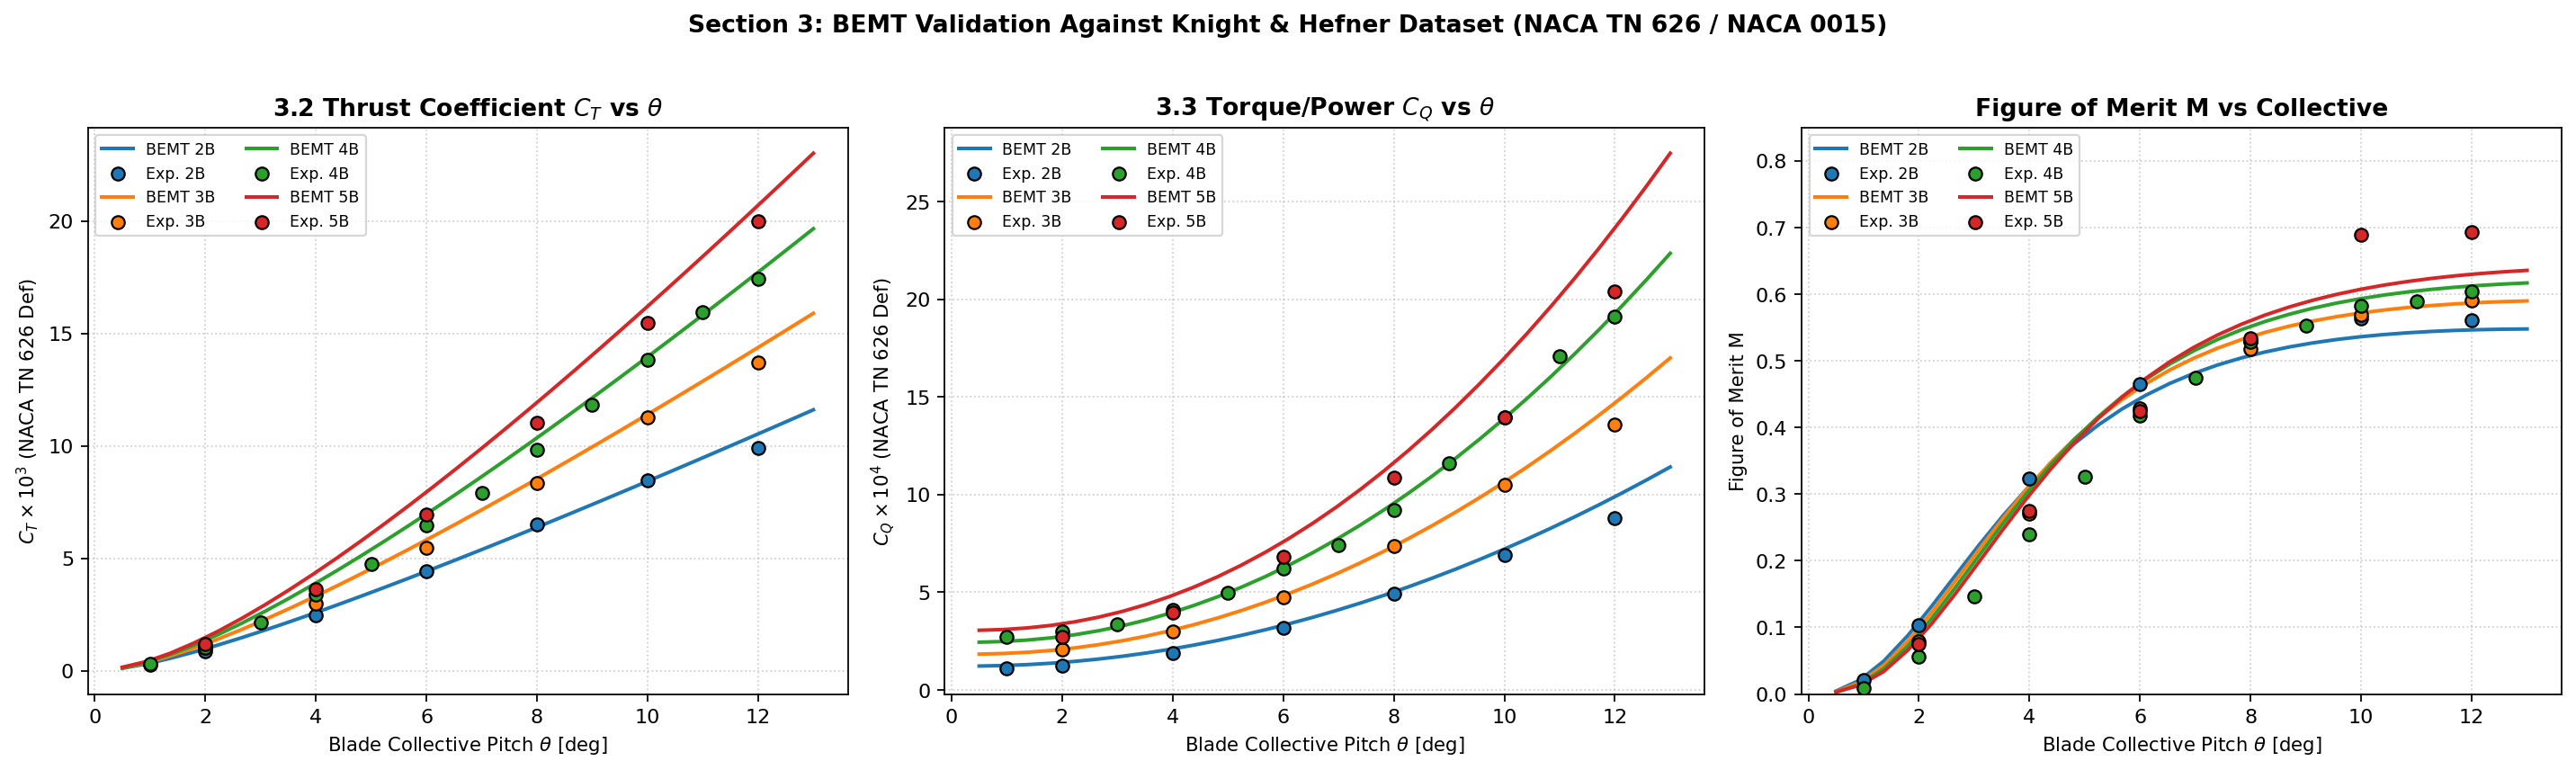

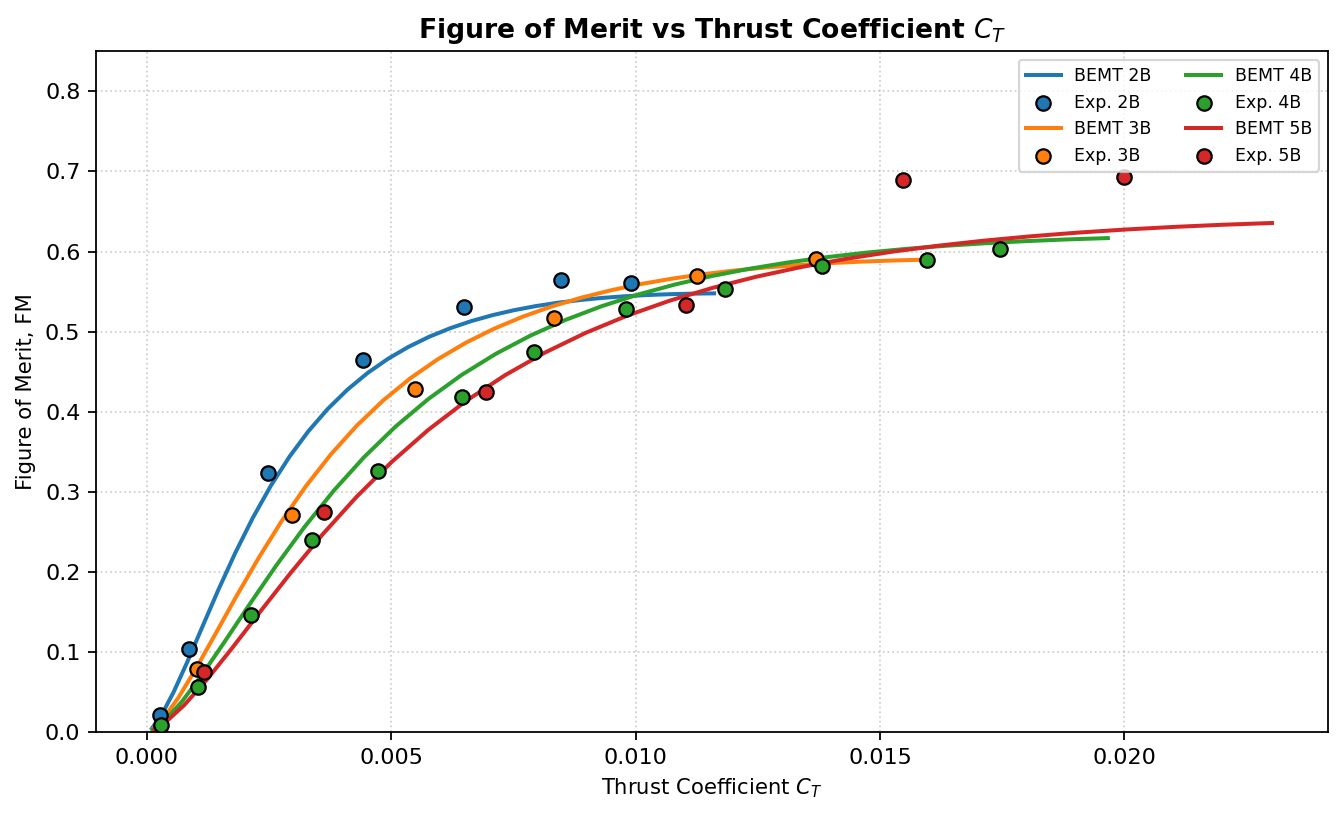

Configuration,CT RMSE,CT MAPE [%],CQ RMSE,CQ MAPE [%],FM RMSE,FM MAPE [%]
2 Blades,0.000252,6.63%,0.000046,8.60%,0.0175,6.49%
3 Blades,0.000363,7.29%,0.000047,2.54%,0.0241,8.87%
4 Blades,0.000436,13.12%,0.000027,3.30%,0.0398,24.22%
5 Blades,0.000765,12.83%,0.000192,17.35%,0.0481,9.44%


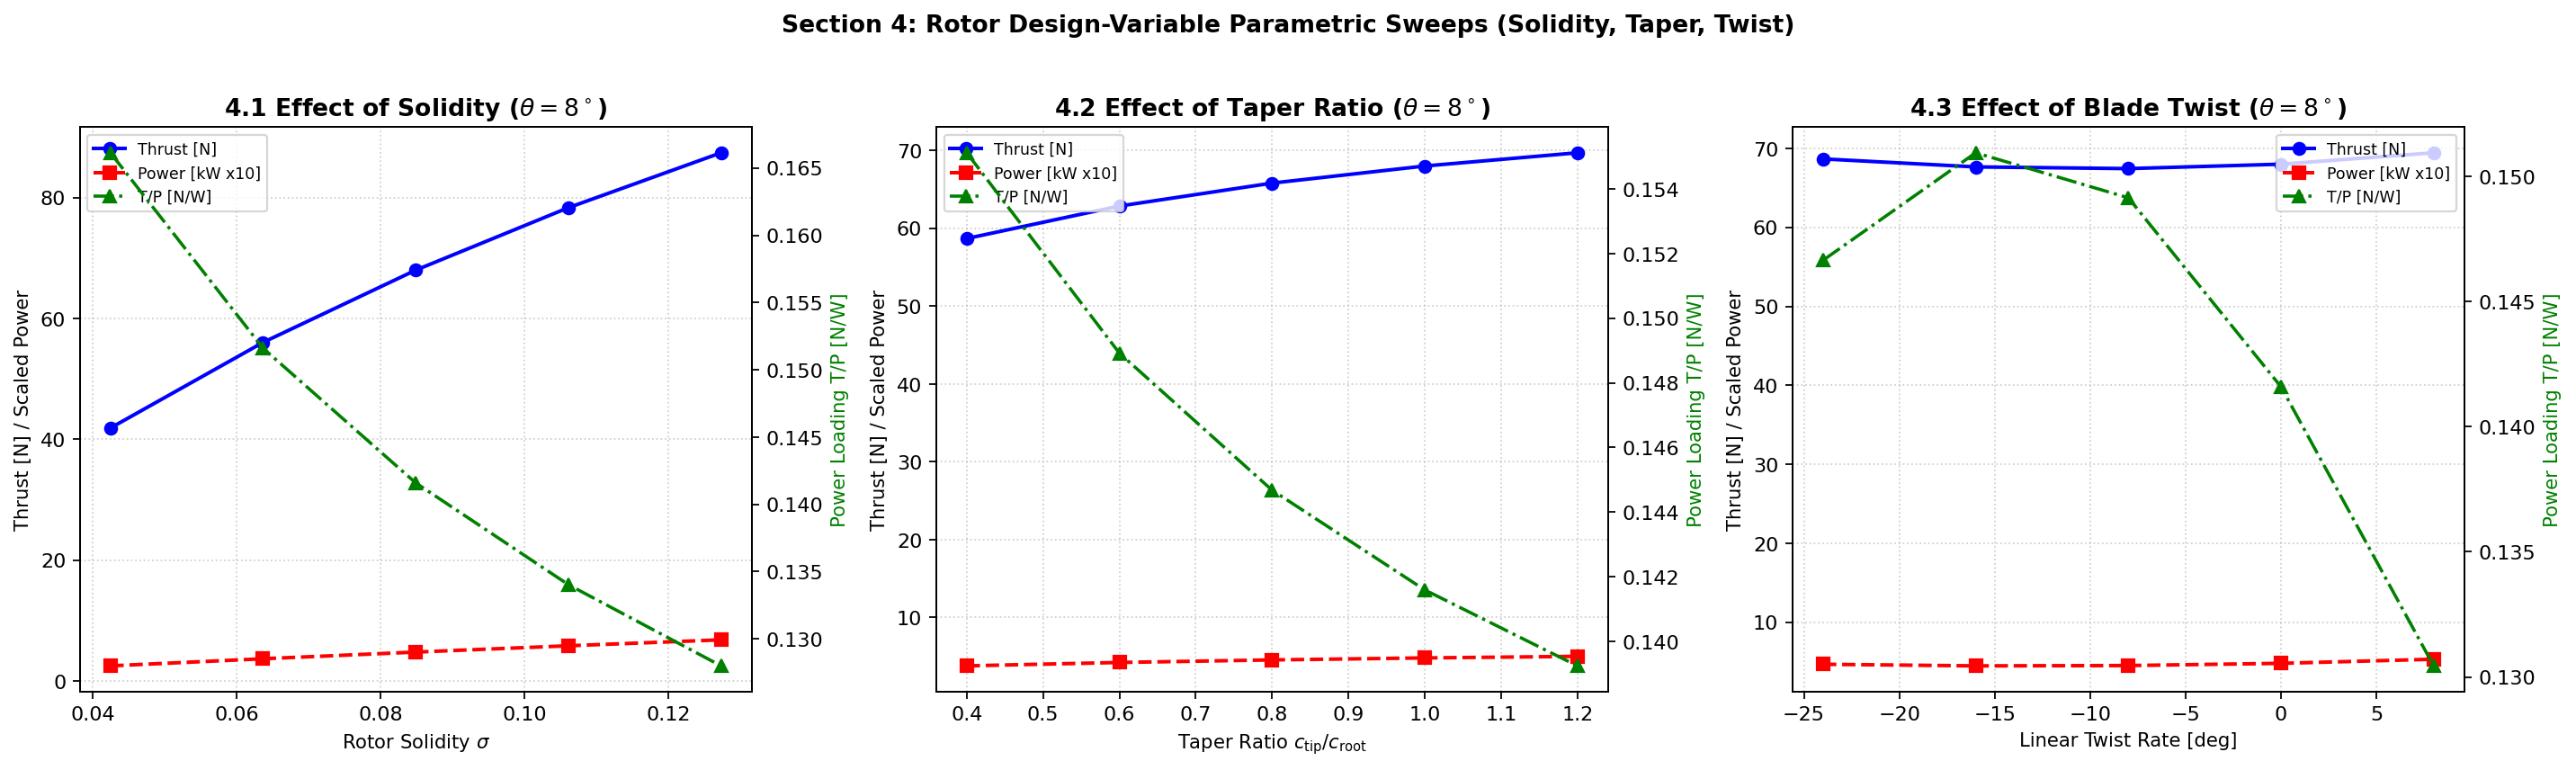

In [4]:
# ==============================================================================
# CELL 3: TASK 3 & 4 - BEMT VALIDATION & DESIGN VARIABLE STUDY
# Calls main Cell 1 aeromechanics solver (run_bemt_solver)
# Airfoil equations: Cl = 5.75 * alpha, Cd = 0.0113 + 1.25 * alpha^2
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# ------------------------------------------------------------------------------
# 1. KNIGHT & HEFNER (NACA TN 626) EXPERIMENTAL DATASET (TABLES I - IV)
# ------------------------------------------------------------------------------
knight_exp = {
    2: {
        'theta_deg': np.array([1.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0]),
        'CT_naca': np.array([0.00028, 0.000873, 0.00248, 0.00442, 0.00650, 0.00847, 0.00990]),
        'CQ_naca': np.array([0.000111, 0.000125, 0.000191, 0.000316, 0.000494, 0.000691, 0.000878])
    },
    3: {
        'theta_deg': np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0]),
        'CT_naca': np.array([0.00102, 0.00298, 0.00548, 0.00833, 0.01125, 0.01370]),
        'CQ_naca': np.array([0.000206, 0.000300, 0.000474, 0.000735, 0.001048, 0.001357])
    },
    4: {
        'theta_deg': np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]),
        'CT_naca': np.array([0.000287, 0.001042, 0.00214, 0.00338, 0.00473, 0.00645, 0.00792, 0.00981, 0.01182, 0.01382, 0.01596, 0.01745]),
        'CQ_naca': np.array([0.000274, 0.000300, 0.000338, 0.000410, 0.000499, 0.000620, 0.000743, 0.000920, 0.001162, 0.001395, 0.001710, 0.001910])
    },
    5: {
        'theta_deg': np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0]),
        'CT_naca': np.array([0.001181, 0.00362, 0.00694, 0.01103, 0.01548, 0.02000]),
        'CQ_naca': np.array([0.000270, 0.000396, 0.000680, 0.001086, 0.001397, 0.002040])
    }
}

# ------------------------------------------------------------------------------
# 2. KNIGHT AIRFOIL CLASS EVALUATING MILESTONE 1 EQUATIONS
# ------------------------------------------------------------------------------
class KnightAnalyticalAirfoil:
    """
    Sectional polar using exact milestone equations:
    Cl(alpha) = 5.75 * alpha
    Cd(alpha) = 0.0113 + 1.25 * alpha^2 (alpha in radians)
    """
    def __init__(self):
        self.airfoil_name = "NACA 0015 (Knight & Hefner Equations)"
        self.alpha_stall_deg = 14.0
        self.cl_max = 5.75 * np.radians(14.0)

    def evaluate(self, alpha_rad, re_arr, mach_arr):
        cl = 5.75 * alpha_rad
        cd = 0.0113 + 1.25 * (alpha_rad ** 2)

        alpha_deg = np.degrees(alpha_rad)
        valid_mask = (alpha_deg >= -14.0) & (alpha_deg <= 14.0)
        cl_stall = (self.cl_max * 0.95) * np.sin(2.0 * alpha_rad)
        cd_stall = 0.0113 + 1.25 * (np.sin(alpha_rad) ** 2)

        cl = np.where(valid_mask, cl, cl_stall)
        cd = np.where(valid_mask, cd, cd_stall)

        beta = np.sqrt(np.maximum(0.20, 1.0 - np.clip(mach_arr, 0.0, 0.88)**2))
        return cl / beta, cd / beta, valid_mask

af_knight = KnightAnalyticalAirfoil()

# Rotor dimensions from Milestone 1 prompt
R_k = 0.762        # Radius [m]
r_root_k = 0.125   # Root cutout [m]
c_k = 0.0508       # Chord [m]
rpm_k = 960.0      # RPM
rho_val = 1.225
a_sound_val = 340.3
mu_val = 1.789e-5
A_disk_k = np.pi * (R_k ** 2)
omega_k = rpm_k * 2.0 * np.pi / 60.0
v_tip_k = omega_k * R_k

# ------------------------------------------------------------------------------
# 3. RUN BEMT SWEEP WITH MAIN SOLVER (run_bemt_solver)
# ------------------------------------------------------------------------------
theta_sweep = np.linspace(0.5, 13.0, 30)
sim_val = {}

for nb in [2, 3, 4, 5]:
    ct_list, cq_list, fm_list = [], [], []
    for th in theta_sweep:
        # Directly call Cell 1 BEMT engine
        res = run_bemt_solver(
            radius=R_k,
            root_cutout=r_root_k,
            num_blades=nb,
            c_root=c_k,
            taper=1.0,
            pitch_75_deg=th,
            twist_deg=0.0,
            rpm=rpm_k,
            v_axial_ms=0.0,
            airfoil=af_knight,
            rho=rho_val,
            a_sound=a_sound_val,
            mu=mu_val,
            num_elements=40
        )

        # NACA TN 626 coefficients (includes 1/2 factor)
        ct_naca = res.thrust_N / (0.5 * rho_val * A_disk_k * (v_tip_k ** 2))
        cq_naca = res.torque_Nm / (0.5 * rho_val * A_disk_k * (v_tip_k ** 2) * R_k)
        fm = (0.5 * (ct_naca ** 1.5) / max(cq_naca, 1e-7)) if (ct_naca > 0 and cq_naca > 0) else 0.0

        ct_list.append(ct_naca)
        cq_list.append(cq_naca)
        fm_list.append(fm)

    sim_val[nb] = {
        'CT_naca': np.array(ct_list),
        'CQ_naca': np.array(cq_list),
        'FM': np.array(fm_list)
    }

# ------------------------------------------------------------------------------
# 4. ERROR METRIC QUANTIFICATION (RMSE & MAPE)
# ------------------------------------------------------------------------------
error_metrics = []
for nb in [2, 3, 4, 5]:
    th_e = knight_exp[nb]['theta_deg']
    ct_e = knight_exp[nb]['CT_naca']
    cq_e = knight_exp[nb]['CQ_naca']
    fm_e = 0.5 * (ct_e ** 1.5) / cq_e

    ct_interp = np.interp(th_e, theta_sweep, sim_val[nb]['CT_naca'])
    cq_interp = np.interp(th_e, theta_sweep, sim_val[nb]['CQ_naca'])
    fm_interp = np.interp(th_e, theta_sweep, sim_val[nb]['FM'])

    rmse_ct = np.sqrt(np.mean((ct_interp - ct_e) ** 2))
    mape_ct = np.mean(np.abs((ct_interp - ct_e) / ct_e)) * 100.0

    rmse_cq = np.sqrt(np.mean((cq_interp - cq_e) ** 2))
    mape_cq = np.mean(np.abs((cq_interp - cq_e) / cq_e)) * 100.0

    rmse_fm = np.sqrt(np.mean((fm_interp - fm_e) ** 2))
    mape_fm = np.mean(np.abs((fm_interp - fm_e) / fm_e)) * 100.0

    error_metrics.append({
        'Configuration': f'{nb} Blades',
        'CT RMSE': f'{rmse_ct:.6f}',
        'CT MAPE [%]': f'{mape_ct:.2f}%',
        'CQ RMSE': f'{rmse_cq:.6f}',
        'CQ MAPE [%]': f'{mape_cq:.2f}%',
        'FM RMSE': f'{rmse_fm:.4f}',
        'FM MAPE [%]': f'{mape_fm:.2f}%'
    })

# ------------------------------------------------------------------------------
# 5. VALIDATION PLOTS (SECTION 3.2 & 3.3)
# ------------------------------------------------------------------------------
fig_val, axes_v = plt.subplots(1, 3, figsize=(18, 5.2), dpi=160)
colors_b = {2: '#1f77b4', 3: '#ff7f0e', 4: '#2ca02c', 5: '#d62728'}

for nb in [2, 3, 4, 5]:
    col = colors_b[nb]
    th_e = knight_exp[nb]['theta_deg']
    ct_e = knight_exp[nb]['CT_naca']
    cq_e = knight_exp[nb]['CQ_naca']
    fm_e = 0.5 * (ct_e ** 1.5) / cq_e

    # 3.2 Thrust Coefficient vs Pitch
    axes_v[0].plot(theta_sweep, sim_val[nb]['CT_naca'] * 1e3, '-', color=col, lw=1.8, label=f'BEMT {nb}B')
    axes_v[0].scatter(th_e, ct_e * 1e3, color=col, edgecolor='k', s=42, zorder=5, label=f'Exp. {nb}B')

    # 3.3 Torque Coefficient vs Pitch
    axes_v[1].plot(theta_sweep, sim_val[nb]['CQ_naca'] * 1e4, '-', color=col, lw=1.8, label=f'BEMT {nb}B')
    axes_v[1].scatter(th_e, cq_e * 1e4, color=col, edgecolor='k', s=42, zorder=5, label=f'Exp. {nb}B')

    # Figure of Merit M vs Pitch
    axes_v[2].plot(theta_sweep, sim_val[nb]['FM'], '-', color=col, lw=1.8, label=f'BEMT {nb}B')
    axes_v[2].scatter(th_e, fm_e, color=col, edgecolor='k', s=42, zorder=5, label=f'Exp. {nb}B')

axes_v[0].set_xlabel(r'Blade Collective Pitch $\theta$ [deg]', fontsize=9.5)
axes_v[0].set_ylabel(r'$C_T \times 10^3$ (NACA TN 626 Def)', fontsize=9.5)
axes_v[0].set_title(r'3.2 Thrust Coefficient $C_T$ vs $\theta$', fontweight='bold')
axes_v[0].grid(True, ls=':', alpha=0.6)
axes_v[0].legend(fontsize=7.8, ncol=2)

axes_v[1].set_xlabel(r'Blade Collective Pitch $\theta$ [deg]', fontsize=9.5)
axes_v[1].set_ylabel(r'$C_Q \times 10^4$ (NACA TN 626 Def)', fontsize=9.5)
axes_v[1].set_title(r'3.3 Torque/Power $C_Q$ vs $\theta$', fontweight='bold')
axes_v[1].grid(True, ls=':', alpha=0.6)
axes_v[1].legend(fontsize=7.8, ncol=2)

axes_v[2].set_xlabel(r'Blade Collective Pitch $\theta$ [deg]', fontsize=9.5)
axes_v[2].set_ylabel('Figure of Merit M', fontsize=9.5)
axes_v[2].set_ylim(0.0, 0.85)
axes_v[2].set_title('Figure of Merit M vs Collective', fontweight='bold')
axes_v[2].grid(True, ls=':', alpha=0.6)
axes_v[2].legend(fontsize=7.8, ncol=2)

plt.suptitle('Section 3: BEMT Validation Against Knight & Hefner Dataset (NACA TN 626 / NACA 0015)', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
plt.close(fig_val)

# 3.3b Figure of Merit over the thrust range
fig_fm, ax = plt.subplots(figsize=(8.5, 5.2), dpi=160)

for nb in [2, 3, 4, 5]:
    ct_bemt, fm_bemt = sim_val[nb]['CT_naca'], sim_val[nb]['FM']
    ct_exp, cq_exp = knight_exp[nb]['CT_naca'], knight_exp[nb]['CQ_naca']
    fm_exp = 0.5 * ct_exp**1.5 / cq_exp

    ax.plot(ct_bemt, fm_bemt, '-', lw=1.8, label=f'BEMT {nb}B')
    ax.scatter(ct_exp, fm_exp, s=42, edgecolor='k', zorder=5, label=f'Exp. {nb}B')

ax.set_xlabel(r'Thrust Coefficient $C_T$', fontsize=9.5)
ax.set_ylabel('Figure of Merit, FM', fontsize=9.5)
ax.set_title(r'Figure of Merit vs Thrust Coefficient $C_T$', fontweight='bold')
ax.set_ylim(0.0, 0.85)
ax.grid(True, ls=':', alpha=0.6)
ax.legend(fontsize=7.8, ncol=2)

plt.tight_layout()
plt.show()
plt.close(fig_fm)

display(HTML('<h4>Section 3.4 Error Metric Summary (BEMT vs NACA TN 626 Exp. Data)</h4>'))
display(HTML(pd.DataFrame(error_metrics).to_html(index=False, classes='table table-sm table-striped table-bordered')))

# ------------------------------------------------------------------------------
# 6. SECTION 4: DESIGN-VARIABLE STUDY
# ------------------------------------------------------------------------------
th_base = 8.0 # deg
nb_base = 4
taper_base = 1.0
twist_base = 0.0

# 4.1 Solidity / Blade Number Variation
nb_vals = [2, 3, 4, 5, 6]
sol_T, sol_P, sol_TP = [], [], []
for nb in nb_vals:
    r = run_bemt_solver(R_k, r_root_k, nb, c_k, taper_base, th_base, twist_base, rpm_k, 0.0, af_knight, rho_val, a_sound_val, mu_val)
    sol_T.append(r.thrust_N)
    sol_P.append(r.power_kW)
    sol_TP.append(r.thrust_N / max(r.power_kW * 1000.0, 1.0))

# 4.2 Taper Ratio Variation
taper_vals = [0.4, 0.6, 0.8, 1.0, 1.2]
taper_T, taper_P, taper_TP = [], [], []
for tr in taper_vals:
    c_root_mod = (2.0 * c_k) / (1.0 + tr)
    r = run_bemt_solver(R_k, r_root_k, nb_base, c_root_mod, tr, th_base, twist_base, rpm_k, 0.0, af_knight, rho_val, a_sound_val, mu_val)
    taper_T.append(r.thrust_N)
    taper_P.append(r.power_kW)
    taper_TP.append(r.thrust_N / max(r.power_kW * 1000.0, 1.0))

# 4.3 Linear Twist Variation
twist_vals = [-24.0, -16.0, -8.0, 0.0, 8.0]
twist_T, twist_P, twist_TP = [], [], []
for tw in twist_vals:
    r = run_bemt_solver(R_k, r_root_k, nb_base, c_k, taper_base, th_base, tw, rpm_k, 0.0, af_knight, rho_val, a_sound_val, mu_val)
    twist_T.append(r.thrust_N)
    twist_P.append(r.power_kW)
    twist_TP.append(r.thrust_N / max(r.power_kW * 1000.0, 1.0))

fig_dv, axes_d = plt.subplots(1, 3, figsize=(18, 5.2), dpi=160)

# 4.1 Solidity Plot
solidities = [(nb * c_k) / (np.pi * R_k) for nb in nb_vals]
ax1 = axes_d[0]
ax1.plot(solidities, sol_T, 'b-o', lw=1.8, label='Thrust [N]')
ax1.plot(solidities, np.array(sol_P) * 10.0, 'r--s', lw=1.8, label='Power [kW x10]')
ax1_t = ax1.twinx()
ax1_t.plot(solidities, sol_TP, 'g-.^', lw=1.6, label='T/P [N/W]')
ax1.set_xlabel(r'Rotor Solidity $\sigma$', fontsize=9.5)
ax1.set_ylabel('Thrust [N] / Scaled Power', fontsize=9.5)
ax1_t.set_ylabel('Power Loading T/P [N/W]', color='g', fontsize=9.5)
ax1.set_title(r'4.1 Effect of Solidity ($\theta=8^\circ$)', fontweight='bold')
ax1.grid(True, ls=':', alpha=0.6)
lines1, labels1 = ax1.get_legend_handles_labels()
lines1_t, labels1_t = ax1_t.get_legend_handles_labels()
ax1.legend(lines1 + lines1_t, labels1 + labels1_t, fontsize=7.8, loc='upper left')

# 4.2 Taper Plot
ax2 = axes_d[1]
ax2.plot(taper_vals, taper_T, 'b-o', lw=1.8, label='Thrust [N]')
ax2.plot(taper_vals, np.array(taper_P) * 10.0, 'r--s', lw=1.8, label='Power [kW x10]')
ax2_t = ax2.twinx()
ax2_t.plot(taper_vals, taper_TP, 'g-.^', lw=1.6, label='T/P [N/W]')
ax2.set_xlabel(r'Taper Ratio $c_{\mathrm{tip}}/c_{\mathrm{root}}$', fontsize=9.5)
ax2.set_ylabel('Thrust [N] / Scaled Power', fontsize=9.5)
ax2_t.set_ylabel('Power Loading T/P [N/W]', color='g', fontsize=9.5)
ax2.set_title(r'4.2 Effect of Taper Ratio ($\theta=8^\circ$)', fontweight='bold')
ax2.grid(True, ls=':', alpha=0.6)
lines2, labels2 = ax2.get_legend_handles_labels()
lines2_t, labels2_t = ax2_t.get_legend_handles_labels()
ax2.legend(lines2 + lines2_t, labels2 + labels2_t, fontsize=7.8, loc='upper left')

# 4.3 Twist Plot
ax3 = axes_d[2]
ax3.plot(twist_vals, twist_T, 'b-o', lw=1.8, label='Thrust [N]')
ax3.plot(twist_vals, np.array(twist_P) * 10.0, 'r--s', lw=1.8, label='Power [kW x10]')
ax3_t = ax3.twinx()
ax3_t.plot(twist_vals, twist_TP, 'g-.^', lw=1.6, label='T/P [N/W]')
ax3.set_xlabel('Linear Twist Rate [deg]', fontsize=9.5)
ax3.set_ylabel('Thrust [N] / Scaled Power', fontsize=9.5)
ax3_t.set_ylabel('Power Loading T/P [N/W]', color='g', fontsize=9.5)
ax3.set_title(r'4.3 Effect of Blade Twist ($\theta=8^\circ$)', fontweight='bold')
ax3.grid(True, ls=':', alpha=0.6)
lines3, labels3 = ax3.get_legend_handles_labels()
lines3_t, labels3_t = ax3_t.get_legend_handles_labels()
ax3.legend(lines3 + lines3_t, labels3 + labels3_t, fontsize=7.8, loc='upper right')

plt.suptitle('Section 4: Rotor Design-Variable Parametric Sweeps (Solidity, Taper, Twist)', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
plt.close(fig_dv)